In [ ]:
import pandas as pd
import numpy as np
import os
import re

# ============================================================
# 0. 파일 경로
# ============================================================

STOCK_FILE = "/content/data_2509.csv"

RENTAL_FILE = "/content/서울특별시 공공자전거 이용정보(시간대별)_202509.csv"

STATION_FILE = "/content/공공자전거 대여소 정보(25.6월 기준).xlsx"


# ============================================================
# 1. 파일 존재 확인
# ============================================================

for file in [STOCK_FILE, RENTAL_FILE, STATION_FILE]:
    print(file, "->", os.path.exists(file))


# ============================================================
# 2. CSV 인코딩 자동 읽기
# ============================================================

def read_csv_auto(path, **kwargs):

    encodings = [
        "utf-8-sig",
        "utf-8",
        "cp949",
        "euc-kr"
    ]

    for enc in encodings:
        try:
            df = pd.read_csv(
                path,
                encoding=enc,
                **kwargs
            )

            print(f"[OK] {os.path.basename(path)}")
            print(f"encoding = {enc}")

            return df

        except UnicodeDecodeError:
            continue

    raise ValueError(
        f"파일 인코딩을 읽지 못했습니다: {path}"
    )


# ============================================================
# 3. 컬럼명 자동 찾기 함수
# ============================================================

def normalize_col(x):

    return (
        str(x)
        .replace(" ", "")
        .replace("_", "")
        .replace("-", "")
        .lower()
    )


def find_column(df, candidates):

    normalized = {
        normalize_col(col): col
        for col in df.columns
    }

    # 완전 일치
    for candidate in candidates:

        key = normalize_col(candidate)

        if key in normalized:
            return normalized[key]

    # 부분 일치
    for candidate in candidates:

        key = normalize_col(candidate)

        for ncol, original in normalized.items():

            if key in ncol:
                return original

    return None


# ============================================================
# 4. 데이터 읽기
# ============================================================

print("\n===== RENTAL DATA =====")

rental = read_csv_auto(
    RENTAL_FILE,
    low_memory=False
)

print(rental.columns.tolist())
print(rental.head())


print("\n===== STOCK DATA =====")

stock = read_csv_auto(
    STOCK_FILE,
    low_memory=False
)

print(stock.columns.tolist())
print(stock.head())


print("\n===== STATION DATA =====")

xls = pd.ExcelFile(STATION_FILE)

print("Sheets:", xls.sheet_names)

# 첫 번째 sheet 우선 사용
station = pd.read_excel(
    STATION_FILE,
    sheet_name=xls.sheet_names[0]
)

print(station.columns.tolist())
print(station.head())


# ============================================================
# 5. RENTAL DATA 컬럼 찾기
# ============================================================

rental_station_col = find_column(
    rental,
    [
        "대여소번호",
        "대여소 번호",
        "대여소ID"
    ]
)

rental_date_col = find_column(
    rental,
    [
        "대여일자",
        "대여일시",
        "대여날짜"
    ]
)

rental_hour_col = find_column(
    rental,
    [
        "대여시간",
        "대여 시간",
        "시간"
    ]
)

rental_count_col = find_column(
    rental,
    [
        "이용건수",
        "대여건수",
        "건수"
    ]
)


print("\n===== RENTAL COLUMNS FOUND =====")

print("station :", rental_station_col)
print("date    :", rental_date_col)
print("hour    :", rental_hour_col)
print("count   :", rental_count_col)


# ============================================================
# 6. Observed Demand 생성
# ============================================================

if rental_station_col is None:
    raise ValueError("대여량 데이터에서 대여소 번호 컬럼을 찾지 못함")

if rental_date_col is None:
    raise ValueError("대여량 데이터에서 날짜 컬럼을 찾지 못함")

if rental_count_col is None:
    raise ValueError("대여량 데이터에서 이용건수 컬럼을 찾지 못함")


rental[rental_date_col] = pd.to_datetime(
    rental[rental_date_col],
    errors="coerce"
)


# 날짜
rental["date"] = rental[rental_date_col].dt.date


# 시간
if rental_hour_col is not None:

    rental["hour"] = pd.to_numeric(
        rental[rental_hour_col],
        errors="coerce"
    )

else:

    rental["hour"] = rental[
        rental_date_col
    ].dt.hour


# 이용건수
rental["observed_demand"] = pd.to_numeric(
    rental[rental_count_col],
    errors="coerce"
).fillna(0)


observed = (
    rental
    .groupby(
        [
            rental_station_col,
            "date",
            "hour"
        ],
        as_index=False
    )["observed_demand"]
    .sum()
)


observed = observed.rename(
    columns={
        rental_station_col: "station_id"
    }
)


print("\n===== OBSERVED DEMAND =====")

print(observed.head())
print("rows =", len(observed))

# ============================================================
# 7~8. STOCK DATA 처리 - 실제 파일 컬럼 기준
# ============================================================

print("\n===== STOCK 실제 컬럼 =====")
print(stock.columns.tolist())


# ------------------------------------------------------------
# 실제 컬럼명 지정
# ------------------------------------------------------------

stock_station_col = "대여소번호"
stock_date_col = "일시"
stock_hour_col = "시간대"
stock_available_col = "거치대수량"


print("\n===== STOCK COLUMNS =====")
print("station   :", stock_station_col)
print("date      :", stock_date_col)
print("hour      :", stock_hour_col)
print("available :", stock_available_col)


# ============================================================
# 날짜 처리
# ============================================================

stock["date"] = pd.to_datetime(
    stock[stock_date_col],
    errors="coerce"
).dt.date


# ============================================================
# 시간 처리
# ============================================================

# 예:
# 8
# 08
# 8시
# 08시
# 모두 숫자 8로 변환
stock["hour"] = pd.to_numeric(
    stock[stock_hour_col]
    .astype(str)
    .str.extract(r"(\d{1,2})")[0],
    errors="coerce"
)


# ============================================================
# 대여가능 자전거 수
# ============================================================

stock["available_bikes"] = pd.to_numeric(
    stock[stock_available_col],
    errors="coerce"
)


# ============================================================
# Stockout proxy
# available bikes = 0 → stockout
# ============================================================

stock["stockout"] = (
    stock["available_bikes"] == 0
).astype(int)


# ============================================================
# station × date × hour 단위로 정리
# ============================================================

stock_hourly = (
    stock
    .groupby(
        [
            stock_station_col,
            "date",
            "hour"
        ],
        as_index=False
    )
    .agg(
        available_bikes=(
            "available_bikes",
            "mean"
        ),
        stockout=(
            "stockout",
            "max"
        )
    )
)


stock_hourly = stock_hourly.rename(
    columns={
        stock_station_col: "station_id"
    }
)


# ============================================================
# 확인
# ============================================================

print("\n===== STOCK HOURLY =====")
print(stock_hourly.head(10))

print("\n행 개수:")
print(len(stock_hourly))

print("\n날짜 범위:")
print(
    stock_hourly["date"].min(),
    "~",
    stock_hourly["date"].max()
)

print("\n시간 범위:")
print(
    stock_hourly["hour"].min(),
    "~",
    stock_hourly["hour"].max()
)

print("\nStockout 분포:")
print(
    stock_hourly["stockout"].value_counts()
)

print("\n결측치:")
print(
    stock_hourly.isna().sum()
)


# ============================================================
# 9. station_id 형식 통일
# ============================================================

def clean_station_id(series):

    return (
        series
        .astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )


observed["station_id"] = clean_station_id(
    observed["station_id"]
)

stock_hourly["station_id"] = clean_station_id(
    stock_hourly["station_id"]
)


# ============================================================
# 10. RENTAL + STOCK JOIN
# ============================================================

master = observed.merge(
    stock_hourly,
    on=[
        "station_id",
        "date",
        "hour"
    ],
    how="left"
)


print("\n===== RENTAL + STOCK =====")

print(master.head())

print(
    "stock match failure rate =",
    master["available_bikes"].isna().mean()
)


# ============================================================
# STATION FILE 헤더 복원
# ============================================================

import pandas as pd

xls = pd.ExcelFile(STATION_FILE)

print("시트:", xls.sheet_names)

# 우선 첫 번째 시트의 앞부분을 헤더 없이 확인
raw = pd.read_excel(
    STATION_FILE,
    sheet_name=xls.sheet_names[0],
    header=None,
    nrows=10
)

print("\n===== RAW FIRST 10 ROWS =====")
print(raw.to_string())

# ============================================================
# 14. 간단한 기본 통계
# ============================================================

print("\n===== BASIC STATISTICS =====")

print(
    master[
        [
            "observed_demand",
            "available_bikes",
            "stockout"
        ]
    ].describe()
)


print("\nStockout rate:")

print(
    master["stockout"].mean()
)


# ============================================================
# 15. CSV 저장
# ============================================================

OUTPUT_FILE = (
    "/content/ttareungi_202509_base.csv"
)

master.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)


print("\nSaved:")
print(OUTPUT_FILE)

/content/data_2509.csv -> False
/content/서울특별시 공공자전거 이용정보(시간대별)_202509.csv -> False
/content/공공자전거 대여소 정보(25.6월 기준).xlsx -> False

===== RENTAL DATA =====


FileNotFoundError: [Errno 2] No such file or directory: '/content/서울특별시 공공자전거 이용정보(시간대별)_202509.csv'

In [ ]:
# ============================================================
# 대여소 정보 정리 + master에 JOIN
# ============================================================

import re

def normalize_name(x):
    # 공백, 줄바꿈, 탭, _, - 전부 제거
    return re.sub(
        r'[\s_\-]+',
        '',
        str(x)
    ).lower()


def find_col(df, keyword_groups):

    for col in df.columns:

        normalized = normalize_name(col)

        for keywords in keyword_groups:

            if all(
                normalize_name(k) in normalized
                for k in keywords
            ):
                return col

    return None


# ============================================================
# 컬럼 다시 찾기
# ============================================================

station_id_col = find_col(
    station,
    [
        ["대여소", "번호"],
        ["대여소", "id"]
    ]
)

capacity_col = find_col(
    station,
    [
        ["거치대", "수"]
    ]
)

lat_col = find_col(
    station,
    [
        ["위도"],
        ["lat"]
    ]
)

lon_col = find_col(
    station,
    [
        ["경도"],
        ["lon"],
        ["longitude"]
    ]
)


print("===== STATION COLUMNS FOUND =====")
print("station_id :", repr(station_id_col))
print("capacity   :", repr(capacity_col))
print("lat        :", repr(lat_col))
print("lon        :", repr(lon_col))


print("\n===== 실제 전체 컬럼 =====")

for i, col in enumerate(station.columns):
    print(i, repr(col))


# ============================================================
# 필요한 대여소 정보 생성
# ============================================================

station_info = pd.DataFrame()

station_info["station_id"] = (
    station[station_id_col]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

station_info["lat"] = pd.to_numeric(
    station[lat_col],
    errors="coerce"
)

station_info["lon"] = pd.to_numeric(
    station[lon_col],
    errors="coerce"
)

if capacity_col is not None:
    station_info["capacity"] = pd.to_numeric(
        station[capacity_col],
        errors="coerce"
    )

station_info = (
    station_info
    .dropna(subset=["station_id", "lat", "lon"])
    .drop_duplicates(subset="station_id")
)


print("\n===== STATION INFO =====")
print(station_info.head())
print("대여소 수:", len(station_info))


# ============================================================
# master와 station_id 형식 통일
# ============================================================

master["station_id"] = (
    master["station_id"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)


# ============================================================
# JOIN
# ============================================================

master = master.merge(
    station_info,
    on="station_id",
    how="left"
)


print("\n===== FINAL MASTER =====")
print(master.head(10))

print("\n행 × 열:")
print(master.shape)

print("\n결측률:")
print(
    master.isna()
    .mean()
    .sort_values(ascending=False)
)

In [ ]:
# ============================================================
# Ttareungi 2025-09 Base Dataset
#
# 1. 시간대별 대여량 -> observed_demand
# 2. 시간대별 대여가능 자전거수 -> available_bikes / stockout
# 3. 대여소 정보 -> lat / lon / capacity(가능한 경우)
#
# 최종 결과:
# /content/ttareungi_202509_base.csv
# ============================================================

import pandas as pd
import numpy as np
import os
import re
import gc


# ============================================================
# 0. 파일 경로
# ============================================================

STOCK_FILE = "/content/data_2509.csv"

RENTAL_FILE = (
    "/content/서울특별시 공공자전거 이용정보(시간대별)_202509.csv"
)

STATION_FILE = (
    "/content/공공자전거 대여소 정보(25.6월 기준).xlsx"
)

OUTPUT_FILE = (
    "/content/ttareungi_202509_base.csv"
)


# ============================================================
# 1. 파일 존재 확인
# ============================================================

print("===== FILE CHECK =====")

for f in [
    STOCK_FILE,
    RENTAL_FILE,
    STATION_FILE
]:

    exists = os.path.exists(f)

    print(
        os.path.basename(f),
        "->",
        exists
    )

    if not exists:
        raise FileNotFoundError(
            f"파일이 없습니다: {f}"
        )


# ============================================================
# 2. 공통 함수
# ============================================================

def normalize_name(x):

    return re.sub(
        r"[\s_\-\(\)]+",
        "",
        str(x)
    ).lower()


def find_col(df, keyword_groups):

    for col in df.columns:

        normalized = normalize_name(col)

        for keywords in keyword_groups:

            if all(
                normalize_name(k) in normalized
                for k in keywords
            ):
                return col

    return None


def clean_station_id(series):

    return (
        series
        .astype(str)
        .str.strip()
        .str.replace(
            r"\.0$",
            "",
            regex=True
        )
    )


def detect_encoding(path):

    for enc in [
        "utf-8-sig",
        "utf-8",
        "cp949",
        "euc-kr"
    ]:

        try:

            pd.read_csv(
                path,
                encoding=enc,
                nrows=5
            )

            print(
                f"[Encoding] "
                f"{os.path.basename(path)} "
                f"-> {enc}"
            )

            return enc

        except UnicodeDecodeError:
            continue

    raise ValueError(
        f"CSV 인코딩 확인 실패: {path}"
    )


def parse_date(series):

    s = (
        series
        .astype(str)
        .str.strip()
        .str.replace(
            r"\.0$",
            "",
            regex=True
        )
    )

    # 일반 날짜 형식
    result = pd.to_datetime(
        s,
        errors="coerce"
    )

    # 20250901 같은 형식
    mask = s.str.fullmatch(
        r"\d{8}"
    )

    if mask.any():

        result.loc[mask] = (
            pd.to_datetime(
                s.loc[mask],
                format="%Y%m%d",
                errors="coerce"
            )
        )

    return result


def parse_hour(series):

    extracted = (
        series
        .astype(str)
        .str.extract(
            r"(\d{1,2})"
        )[0]
    )

    return pd.to_numeric(
        extracted,
        errors="coerce"
    )


# ============================================================
# 3. CSV Encoding
# ============================================================

RENTAL_ENCODING = detect_encoding(
    RENTAL_FILE
)

STOCK_ENCODING = detect_encoding(
    STOCK_FILE
)


# ============================================================
# 4. RENTAL 파일 컬럼 확인
# ============================================================

rental_sample = pd.read_csv(
    RENTAL_FILE,
    encoding=RENTAL_ENCODING,
    nrows=10
)


print("\n===== RENTAL COLUMNS =====")

for i, col in enumerate(
    rental_sample.columns
):
    print(i, repr(col))


rental_station_col = find_col(
    rental_sample,
    [
        ["대여소", "번호"],
        ["대여소", "id"]
    ]
)


rental_date_col = find_col(
    rental_sample,
    [
        ["대여", "일자"],
        ["대여", "일시"],
        ["일자"],
        ["날짜"]
    ]
)


rental_hour_col = find_col(
    rental_sample,
    [
        ["시간대"],
        ["대여", "시간"],
        ["시간"]
    ]
)


rental_count_col = find_col(
    rental_sample,
    [
        ["이용", "건수"],
        ["대여", "건수"],
        ["건수"]
    ]
)


print("\n===== RENTAL COLUMNS FOUND =====")

print(
    "station :",
    repr(rental_station_col)
)

print(
    "date    :",
    repr(rental_date_col)
)

print(
    "hour    :",
    repr(rental_hour_col)
)

print(
    "count   :",
    repr(rental_count_col)
)


if rental_station_col is None:
    raise ValueError(
        "RENTAL 데이터에서 대여소번호를 찾지 못했습니다."
    )

if rental_date_col is None:
    raise ValueError(
        "RENTAL 데이터에서 날짜를 찾지 못했습니다."
    )

if rental_count_col is None:
    raise ValueError(
        "RENTAL 데이터에서 이용건수를 찾지 못했습니다."
    )


# ============================================================
# 5. RENTAL -> OBSERVED DEMAND
# ============================================================

print(
    "\n===== PROCESSING RENTAL DATA ====="
)


CHUNK_SIZE = 300000

rental_results = []


for chunk_num, chunk in enumerate(

    pd.read_csv(
        RENTAL_FILE,
        encoding=RENTAL_ENCODING,
        chunksize=CHUNK_SIZE,
        low_memory=False
    ),

    start=1
):

    dt = parse_date(
        chunk[rental_date_col]
    )


    if rental_hour_col is not None:

        hour = parse_hour(
            chunk[rental_hour_col]
        )

    else:

        hour = dt.dt.hour


    demand = pd.to_numeric(
        chunk[rental_count_col],
        errors="coerce"
    ).fillna(0)


    temp = pd.DataFrame({

        "station_id":
            clean_station_id(
                chunk[rental_station_col]
            ),

        "date":
            dt.dt.date,

        "hour":
            hour,

        "observed_demand":
            demand
    })


    temp = temp.dropna(
        subset=[
            "station_id",
            "date",
            "hour"
        ]
    )


    temp["hour"] = (
        temp["hour"]
        .astype(int)
    )


    grouped = (

        temp

        .groupby(
            [
                "station_id",
                "date",
                "hour"
            ],
            as_index=False
        )

        ["observed_demand"]

        .sum()

    )


    rental_results.append(
        grouped
    )


    print(
        f"Rental chunk "
        f"{chunk_num} 완료"
    )


observed = pd.concat(
    rental_results,
    ignore_index=True
)


observed = (

    observed

    .groupby(
        [
            "station_id",
            "date",
            "hour"
        ],
        as_index=False
    )

    ["observed_demand"]

    .sum()

)


del rental_results

gc.collect()


print(
    "\n===== OBSERVED DEMAND ====="
)

print(
    observed.head(10)
)

print(
    "행:",
    len(observed)
)

print(
    "대여소:",
    observed[
        "station_id"
    ].nunique()
)


# ============================================================
# 6. STOCK DATA
#
# 실제 네 파일에서 확인된 컬럼:
#
# 일시
# 대여소번호
# 대여소명
# 시간대
# 거치대수량
# ============================================================

stock_sample = pd.read_csv(
    STOCK_FILE,
    encoding=STOCK_ENCODING,
    nrows=10
)


print(
    "\n===== STOCK COLUMNS ====="
)

print(
    stock_sample.columns.tolist()
)


STOCK_DATE = "일시"
STOCK_STATION = "대여소번호"
STOCK_HOUR = "시간대"
STOCK_AVAILABLE = "거치대수량"


for col in [

    STOCK_DATE,
    STOCK_STATION,
    STOCK_HOUR,
    STOCK_AVAILABLE

]:

    if col not in stock_sample.columns:

        raise ValueError(
            f"STOCK 데이터에 "
            f"{col} 컬럼이 없습니다."
        )


# ============================================================
# 7. STOCK 처리
# ============================================================

print(
    "\n===== PROCESSING STOCK DATA ====="
)


stock_results = []


for chunk_num, chunk in enumerate(

    pd.read_csv(
        STOCK_FILE,
        encoding=STOCK_ENCODING,
        chunksize=CHUNK_SIZE,
        low_memory=False
    ),

    start=1
):

    dt = parse_date(
        chunk[STOCK_DATE]
    )


    hour = parse_hour(
        chunk[STOCK_HOUR]
    )


    available = pd.to_numeric(
        chunk[STOCK_AVAILABLE],
        errors="coerce"
    )


    temp = pd.DataFrame({

        "station_id":
            clean_station_id(
                chunk[STOCK_STATION]
            ),

        "date":
            dt.dt.date,

        "hour":
            hour,

        "available_bikes":
            available
    })


    temp = temp.dropna(
        subset=[
            "station_id",
            "date",
            "hour",
            "available_bikes"
        ]
    )


    temp["hour"] = (
        temp["hour"]
        .astype(int)
    )


    # 0대 = stockout
    temp["stockout"] = (
        temp["available_bikes"]
        == 0
    ).astype(int)


    # chunk 합칠 때 평균 계산용
    temp[
        "available_sum"
    ] = temp[
        "available_bikes"
    ]


    temp[
        "available_count"
    ] = 1


    grouped = (

        temp

        .groupby(
            [
                "station_id",
                "date",
                "hour"
            ],
            as_index=False
        )

        .agg(

            available_sum=(
                "available_sum",
                "sum"
            ),

            available_count=(
                "available_count",
                "sum"
            ),

            stockout=(
                "stockout",
                "max"
            )

        )

    )


    stock_results.append(
        grouped
    )


    print(
        f"Stock chunk "
        f"{chunk_num} 완료"
    )


stock_hourly = pd.concat(
    stock_results,
    ignore_index=True
)


stock_hourly = (

    stock_hourly

    .groupby(
        [
            "station_id",
            "date",
            "hour"
        ],
        as_index=False
    )

    .agg(

        available_sum=(
            "available_sum",
            "sum"
        ),

        available_count=(
            "available_count",
            "sum"
        ),

        stockout=(
            "stockout",
            "max"
        )

    )

)


stock_hourly[
    "available_bikes"
] = (

    stock_hourly[
        "available_sum"
    ]

    /

    stock_hourly[
        "available_count"
    ]

)


stock_hourly = stock_hourly[
    [
        "station_id",
        "date",
        "hour",
        "available_bikes",
        "stockout"
    ]
]


del stock_results

gc.collect()


print(
    "\n===== STOCK HOURLY ====="
)

print(
    stock_hourly.head(10)
)

print(
    "날짜:",
    stock_hourly[
        "date"
    ].min(),
    "~",
    stock_hourly[
        "date"
    ].max()
)

print(
    "시간:",
    stock_hourly[
        "hour"
    ].min(),
    "~",
    stock_hourly[
        "hour"
    ].max()
)


# ============================================================
# 8. STOCK + RENTAL JOIN
#
# stock 데이터 기준으로 LEFT JOIN
#
# 대여 기록 없는 시간은
# observed_demand = 0
# ============================================================

print(
    "\n===== JOIN STOCK + RENTAL ====="
)


master = stock_hourly.merge(

    observed,

    on=[
        "station_id",
        "date",
        "hour"
    ],

    how="left"

)


master[
    "observed_demand"
] = master[
    "observed_demand"
].fillna(0)


print(
    master.head(10)
)


print(
    "\n현재 행 수:",
    len(master)
)


# ============================================================
# 9. STATION EXCEL 원본으로 읽기
# ============================================================

print(
    "\n===== PROCESSING STATION DATA ====="
)


xls = pd.ExcelFile(
    STATION_FILE
)


# 가장 먼저 위도/경도 들어있는 시트를 찾음
raw = None
found_sheet = None
header_row = None


for sheet in xls.sheet_names:

    temp = pd.read_excel(
        STATION_FILE,
        sheet_name=sheet,
        header=None
    )


    for i in range(
        min(
            30,
            len(temp)
        )
    ):

        row_text = "".join(
            temp.iloc[i]
            .dropna()
            .astype(str)
            .tolist()
        )


        normalized = normalize_name(
            row_text
        )


        if (
            "위도" in normalized
            and
            "경도" in normalized
        ):

            raw = temp
            found_sheet = sheet
            header_row = i

            break


    if raw is not None:
        break


if raw is None:

    raise ValueError(
        "대여소 엑셀에서 "
        "위도/경도 헤더를 찾지 못했습니다."
    )


print(
    "사용 시트:",
    found_sheet
)

print(
    "헤더 행:",
    header_row
)


# ============================================================
# 10. STATION 헤더 복원
# ============================================================

upper_row = (

    raw.iloc[
        header_row - 1
    ]

    if header_row > 0

    else pd.Series(
        [None]
        *
        raw.shape[1]
    )

)


lower_row = raw.iloc[
    header_row
]


def clean_header(x):

    if pd.isna(x):
        return ""

    s = str(x).strip()

    if s.lower() == "nan":
        return ""

    return s


station_columns = []


for j in range(
    raw.shape[1]
):

    upper = clean_header(
        upper_row.iloc[j]
    )

    lower = clean_header(
        lower_row.iloc[j]
    )


    if upper and lower:

        if (
            normalize_name(upper)
            ==
            normalize_name(lower)
        ):

            name = lower

        else:

            name = (
                upper
                + " "
                + lower
            )


    elif lower:

        name = lower


    elif upper:

        name = upper


    else:

        name = (
            f"unknown_{j}"
        )


    station_columns.append(
        name
    )


# 헤더 다음 행부터 실제 데이터
station = raw.iloc[
    header_row + 1:
].copy()


station.columns = (
    station_columns
)


station = (
    station
    .reset_index(
        drop=True
    )
)


print(
    "\n===== STATION 복원 컬럼 ====="
)


for i, col in enumerate(
    station.columns
):

    print(
        i,
        repr(col)
    )


# ============================================================
# 11. 대여소 번호 컬럼 결정
#
# 자동 컬럼명이 계속 문제를 일으켰으므로
# 실제 파일 구조에 맞춰 첫 번째 열을 기본 사용
# ============================================================

station_id_col = (
    station.columns[0]
)


# 위도/경도는 이름으로 탐색
lat_col = find_col(
    station,
    [
        ["위도"],
        ["lat"]
    ]
)


lon_col = find_col(
    station,
    [
        ["경도"],
        ["lon"],
        ["longitude"]
    ]
)


if lat_col is None:

    raise ValueError(
        "대여소 파일에서 "
        "위도 컬럼을 찾지 못했습니다."
    )


if lon_col is None:

    raise ValueError(
        "대여소 파일에서 "
        "경도 컬럼을 찾지 못했습니다."
    )


print(
    "\n===== STATION COLUMN MAPPING ====="
)

print(
    "station_id:",
    repr(station_id_col)
)

print(
    "lat:",
    repr(lat_col)
)

print(
    "lon:",
    repr(lon_col)
)


print(
    "\n대여소번호 샘플:"
)

print(
    station[
        station_id_col
    ].head(10).tolist()
)


# ============================================================
# 12. capacity 컬럼 찾기
#
# LCD / QR 거치대수가 따로 있으면 둘을 합침
# ============================================================

capacity_candidates = []


for col in station.columns:

    n = normalize_name(
        col
    )

    if (
        "거치대" in n
        and
        "수" in n
    ):

        capacity_candidates.append(
            col
        )


print(
    "\n거치대 관련 컬럼:",
    capacity_candidates
)


# LCD / QR 형태를 우선 사용
specific_capacity_cols = [

    col

    for col in capacity_candidates

    if (
        "lcd"
        in normalize_name(col)

        or

        "qr"
        in normalize_name(col)
    )

]


if len(
    specific_capacity_cols
) > 0:

    capacity_columns = (
        specific_capacity_cols
    )

else:

    capacity_columns = (
        capacity_candidates
    )


# ============================================================
# 13. STATION INFO 생성
# ============================================================

station_info = pd.DataFrame()


station_info[
    "station_id"
] = clean_station_id(
    station[
        station_id_col
    ]
)


station_info[
    "lat"
] = pd.to_numeric(
    station[
        lat_col
    ],
    errors="coerce"
)


station_info[
    "lon"
] = pd.to_numeric(
    station[
        lon_col
    ],
    errors="coerce"
)


# capacity가 있으면 계산
if len(
    capacity_columns
) > 0:

    capacity_df = pd.DataFrame()


    for col in capacity_columns:

        capacity_df[col] = (
            pd.to_numeric(
                station[col],
                errors="coerce"
            )
            .fillna(0)
        )


    station_info[
        "capacity"
    ] = capacity_df.sum(
        axis=1
    )


    print(
        "capacity 계산에 사용:",
        capacity_columns
    )


else:

    print(
        "⚠️ 거치대수 컬럼을 "
        "찾지 못했습니다."
    )


# ============================================================
# 14. STATION INFO 정리
# ============================================================

station_info = (

    station_info

    .replace(
        {
            "nan": np.nan,
            "None": np.nan,
            "": np.nan
        }
    )

    .dropna(
        subset=[
            "station_id",
            "lat",
            "lon"
        ]
    )

    .drop_duplicates(
        subset="station_id"
    )

)


print(
    "\n===== STATION INFO ====="
)

print(
    station_info.head(10)
)

print(
    "대여소 수:",
    len(station_info)
)


# ============================================================
# 15. STATION JOIN
# ============================================================

master[
    "station_id"
] = clean_station_id(
    master[
        "station_id"
    ]
)


master = master.merge(

    station_info,

    on="station_id",

    how="left"

)


# ============================================================
# 16. 최종 검증
# ============================================================

print(
    "\n================================"
)

print(
    "FINAL CHECK"
)

print(
    "================================"
)


print(
    "\n행 × 열:",
    master.shape
)


print(
    "\n최종 컬럼:"
)

print(
    master.columns.tolist()
)


print(
    "\n앞 10행:"
)

print(
    master.head(10)
)


print(
    "\n위도 결측률:",
    master[
        "lat"
    ].isna().mean()
)


print(
    "경도 결측률:",
    master[
        "lon"
    ].isna().mean()
)


print(
    "위치정보 매칭률:",
    master[
        "lat"
    ].notna().mean()
)


if (
    "capacity"
    in master.columns
):

    print(
        "capacity 결측률:",
        master[
            "capacity"
        ].isna().mean()
    )


print(
    "\nObserved Demand:"
)

print(
    master[
        "observed_demand"
    ].describe()
)


print(
    "\nAvailable Bikes:"
)

print(
    master[
        "available_bikes"
    ].describe()
)


print(
    "\nStockout:"
)

print(
    master[
        "stockout"
    ].value_counts()
)


print(
    "\nStockout rate:"
)

print(
    master[
        "stockout"
    ].mean()
)


# ============================================================
# 17. 이상값 간단 확인
# ============================================================

print(
    "\n===== DATA QUALITY CHECK ====="
)


print(
    "날짜 범위:",
    master[
        "date"
    ].min(),
    "~",
    master[
        "date"
    ].max()
)


print(
    "시간 범위:",
    master[
        "hour"
    ].min(),
    "~",
    master[
        "hour"
    ].max()
)


print(
    "대여소 수:",
    master[
        "station_id"
    ].nunique()
)


print(
    "Observed demand 음수:",
    (
        master[
            "observed_demand"
        ]
        < 0
    ).sum()
)


print(
    "Available bikes 음수:",
    (
        master[
            "available_bikes"
        ]
        < 0
    ).sum()
)


# ============================================================
# 18. 저장
# ============================================================

master.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)


print(
    "\n================================"
)

print(
    "✅ 기본 분석 데이터 생성 완료"
)

print(
    OUTPUT_FILE
)

print(
    "================================"
)

In [ ]:
# ============================================================
# 2025년 9월 생활인구 30일 전처리 - 오류 대응 버전
#
# /content/Local_people_202509/
#     일별 CSV 30개
#
# 필요한 것만 추출:
# - 시간대구분
# - 집계구코드
# - 총생활인구수
#
# 성별 / 연령별 컬럼은 읽지 않음
#
# 최종:
# 집계구 × 날짜
# ============================================================

import pandas as pd
import numpy as np
import os
import re
import csv
import gc


# ============================================================
# 1. 폴더 찾기
# ============================================================

FOLDER = "/content/Local_people_202509"

if not os.path.isdir(FOLDER):

    # 대소문자가 다를 경우 자동 탐색
    FOLDER = None

    for name in os.listdir("/content"):

        path = os.path.join("/content", name)

        if (
            os.path.isdir(path)
            and
            "localpeople202509"
            in re.sub(r"[\s_\-]", "", name.lower())
        ):
            FOLDER = path
            break


if FOLDER is None:

    raise FileNotFoundError(
        "Local_people_202509 폴더를 찾지 못했습니다."
    )


print("생활인구 폴더:")
print(FOLDER)


# ============================================================
# 2. CSV 30개 찾기
# ============================================================

FILES = []

for root, dirs, filenames in os.walk(FOLDER):

    for filename in filenames:

        if filename.lower().endswith(".csv"):

            FILES.append(
                os.path.join(
                    root,
                    filename
                )
            )


FILES = sorted(FILES)


print("\nCSV 파일 수:", len(FILES))

for f in FILES[:5]:
    print(os.path.basename(f))


if len(FILES) == 0:

    raise FileNotFoundError(
        "CSV 파일이 없습니다."
    )


# ============================================================
# 3. 공통 함수
# ============================================================

def normalize(x):

    x = str(x)

    # 따옴표 제거
    x = x.replace('"', "")
    x = x.replace("'", "")

    # 공백 등 제거
    x = re.sub(
        r"[\s_\-\(\)]",
        "",
        x
    )

    return x.lower()


def detect_encoding(path):

    for enc in [
        "utf-8-sig",
        "utf-8",
        "cp949",
        "euc-kr"
    ]:

        try:

            pd.read_csv(
                path,
                encoding=enc,
                nrows=1,
                quoting=csv.QUOTE_NONE
            )

            return enc

        except Exception:
            continue

    raise ValueError(
        f"Encoding 확인 실패: {path}"
    )


def find_index(columns, keyword_groups):

    for index, col in enumerate(columns):

        c = normalize(col)

        for group in keyword_groups:

            if all(
                normalize(k) in c
                for k in group
            ):

                return index

    return None


# ============================================================
# 4. 시간대 평균 함수
# ============================================================

def time_average(
    df,
    start_hour,
    end_hour,
    output_name
):

    result = (

        df[
            df["hour"].between(
                start_hour,
                end_hour
            )
        ]

        .groupby(
            "area_id",
            as_index=False
        )

        ["population"]

        .mean()

        .rename(
            columns={
                "population":
                    output_name
            }
        )

    )

    return result


# ============================================================
# 5. 전체 날짜 처리
# ============================================================

ALL_DAYS = []

SUCCESS_DAYS = []

FAILED_FILES = []


for file_number, file_path in enumerate(
    FILES,
    start=1
):

    filename = os.path.basename(
        file_path
    )


    # --------------------------------------------------------
    # 날짜 추출
    # --------------------------------------------------------

    match = re.search(
        r"202509\d{2}",
        filename
    )


    if match is None:

        print(
            "⚠️ 날짜 추출 실패:",
            filename
        )

        FAILED_FILES.append(filename)

        continue


    current_date = pd.to_datetime(
        match.group(),
        format="%Y%m%d"
    )


    print(
        f"\n[{file_number:02d}/{len(FILES)}] "
        f"{current_date.date()} 처리 중..."
    )


    try:

        # ====================================================
        # 6. 파일마다 Encoding 확인
        # ====================================================

        encoding = detect_encoding(
            file_path
        )


        # ====================================================
        # 7. 헤더만 읽기
        #
        # QUOTE_NONE을 쓰되
        # 여기서는 실제 컬럼명 대신 위치를 확인
        # ====================================================

        header_df = pd.read_csv(
            file_path,
            encoding=encoding,
            nrows=0,
            quoting=csv.QUOTE_NONE
        )


        raw_columns = list(
            header_df.columns
        )


        # ----------------------------------------------------
        # 필요한 컬럼 위치 탐색
        # ----------------------------------------------------

        hour_idx = find_index(
            raw_columns,
            [
                ["시간대구분"],
                ["시간대"],
                ["시간"]
            ]
        )


        area_idx = find_index(
            raw_columns,
            [
                ["집계구코드"],
                ["집계구", "코드"],
                ["집계구"]
            ]
        )


        pop_idx = find_index(
            raw_columns,
            [
                ["총생활인구수"],
                ["총", "생활인구"],
                ["생활인구수"]
            ]
        )


        print(
            "  시간 컬럼:",
            hour_idx,
            repr(
                raw_columns[hour_idx]
                if hour_idx is not None
                else None
            )
        )

        print(
            "  집계구 컬럼:",
            area_idx,
            repr(
                raw_columns[area_idx]
                if area_idx is not None
                else None
            )
        )

        print(
            "  인구 컬럼:",
            pop_idx,
            repr(
                raw_columns[pop_idx]
                if pop_idx is not None
                else None
            )
        )


        if (
            hour_idx is None
            or
            area_idx is None
            or
            pop_idx is None
        ):

            raise ValueError(
                "필요한 컬럼 위치를 찾지 못함"
            )


        # ====================================================
        # 8. 컬럼 이름 대신 '번호'로 읽기
        #
        # 여기서 usecols 오류를 방지
        # ====================================================

        use_indices = [
            hour_idx,
            area_idx,
            pop_idx
        ]


        HOURLY_PARTS = []


        reader = pd.read_csv(
            file_path,

            encoding=encoding,

            usecols=use_indices,

            chunksize=200000,

            low_memory=False,

            quoting=csv.QUOTE_NONE,

            on_bad_lines="skip"
        )


        # ====================================================
        # 9. Chunk 처리
        # ====================================================

        for chunk in reader:

            # 선택된 컬럼 순서가 원본 순서를 따르므로
            # 위치에 따라 다시 실제 컬럼을 찾아냄

            chunk_columns = list(
                chunk.columns
            )


            # 따옴표를 포함한 실제 컬럼명 대응

            hour_col = None
            area_col = None
            pop_col = None


            for col in chunk_columns:

                c = normalize(col)


                if (
                    hour_col is None
                    and
                    (
                        "시간대구분" in c
                        or
                        "시간대" in c
                    )
                ):
                    hour_col = col


                if (
                    area_col is None
                    and
                    "집계구" in c
                ):
                    area_col = col


                if (
                    pop_col is None
                    and
                    "생활인구" in c
                    and
                    (
                        "총" in c
                        or
                        c == "생활인구수"
                    )
                ):
                    pop_col = col


            if (
                hour_col is None
                or
                area_col is None
                or
                pop_col is None
            ):

                raise ValueError(
                    "Chunk에서 컬럼 매칭 실패"
                )


            temp = pd.DataFrame()


            # ----------------------------------------------
            # 시간
            # ----------------------------------------------

            temp["hour"] = pd.to_numeric(

                chunk[hour_col]
                .astype(str)
                .str.replace(
                    '"',
                    '',
                    regex=False
                )
                .str.extract(
                    r"(\d{1,2})"
                )[0],

                errors="coerce"

            )


            # ----------------------------------------------
            # 집계구 코드
            # ----------------------------------------------

            temp["area_id"] = (

                chunk[area_col]
                .astype(str)
                .str.replace(
                    '"',
                    '',
                    regex=False
                )
                .str.strip()
                .str.replace(
                    r"\.0$",
                    "",
                    regex=True
                )

            )


            # ----------------------------------------------
            # 총생활인구
            # ----------------------------------------------

            temp["population"] = pd.to_numeric(

                chunk[pop_col]
                .astype(str)
                .str.replace(
                    '"',
                    '',
                    regex=False
                )
                .str.strip(),

                errors="coerce"

            )


            # ----------------------------------------------
            # 결측 제거
            # ----------------------------------------------

            temp = temp.dropna(
                subset=[
                    "hour",
                    "area_id",
                    "population"
                ]
            )


            temp["hour"] = (
                temp["hour"]
                .astype(int)
            )


            # 0~23만
            temp = temp[
                temp["hour"].between(
                    0,
                    23
                )
            ]


            # ----------------------------------------------
            # 동일 집계구 × 시간 중복 압축
            # ----------------------------------------------

            temp = (

                temp

                .groupby(
                    [
                        "area_id",
                        "hour"
                    ],
                    as_index=False
                )

                ["population"]

                .sum()

            )


            HOURLY_PARTS.append(
                temp
            )


        # ====================================================
        # 10. 해당 날짜 전체 합치기
        # ====================================================

        if len(HOURLY_PARTS) == 0:

            raise ValueError(
                "읽힌 데이터가 없음"
            )


        day_hourly = pd.concat(
            HOURLY_PARTS,
            ignore_index=True
        )


        day_hourly = (

            day_hourly

            .groupby(
                [
                    "area_id",
                    "hour"
                ],
                as_index=False
            )

            ["population"]

            .sum()

        )


        # ====================================================
        # 11. 필요한 시간대만 계산
        # ====================================================

        # 출근 07~09
        morning = time_average(
            day_hourly,
            7,
            9,
            "morning_population"
        )


        # 낮 10~16
        daytime = time_average(
            day_hourly,
            10,
            16,
            "daytime_population"
        )


        # 퇴근/저녁 17~20
        evening = time_average(
            day_hourly,
            17,
            20,
            "evening_population"
        )


        # 야간 21~23
        night = time_average(
            day_hourly,
            21,
            23,
            "night_population"
        )


        # ====================================================
        # 12. 07~23 평균
        #
        # 새벽 시간은 제외
        # ====================================================

        daily_avg = (

            day_hourly[
                day_hourly["hour"].between(
                    7,
                    23
                )
            ]

            .groupby(
                "area_id",
                as_index=False
            )

            ["population"]

            .mean()

            .rename(
                columns={
                    "population":
                        "daily_avg_population_07_23"
                }
            )

        )


        # ====================================================
        # 13. 결합
        # ====================================================

        day_result = (

            daily_avg

            .merge(
                morning,
                on="area_id",
                how="left"
            )

            .merge(
                daytime,
                on="area_id",
                how="left"
            )

            .merge(
                evening,
                on="area_id",
                how="left"
            )

            .merge(
                night,
                on="area_id",
                how="left"
            )

        )


        day_result.insert(
            1,
            "date",
            current_date
        )


        ALL_DAYS.append(
            day_result
        )


        SUCCESS_DAYS.append(
            current_date
        )


        print(
            f"  ✅ 완료: "
            f"{len(day_result):,}개 집계구"
        )


        del HOURLY_PARTS
        del day_hourly

        gc.collect()


    except Exception as e:

        print(
            "  ❌ 처리 실패:"
        )

        print(
            "  ",
            type(e).__name__,
            ":",
            e
        )

        FAILED_FILES.append(
            filename
        )


# ============================================================
# 14. 결과 확인
# ============================================================

print("\n================================")
print("처리 결과")
print("================================")

print(
    "성공 날짜:",
    len(SUCCESS_DAYS)
)

print(
    "실패 파일:",
    len(FAILED_FILES)
)


if FAILED_FILES:

    for f in FAILED_FILES:
        print(" -", f)


if len(ALL_DAYS) == 0:

    raise ValueError(
        "처리에 성공한 날짜가 없습니다."
    )


# ============================================================
# 15. 30일 합치기
# ============================================================

local_people_clean = pd.concat(
    ALL_DAYS,
    ignore_index=True
)


local_people_clean = (

    local_people_clean

    .sort_values(
        [
            "date",
            "area_id"
        ]
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 16. 품질검사
# ============================================================

print("\n================================")
print("FINAL CHECK")
print("================================")


print(
    "날짜 수:",
    local_people_clean[
        "date"
    ].nunique()
)


print(
    "총 행:",
    len(local_people_clean)
)


print(
    "집계구 수:",
    local_people_clean[
        "area_id"
    ].nunique()
)


print(
    "\n날짜별 집계구 수:"
)


date_counts = (

    local_people_clean

    .groupby(
        "date"
    )

    ["area_id"]

    .nunique()

)


print(
    date_counts
)


print(
    "\n앞 10행:"
)

print(
    local_people_clean.head(10)
)


print(
    "\n결측률:"
)

print(
    local_people_clean
    .isna()
    .mean()
)


# ============================================================
# 17. 저장
# ============================================================

OUTPUT_FILE = (
    "/content/"
    "local_people_202509_preprocessed.csv"
)


local_people_clean.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)


print("\n================================")
print("✅ 전처리 완료")
print(OUTPUT_FILE)
print("================================")

In [ ]:
#원본 데이터 점검
import os
import re
import pandas as pd

FOLDER = "/content/LOCAL_PEOPLE_202509"

result = []

for filename in sorted(os.listdir(FOLDER)):

    if not filename.lower().endswith(".csv"):
        continue

    path = os.path.join(FOLDER, filename)

    match = re.search(r"202509\d{2}", filename)

    if match is None:
        continue

    result.append({
        "date": match.group(),
        "size_MB": round(
            os.path.getsize(path) / 1024**2,
            2
        )
    })

size_check = pd.DataFrame(result)

print(size_check.to_string(index=False))

In [ ]:
import pandas as pd

FILE = "/content/local_people_202509_preprocessed.csv"

df = pd.read_csv(
    FILE,
    dtype={"area_id": str}
)

df["date"] = pd.to_datetime(df["date"])

print("===== FINAL QUALITY CHECK =====")

print("\n총 행:", len(df))
print("날짜 수:", df["date"].nunique())
print("집계구 수:", df["area_id"].nunique())

print(
    "날짜 범위:",
    df["date"].min(),
    "~",
    df["date"].max()
)

# area_id + date 중복
dup = df.duplicated(
    ["area_id", "date"]
).sum()

print("\narea_id + date 중복:", dup)

# 결측치
print("\n컬럼별 결측치 수:")
print(
    df.isna().sum()
)

print("\n컬럼별 결측률:")
print(
    (df.isna().mean() * 100).round(4)
)

# 날짜별 행 수
print("\n날짜별 집계구 수:")
print(
    df.groupby("date")["area_id"]
      .nunique()
)

# 각 area_id가 며칠 등장하는지
print("\narea_id 등장 일수 분포:")
print(
    df.groupby("area_id")
      .size()
      .value_counts()
      .sort_index()
)

In [ ]:
# ============================================================
# 생활인구 공간결합
#
# 집계구 × 날짜
#       ↓
# 따릉이 대여소 500m buffer
#       ↓
# 대여소 × 날짜 생활인구
#
# 이후 따릉이 일별 데이터와 JOIN
# ============================================================

!pip -q install geopandas pyogrio shapely

import pandas as pd
import numpy as np
import geopandas as gpd

import os
import glob
import gc
import math


# ============================================================
# 0. 파일
# ============================================================

POP_FILE = "/content/local_people_202509_preprocessed.csv"

BIKE_FILE = "/content/ttareungi_202509_base.csv"

OUTPUT_POP = (
    "/content/"
    "station_population_202509.csv"
)

OUTPUT_DAILY = (
    "/content/"
    "ttareungi_daily_with_population_202509.csv"
)

BUFFER_M = 500


# ============================================================
# 1. 파일 존재 확인
# ============================================================

for f in [
    POP_FILE,
    BIKE_FILE
]:

    if not os.path.exists(f):

        raise FileNotFoundError(
            f"파일 없음: {f}"
        )


# ============================================================
# 2. 생활인구 데이터
# ============================================================

print("\n================================")
print("1. 생활인구 데이터")
print("================================")


pop = pd.read_csv(
    POP_FILE,
    dtype={
        "area_id": str
    }
)


pop["date"] = pd.to_datetime(
    pop["date"]
)


pop["area_id"] = (
    pop["area_id"]
    .astype(str)
    .str.strip()
    .str.replace(
        r"\.0$",
        "",
        regex=True
    )
)


POP_COLS = [

    "daily_avg_population_07_23",

    "morning_population",

    "daytime_population",

    "evening_population",

    "night_population"

]


for col in POP_COLS:

    pop[col] = pd.to_numeric(
        pop[col],
        errors="coerce"
    )


print(
    "생활인구 행:",
    len(pop)
)

print(
    "집계구:",
    pop["area_id"].nunique()
)

print(
    "날짜:",
    pop["date"].nunique()
)

print(
    pop.head()
)


# ============================================================
# 3. 따릉이 데이터
# ============================================================

print("\n================================")
print("2. 따릉이 데이터")
print("================================")


bike = pd.read_csv(
    BIKE_FILE,
    dtype={
        "station_id": str
    },
    low_memory=False
)


bike["station_id"] = (
    bike["station_id"]
    .astype(str)
    .str.strip()
    .str.replace(
        r"\.0$",
        "",
        regex=True
    )
)


bike["date"] = pd.to_datetime(
    bike["date"]
)


bike["lat"] = pd.to_numeric(
    bike["lat"],
    errors="coerce"
)


bike["lon"] = pd.to_numeric(
    bike["lon"],
    errors="coerce"
)


# 대여소 위치만 1개씩 추출

stations = (

    bike[
        [
            "station_id",
            "lat",
            "lon"
        ]
    ]

    .dropna()

    .drop_duplicates(
        subset="station_id"
    )

    .copy()

)


print(
    "대여소 수:",
    len(stations)
)

print(
    stations.head()
)


# ============================================================
# 4. /content 안의 모든 SHP 찾기
# ============================================================

print("\n================================")
print("3. 집계구 SHP 자동 탐색")
print("================================")


SHP_FILES = glob.glob(

    "/content/집계구shp",

    recursive=True

)


print(
    "발견된 SHP:",
    len(SHP_FILES)
)


for f in SHP_FILES:

    print(
        "-",
        f
    )


if len(SHP_FILES) == 0:

    raise FileNotFoundError(
        """
집계구 SHP 파일이 없습니다.

.shp
.shx
.dbf
.prj

파일을 Colab에 올려주세요.
"""
    )


# ============================================================
# 5. 생활인구 area_id와 가장 잘 맞는 SHP 자동 탐색
# ============================================================

population_ids = set(
    pop["area_id"]
    .dropna()
    .unique()
)


best_shp = None
best_code_col = None
best_overlap = 0
best_match_rate = 0


for shp_path in SHP_FILES:

    print(
        "\n검사:",
        os.path.basename(shp_path)
    )

    try:

        # 속성만 읽음
        attr = gpd.read_file(
            shp_path,
            ignore_geometry=True
        )


        for col in attr.columns:

            values = (

                attr[col]

                .astype(str)

                .str.strip()

                .str.replace(
                    r"\.0$",
                    "",
                    regex=True
                )

            )


            shp_ids = set(
                values.dropna()
            )


            overlap = len(
                population_ids
                &
                shp_ids
            )


            rate = (
                overlap
                /
                len(population_ids)
            )


            if overlap > best_overlap:

                best_overlap = overlap

                best_match_rate = rate

                best_shp = shp_path

                best_code_col = col


    except Exception as e:

        print(
            "  읽기 실패:",
            str(e)[:100]
        )


print("\n================================")

print(
    "선택된 SHP:",
    best_shp
)

print(
    "집계구 코드 컬럼:",
    best_code_col
)

print(
    "일치 집계구:",
    best_overlap,
    "/",
    len(population_ids)
)

print(
    "매칭률:",
    round(
        best_match_rate * 100,
        3
    ),
    "%"
)

print("================================")


# ============================================================
# 매우 중요
#
# 다른 연도의 집계구 경계를 잘못 사용하면
# 여기서 멈춤
# ============================================================

if (
    best_shp is None
    or
    best_match_rate < 0.80
):

    raise ValueError(
        """
생활인구 area_id와 잘 맞는 집계구 SHP를 찾지 못했습니다.

생활인구 CSV와 집계구 경계의 기준연도가
다를 가능성이 있습니다.

매칭률을 확인하고 올바른 집계구 SHP를 사용해야 합니다.
"""
    )


# ============================================================
# 6. 집계구 SHP 실제 로드
# ============================================================

areas = gpd.read_file(
    best_shp
)


areas["area_id"] = (

    areas[
        best_code_col
    ]

    .astype(str)

    .str.strip()

    .str.replace(
        r"\.0$",
        "",
        regex=True
    )

)


# 생활인구에 실제 존재하는 집계구만 유지

areas = areas[
    areas["area_id"].isin(
        population_ids
    )
].copy()


areas = areas[
    [
        "area_id",
        "geometry"
    ]
]


# 동일 area_id가 SHP에 여러 개 있으면 하나로 병합

areas = areas.dissolve(

    by="area_id",

    as_index=False

)


print(
    "\nSHP 집계구:",
    len(areas)
)


# ============================================================
# 7. 좌표계 확인
# ============================================================

print(
    "원본 CRS:",
    areas.crs
)


if areas.crs is None:

    raise ValueError(
        """
집계구 SHP에 CRS 정보가 없습니다.
.prj 파일이 함께 업로드되었는지 확인하세요.
"""
    )


# 서울 미터 단위 좌표계
# EPSG:5179 사용

areas = areas.to_crs(
    epsg=5179
)


# geometry 오류 보정

try:

    areas["geometry"] = (
        areas.geometry.make_valid()
    )

except:

    pass


areas = areas[
    ~areas.geometry.is_empty
].copy()


areas[
    "area_size_m2"
] = areas.geometry.area


# ============================================================
# 8. 따릉이 좌표 → GeoDataFrame
# ============================================================

station_gdf = gpd.GeoDataFrame(

    stations.copy(),

    geometry=gpd.points_from_xy(

        stations["lon"],

        stations["lat"]

    ),

    crs="EPSG:4326"

)


station_gdf = station_gdf.to_crs(
    epsg=5179
)


# ============================================================
# 9. 500m BUFFER
# ============================================================

buffers = station_gdf[
    [
        "station_id",
        "geometry"
    ]
].copy()


buffers[
    "geometry"
] = buffers.geometry.buffer(
    BUFFER_M
)


buffers[
    "buffer_area_m2"
] = buffers.geometry.area


print(
    "\n500m buffer 생성 완료"
)

print(
    "대여소:",
    len(buffers)
)


# ============================================================
# 10. 집계구 × 대여소 BUFFER 교차
# ============================================================

print("\n================================")
print("4. 공간 교차 계산")
print("시간이 조금 걸릴 수 있음")
print("================================")


intersection = gpd.overlay(

    buffers,

    areas,

    how="intersection",

    keep_geom_type=False

)


intersection[
    "overlap_area_m2"
] = intersection.geometry.area


# ============================================================
# 11. 집계구 중 몇 %가 buffer에 들어오는지 계산
# ============================================================

intersection[
    "area_weight"
] = (

    intersection[
        "overlap_area_m2"
    ]

    /

    intersection[
        "area_size_m2"
    ]

)


# floating point 때문에 1을 아주 살짝 넘을 경우 방지

intersection[
    "area_weight"
] = intersection[
    "area_weight"
].clip(
    lower=0,
    upper=1
)


weights = intersection[
    [
        "station_id",
        "area_id",
        "area_weight",
        "overlap_area_m2",
        "buffer_area_m2"
    ]
].copy()


print(
    "대여소-집계구 교차 관계:",
    len(weights)
)


print(
    "\n한 대여소가 평균 몇 개 집계구와 겹치는가:"
)

print(
    weights
    .groupby("station_id")
    ["area_id"]
    .nunique()
    .describe()
)


# ============================================================
# 12. BUFFER 공간 커버리지 계산
#
# buffer 전체 중 집계구 polygon이
# 얼마나 덮는지 검사
# ============================================================

coverage = (

    weights

    .groupby(
        "station_id",
        as_index=False
    )

    .agg(

        covered_area_m2=(
            "overlap_area_m2",
            "sum"
        ),

        buffer_area_m2=(
            "buffer_area_m2",
            "first"
        )

    )

)


coverage[
    "buffer_coverage_ratio"
] = (

    coverage[
        "covered_area_m2"
    ]

    /

    coverage[
        "buffer_area_m2"
    ]

)


print(
    "\nBuffer coverage:"
)

print(
    coverage[
        "buffer_coverage_ratio"
    ].describe()
)


# ============================================================
# 13. 날짜별 생활인구를 대여소 단위로 변환
#
# 메모리를 아끼기 위해
# 30일을 하나씩 처리
# ============================================================

print("\n================================")
print("5. 날짜별 생활인구 공간 가중")
print("================================")


DATES = sorted(
    pop["date"].unique()
)


station_day_results = []


for i, date in enumerate(
    DATES,
    start=1
):

    print(
        f"[{i:02d}/{len(DATES)}] "
        f"{pd.Timestamp(date).date()}"
    )


    day_pop = pop[
        pop["date"] == date
    ][
        [
            "area_id"
        ]
        +
        POP_COLS
    ].copy()


    # 대여소 × 집계구 공간 weight 붙이기

    temp = weights.merge(

        day_pop,

        on="area_id",

        how="left"

    )


    # ========================================================
    # Weighted Population
    # ========================================================

    for col in POP_COLS:

        temp[
            "weighted_" + col
        ] = (

            temp[col]

            *

            temp[
                "area_weight"
            ]

        )


    weighted_cols = [
        "weighted_" + c
        for c in POP_COLS
    ]


    result = (

        temp

        .groupby(
            "station_id",
            as_index=False
        )

        [weighted_cols]

        .sum(
            min_count=1
        )

    )


    result = result.rename(
        columns={

            "weighted_" + c:
            c

            for c in POP_COLS

        }
    )


    result[
        "date"
    ] = pd.Timestamp(
        date
    )


    station_day_results.append(
        result
    )


    del day_pop
    del temp
    del result

    gc.collect()


# ============================================================
# 14. 대여소 × 날짜 생활인구 완성
# ============================================================

station_population = pd.concat(

    station_day_results,

    ignore_index=True

)


station_population = station_population.merge(

    coverage[
        [
            "station_id",
            "buffer_coverage_ratio"
        ]
    ],

    on="station_id",

    how="left"

)


station_population = (

    station_population

    .sort_values(
        [
            "station_id",
            "date"
        ]
    )

    .reset_index(
        drop=True
    )

)


print("\n================================")
print("6. STATION POPULATION CHECK")
print("================================")


print(
    station_population.head(20)
)


print(
    "\n행:",
    len(station_population)
)


print(
    "대여소:",
    station_population[
        "station_id"
    ].nunique()
)


print(
    "날짜:",
    station_population[
        "date"
    ].nunique()
)


print(
    "\n결측률:"
)

print(
    station_population
    .isna()
    .mean()
)


# ============================================================
# 15. 저장
# ============================================================

station_population.to_csv(

    OUTPUT_POP,

    index=False,

    encoding="utf-8-sig"

)


print(
    "\n✅ 대여소별 생활인구 저장:"
)

print(
    OUTPUT_POP
)


# ============================================================
# 16. 따릉이 시간별 → 일별 집계
# ============================================================

print("\n================================")
print("7. 따릉이 일별 집계")
print("================================")


daily_agg = {

    "daily_observed_rentals":
        (
            "observed_demand",
            "sum"
        ),

    "avg_available_bikes":
        (
            "available_bikes",
            "mean"
        ),

    "stockout_observations":
        (
            "stockout",
            "sum"
        ),

    "hours_observed":
        (
            "hour",
            "count"
        ),

    "lat":
        (
            "lat",
            "first"
        ),

    "lon":
        (
            "lon",
            "first"
        )

}


if "capacity" in bike.columns:

    daily_agg[
        "capacity"
    ] = (
        "capacity",
        "first"
    )


bike_daily = (

    bike

    .groupby(
        [
            "station_id",
            "date"
        ],
        as_index=False
    )

    .agg(
        **daily_agg
    )

)


bike_daily[
    "stockout_rate"
] = (

    bike_daily[
        "stockout_observations"
    ]

    /

    bike_daily[
        "hours_observed"
    ]

)


# ============================================================
# 17. 따릉이 + 생활인구 JOIN
# ============================================================

final = bike_daily.merge(

    station_population,

    on=[
        "station_id",
        "date"
    ],

    how="left"

)


print("\n================================")
print("8. FINAL CHECK")
print("================================")


print(
    final.head(10)
)


print(
    "\n행 × 열:",
    final.shape
)


print(
    "\n생활인구 결측률:"
)

print(

    final[
        POP_COLS
    ]

    .isna()

    .mean()

)


print(
    "\n생활인구가 붙은 비율:"
)

print(

    final[
        "daily_avg_population_07_23"
    ]

    .notna()

    .mean()

)


# ============================================================
# 18. 저장
# ============================================================

final.to_csv(

    OUTPUT_DAILY,

    index=False,

    encoding="utf-8-sig"

)


print("\n================================")

print(
    "✅ 생활인구 결합 완료"
)

print(
    OUTPUT_DAILY
)

print("================================")


1. 생활인구 데이터
생활인구 행: 574519
집계구: 19153
날짜: 30
         area_id       date  daily_avg_population_07_23  morning_population  \
0  1101053010001 2025-09-01                  176.223812          150.501967   
1  1101053010002 2025-09-01                 1197.159159         1095.707667   
2  1101053010003 2025-09-01                 1101.212629         1085.025300   
3  1101053010004 2025-09-01                 2455.180382         2218.029667   
4  1101053010005 2025-09-01                 1158.893459          923.154467   

   daytime_population  evening_population  night_population  
0          223.927500          173.467875         94.311633  
1         1345.130600         1278.666875        844.667000  
2         1156.445043         1055.981425       1048.832600  
3         3193.543600         2367.768675       1086.032533  
4         1391.950157         1232.312850        752.940967  

2. 따릉이 데이터
대여소 수: 2774
     station_id        lat         lon
0          1001  37.541794  127.124748
719  

In [ ]:
import pandas as pd
import geopandas as gpd
import os

# ============================================================
# 파일 경로
# ============================================================

SHP_FILE = "/content/집계구 격자 shp/grid_다사_500M.shp"
BUSINESS_FILE = "/content/사업체/2024년_사업체_다사_500M.csv"


# ============================================================
# 1. SHP 읽기
# ============================================================

grid = gpd.read_file(SHP_FILE)

print("================================")
print("SHP 정보")
print("================================")

print("행 수:", len(grid))
print("CRS:", grid.crs)
print("컬럼:", grid.columns.tolist())

print("\n앞 5행:")
print(grid.head())


# ============================================================
# 2. SHP의 각 컬럼 샘플
# ============================================================

print("\n===== SHP 컬럼 샘플 =====")

for col in grid.columns:

    if col == "geometry":
        continue

    print(
        f"\n[{col}]",
        grid[col]
        .astype(str)
        .head(10)
        .tolist()
    )


# ============================================================
# 3. 사업체 CSV encoding 확인
# ============================================================

encoding = None

for enc in [
    "utf-8-sig",
    "utf-8",
    "cp949",
    "euc-kr"
]:

    try:

        test = pd.read_csv(
            BUSINESS_FILE,
            encoding=enc,
            header=None,
            nrows=10
        )

        encoding = enc
        break

    except:
        pass


if encoding is None:

    raise ValueError(
        "사업체 CSV encoding 확인 실패"
    )


print("\n================================")
print("사업체 CSV")
print("================================")

print("Encoding:", encoding)


# ============================================================
# 4. 사업체 CSV 읽기
# ============================================================

business = pd.read_csv(
    BUSINESS_FILE,
    encoding=encoding,
    header=None,
    low_memory=False
)

print("shape:", business.shape)

print("\n앞 10행:")
print(business.head(10))


# ============================================================
# 5. 4열 구조이면 이름 부여
# ============================================================

if business.shape[1] == 4:

    business.columns = [
        "year",
        "GRID_CD",
        "stat_code",
        "value"
    ]

else:

    print(
        "\n⚠️ 예상한 4열 구조가 아님."
    )

    print(
        "컬럼 수:",
        business.shape[1]
    )


print("\n컬럼:")
print(business.columns.tolist())


# ============================================================
# 6. 사업체 격자 ID 확인
# ============================================================

business["GRID_CD"] = (
    business["GRID_CD"]
    .astype(str)
    .str.strip()
)


business["stat_code"] = (
    business["stat_code"]
    .astype(str)
    .str.strip()
)


print("\n사업체 GRID 예시:")

print(
    business[
        "GRID_CD"
    ]
    .drop_duplicates()
    .head(20)
    .tolist()
)


print("\n통계 코드 종류:")

print(
    business[
        "stat_code"
    ]
    .value_counts()
    .head(30)
)


# ============================================================
# 7. SHP에서 GRID_CD와 가장 잘 맞는 컬럼 자동 탐색
# ============================================================

business_ids = set(
    business[
        "GRID_CD"
    ]
    .dropna()
    .unique()
)


best_col = None
best_match = 0


for col in grid.columns:

    if col == "geometry":
        continue

    shp_ids = set(
        grid[col]
        .astype(str)
        .str.strip()
    )

    matched = len(
        business_ids
        &
        shp_ids
    )

    print(
        f"{col}: "
        f"{matched:,}개 일치"
    )

    if matched > best_match:

        best_match = matched
        best_col = col


# ============================================================
# 8. 결과
# ============================================================

print("\n================================")
print("GRID MATCH CHECK")
print("================================")

print(
    "사업체 GRID 수:",
    len(business_ids)
)

print(
    "최적 SHP 컬럼:",
    best_col
)

print(
    "일치 GRID:",
    best_match
)

print(
    "매칭률:",
    round(
        best_match
        /
        len(business_ids)
        * 100,
        3
    ),
    "%"
)

SHP 정보
행 수: 33763
CRS: EPSG:5179
컬럼: ['GRID_CD', 'geometry']

앞 5행:
    GRID_CD                                           geometry
0  다사35a63a  POLYGON ((935000 1963000, 935000 1963500, 9355...
1  다사05a16a  POLYGON ((905000 1916000, 905000 1916500, 9055...
2  다사60b41b  POLYGON ((960500 1941500, 960500 1942000, 9610...
3  다사70b81b  POLYGON ((970500 1981500, 970500 1982000, 9710...
4  다사81a61b  POLYGON ((981000 1961500, 981000 1962000, 9815...

===== SHP 컬럼 샘플 =====

[GRID_CD] ['다사35a63a', '다사05a16a', '다사60b41b', '다사70b81b', '다사81a61b', '다사76a50a', '다사10a76a', '다사04a32b', '다사03a41a', '다사87b00a']

사업체 CSV
Encoding: cp949
shape: (21471, 4)

앞 10행:
      0         1          2   3
0  2024  다사00a63a  to_fa_010   0
1  2024  다사00a63b  to_fa_010   3
2  2024  다사00a64b  to_fa_010   0
3  2024  다사00a65a  to_fa_010   3
4  2024  다사00a65b  to_fa_010   3
5  2024  다사00a66b  to_fa_010  18
6  2024  다사00a67b  to_fa_010  14
7  2024  다사00a68b  to_fa_010   3
8  2024  다사00a69a  to_fa_010   3
9  2024  다사00a69b 

In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
import os

# ============================================================
# 파일 설정
# ============================================================

BIKE_FILE = "/content/ttareungi_daily_with_population_202509.csv"
BUSINESS_FILE = "/content/사업체/2024년_사업체_다사_500M.csv"
GRID_SHP = "/content/집계구 격자 shp/grid_다사_500M.shp"


TARGET_STAT = "to_fa_010"
BUFFER_M = 500

OUTPUT_STATION = "/content/station_business_500m.csv"
OUTPUT_FINAL = "/content/ttareungi_daily_with_population_business_202509.csv"


# ============================================================
# 1. 기존 따릉이 + 생활인구 데이터
# ============================================================

bike = pd.read_csv(
    BIKE_FILE,
    dtype={"station_id": str},
    low_memory=False
)

bike["station_id"] = (
    bike["station_id"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

bike["lat"] = pd.to_numeric(
    bike["lat"],
    errors="coerce"
)

bike["lon"] = pd.to_numeric(
    bike["lon"],
    errors="coerce"
)

print("================================")
print("1. 따릉이")
print("================================")
print("station-day 행:", len(bike))
print("대여소:", bike["station_id"].nunique())


# 좌표 있는 대여소만 공간계산 가능
stations = (
    bike[
        ["station_id", "lat", "lon"]
    ]
    .dropna(subset=["lat", "lon"])
    .drop_duplicates("station_id")
    .copy()
)

print("좌표 있는 대여소:", len(stations))


# ============================================================
# 2. 사업체 CSV 읽기
# ============================================================

encoding = None

for enc in ["utf-8-sig", "utf-8", "cp949", "euc-kr"]:
    try:
        pd.read_csv(
            BUSINESS_FILE,
            encoding=enc,
            header=None,
            nrows=10
        )
        encoding = enc
        break
    except:
        pass

if encoding is None:
    raise ValueError("사업체 CSV 인코딩 확인 실패")

business = pd.read_csv(
    BUSINESS_FILE,
    encoding=encoding,
    header=None,
    names=[
        "year",
        "GRID_CD",
        "stat_code",
        "value"
    ],
    low_memory=False
)

business["GRID_CD"] = (
    business["GRID_CD"]
    .astype(str)
    .str.strip()
)

business["stat_code"] = (
    business["stat_code"]
    .astype(str)
    .str.strip()
)

business["year"] = pd.to_numeric(
    business["year"],
    errors="coerce"
)

business["value"] = pd.to_numeric(
    business["value"],
    errors="coerce"
)

# 2024년만
business = business[
    business["year"] == 2024
].copy()


print("\n================================")
print("2. 사업체")
print("================================")

print("통계코드 상위:")
print(
    business["stat_code"]
    .value_counts()
    .head(20)
)

print(
    "\nTARGET_STAT 존재 여부:",
    TARGET_STAT in business["stat_code"].unique()
)


if TARGET_STAT not in business["stat_code"].unique():
    raise ValueError(
        f"{TARGET_STAT} 코드가 없습니다. "
        "위 통계코드 목록을 확인하세요."
    )


# ============================================================
# 3. 사용할 사업체 통계항목
# ============================================================

business_target = (
    business[
        business["stat_code"] == TARGET_STAT
    ]
    .copy()
)

# 혹시 동일 grid 중복이 있으면 합계
business_grid = (
    business_target
    .groupby(
        "GRID_CD",
        as_index=False
    )
    ["value"]
    .sum(min_count=1)
    .rename(
        columns={
            "value": "business_count"
        }
    )
)

print(
    "\n사업체 통계가 있는 GRID:",
    business_grid["GRID_CD"].nunique()
)

print(
    "\n사업체 수 기초통계:"
)

print(
    business_grid["business_count"].describe()
)


# ============================================================
# 4. 500m 격자 SHP
# ============================================================

grid = gpd.read_file(
    GRID_SHP
)

print("\n================================")
print("3. GRID SHP")
print("================================")

print("CRS:", grid.crs)
print("격자 수:", len(grid))
print("컬럼:", grid.columns.tolist())


grid["GRID_CD"] = (
    grid["GRID_CD"]
    .astype(str)
    .str.strip()
)

# 필요한 컬럼만
grid = grid[
    ["GRID_CD", "geometry"]
].copy()


# ============================================================
# 5. CRS → EPSG:5179
# ============================================================

if grid.crs is None:
    raise ValueError("GRID SHP에 CRS가 없습니다.")

grid = grid.to_crs(
    epsg=5179
)

grid["grid_area_m2"] = (
    grid.geometry.area
)


# ============================================================
# 6. GRID + 사업체 결합
# ============================================================

grid = grid.merge(
    business_grid,
    on="GRID_CD",
    how="left"
)

print(
    "\nGRID에 사업체 값이 붙은 비율:",
    round(
        grid["business_count"]
        .notna()
        .mean() * 100,
        3
    ),
    "%"
)


# 주의:
# 사업체 CSV에 아예 행이 없는 GRID를 무조건 0으로
# 만들지는 않고 일단 NaN 유지
# 실제 데이터 커버리지 확인 후 판단
# ============================================================


# ============================================================
# 7. 따릉이 대여소 → 공간데이터
# ============================================================

station_gdf = gpd.GeoDataFrame(
    stations.copy(),
    geometry=gpd.points_from_xy(
        stations["lon"],
        stations["lat"]
    ),
    crs="EPSG:4326"
)

station_gdf = station_gdf.to_crs(
    epsg=5179
)


# ============================================================
# 8. 대여소 500m BUFFER
# ============================================================

buffers = station_gdf[
    ["station_id", "geometry"]
].copy()

buffers["geometry"] = (
    buffers.geometry.buffer(
        BUFFER_M
    )
)

buffers["buffer_area_m2"] = (
    buffers.geometry.area
)

print(
    "\n대여소 buffer:",
    len(buffers)
)


# ============================================================
# 9. BUFFER × GRID 교차
# ============================================================

print("\n================================")
print("4. 공간교차 시작")
print("================================")

inter = gpd.overlay(
    buffers,
    grid,
    how="intersection",
    keep_geom_type=False
)

inter["overlap_area_m2"] = (
    inter.geometry.area
)


# ============================================================
# 10. 격자 면적비
#
# 예:
# 한 격자의 30%가 station buffer에 들어오면
# 그 격자 사업체의 30%를 배정
# ============================================================

inter["grid_weight"] = (
    inter["overlap_area_m2"]
    /
    inter["grid_area_m2"]
)

inter["grid_weight"] = (
    inter["grid_weight"]
    .clip(0, 1)
)


# ============================================================
# 11. 면적가중 사업체 수
# ============================================================

inter["weighted_business"] = (
    inter["business_count"]
    *
    inter["grid_weight"]
)


# ============================================================
# 12. 대여소별 집계
# ============================================================

station_business = (
    inter
    .groupby(
        "station_id",
        as_index=False
    )
    .agg(
        business_count_500m=(
            "weighted_business",
            "sum"
        ),
        covered_area_m2=(
            "overlap_area_m2",
            "sum"
        ),
        buffer_area_m2=(
            "buffer_area_m2",
            "first"
        )
    )
)


# ============================================================
# 13. Coverage
# ============================================================

station_business[
    "business_buffer_coverage_ratio"
] = (
    station_business["covered_area_m2"]
    /
    station_business["buffer_area_m2"]
)

station_business[
    "business_buffer_coverage_ratio"
] = (
    station_business[
        "business_buffer_coverage_ratio"
    ]
    .clip(0, 1)
)


# ============================================================
# 14. 사업체 밀도
#
# covered area 기준으로 계산
# ============================================================

station_business[
    "covered_area_km2"
] = (
    station_business["covered_area_m2"]
    /
    1_000_000
)

station_business[
    "business_density_per_km2"
] = (
    station_business["business_count_500m"]
    /
    station_business["covered_area_km2"]
)


# ============================================================
# 15. 결과 확인
# ============================================================

print("\n================================")
print("5. 대여소별 사업체 결과")
print("================================")

print(
    station_business.head(20)
)

print(
    "\n사업체수:"
)

print(
    station_business[
        "business_count_500m"
    ].describe()
)

print(
    "\n사업체 밀도:"
)

print(
    station_business[
        "business_density_per_km2"
    ].describe()
)

print(
    "\n사업체 buffer coverage:"
)

print(
    station_business[
        "business_buffer_coverage_ratio"
    ].describe()
)


# ============================================================
# 16. 기존 데이터에 JOIN
#
# 사업체는 2024년 고정값이므로
# 같은 station의 모든 날짜에 같은 값이 들어감
# ============================================================

final = bike.merge(
    station_business[
        [
            "station_id",
            "business_count_500m",
            "business_density_per_km2",
            "business_buffer_coverage_ratio"
        ]
    ],
    on="station_id",
    how="left"
)


# ============================================================
# 17. 최종 품질검사
# ============================================================

print("\n================================")
print("6. FINAL CHECK")
print("================================")

print("행 수:", len(final))
print("대여소:", final["station_id"].nunique())

print(
    "\n사업체수 결측률:",
    round(
        final[
            "business_count_500m"
        ]
        .isna()
        .mean() * 100,
        3
    ),
    "%"
)

print(
    "사업체밀도 결측률:",
    round(
        final[
            "business_density_per_km2"
        ]
        .isna()
        .mean() * 100,
        3
    ),
    "%"
)


print("\n사업체 정보가 없는 대여소:")

print(
    final.loc[
        final[
            "business_count_500m"
        ].isna(),
        "station_id"
    ]
    .drop_duplicates()
    .tolist()
)


# ============================================================
# 18. 저장
# ============================================================

station_business.to_csv(
    OUTPUT_STATION,
    index=False,
    encoding="utf-8-sig"
)

final.to_csv(
    OUTPUT_FINAL,
    index=False,
    encoding="utf-8-sig"
)


print("\n================================")
print("✅ 사업체 공간결합 완료")
print(OUTPUT_STATION)
print(OUTPUT_FINAL)
print("================================")

1. 따릉이
station-day 행: 83662
대여소: 2798
좌표 있는 대여소: 2774

2. 사업체
통계코드 상위:
stat_code
to_fa_010    21471
Name: count, dtype: int64

TARGET_STAT 존재 여부: True

사업체 통계가 있는 GRID: 21471

사업체 수 기초통계:
count    21471.000000
mean       127.138373
std        313.378180
min          0.000000
25%          5.000000
50%         18.000000
75%         90.000000
max       8339.000000
Name: business_count, dtype: float64

3. GRID SHP
CRS: EPSG:5179
격자 수: 33763
컬럼: ['GRID_CD', 'geometry']

GRID에 사업체 값이 붙은 비율: 63.593 %

대여소 buffer: 2774

4. 공간교차 시작

5. 대여소별 사업체 결과
   station_id  business_count_500m  covered_area_m2  buffer_area_m2  \
0        1001          3092.934317    784137.122637   784137.122637   
1        1002          2319.257411    784137.122637   784137.122637   
2        1003          2500.417595    784137.122637   784137.122637   
3        1004          2425.968136    784137.122637   784137.122637   
4        1006          1474.819371    784137.122637   784137.122637   
5        1007           584.8

In [ ]:
print("to_fa_010 GRID 수:",
      business_target["GRID_CD"].nunique())

print("전체 사업체 GRID 수:",
      business["GRID_CD"].nunique())

print("to_fa_010 값 결측:",
      business_target["value"].isna().sum())

to_fa_010 GRID 수: 21471
전체 사업체 GRID 수: 21471
to_fa_010 값 결측: 0


In [ ]:
#지하철 파일 내용 확인
import pandas as pd

FILE = "/content/전체_도시철도역사정보_20260630.xlsx"

xls = pd.ExcelFile(FILE)

print("시트:")
print(xls.sheet_names)

for sheet in xls.sheet_names:
    print("\n==============================")
    print("시트:", sheet)
    print("==============================")

    df = pd.read_excel(
        FILE,
        sheet_name=sheet
    )

    print("행 × 열:", df.shape)

    print("\n컬럼:")
    print(df.columns.tolist())

    print("\n앞 5행:")
    print(df.head().to_string())

시트:
['표준데이터 역사']

시트: 표준데이터 역사
행 × 열: (1099, 15)

컬럼:
['역번호', '역사명', '노선번호', '노선명', '영문역사명', '한자역사명', '환승역구분', '환승노선번호', '환승노선명', '역위도', '역경도', '운영기관명', '역사도로명주소', '역사전화번호', '데이터기준일자']

앞 5행:
    역번호       역사명   노선번호   노선명                     영문역사명     한자역사명     환승역구분 환승노선번호          환승노선명        역위도         역경도     운영기관명                역사도로명주소        역사전화번호              데이터기준일자
0  D004        신사  I11D1  신분당선                     Sinsa        新沙  도시철도 환승역  I11D1  수도권 광역철도 신분당선  37.516125  127.019761  경기도 신분당선   서울특별시 강남구 강남대로 620-2  02) 810-5870  2026-06-18 00:00:00
1  D005        논현  I11D1  신분당선                  Nonhyeon        論峴  도시철도 환승역  I11D1  수도권 광역철도 신분당선  37.511115  127.021366  경기도 신분당선   서울특별시 강남구 강남대로 492-2  02) 810-5860  2026-06-18 00:00:00
2  D006       신논현  I11D1  신분당선               Sinnonhyeon       新論峴  도시철도 환승역  I11D1  수도권 광역철도 신분당선  37.504555  127.024531  경기도 신분당선   서울특별시 강남구 강남대로 302-2  02) 810-5850  2026-06-18 00:00:00
3  D007        강남  I11D1  신분당선                  

In [ ]:
# ============================================================
# 따릉이 대여소 → 가장 가까운 도시철도역 거리 계산
# ============================================================

import pandas as pd
import geopandas as gpd
import numpy as np

from scipy.spatial import cKDTree


# ============================================================
# 0. 파일
# ============================================================

BIKE_FILE = (
    "/content/"
    "ttareungi_daily_with_population_business_202509.csv"
)

SUBWAY_FILE = (
    "/content/"
    "전체_도시철도역사정보_20260630.xlsx"
)

OUTPUT_FILE = (
    "/content/"
    "ttareungi_daily_with_population_business_subway_202509.csv"
)

STATION_OUTPUT = (
    "/content/"
    "station_nearest_subway.csv"
)


# ============================================================
# 1. 기존 따릉이 데이터
# ============================================================

bike = pd.read_csv(
    BIKE_FILE,
    dtype={"station_id": str},
    low_memory=False
)

bike["station_id"] = (
    bike["station_id"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

bike["lat"] = pd.to_numeric(
    bike["lat"],
    errors="coerce"
)

bike["lon"] = pd.to_numeric(
    bike["lon"],
    errors="coerce"
)


print("================================")
print("1. 따릉이 데이터")
print("================================")

print("station-day:", len(bike))
print("대여소:", bike["station_id"].nunique())


# 같은 대여소는 좌표 한 번만 사용
stations = (
    bike[
        [
            "station_id",
            "lat",
            "lon"
        ]
    ]
    .dropna(
        subset=["lat", "lon"]
    )
    .drop_duplicates(
        subset="station_id"
    )
    .copy()
)

print(
    "좌표 있는 대여소:",
    len(stations)
)


# ============================================================
# 2. 도시철도 역사정보
# ============================================================

subway = pd.read_excel(
    SUBWAY_FILE,
    sheet_name="표준데이터 역사"
)


print("\n================================")
print("2. 도시철도 역사정보")
print("================================")

print("원본 행:", len(subway))

print(
    subway[
        [
            "역번호",
            "역사명",
            "노선명",
            "역위도",
            "역경도"
        ]
    ].head()
)


# ============================================================
# 3. 좌표 정리
# ============================================================

subway["역위도"] = pd.to_numeric(
    subway["역위도"],
    errors="coerce"
)

subway["역경도"] = pd.to_numeric(
    subway["역경도"],
    errors="coerce"
)


subway = subway.dropna(
    subset=[
        "역위도",
        "역경도"
    ]
).copy()


# 이상 좌표 제거
subway = subway[
    subway["역위도"].between(
        33,
        39
    )
    &
    subway["역경도"].between(
        124,
        132
    )
].copy()


print(
    "좌표 정상 역사 행:",
    len(subway)
)


# ============================================================
# 4. 같은 물리적 역 중복 정리
#
# 환승역은 노선별로 여러 행일 수 있음.
# 역사명 + 좌표가 동일하면 하나의 역으로 묶음.
# 노선명은 '/'로 합침.
# ============================================================

subway_unique = (
    subway
    .groupby(
        [
            "역사명",
            "역위도",
            "역경도"
        ],
        as_index=False
    )
    .agg(
        노선명=(
            "노선명",
            lambda x:
            "/".join(
                sorted(
                    set(
                        x.dropna()
                        .astype(str)
                    )
                )
            )
        )
    )
)


print(
    "중복 정리 후 물리적 역사:",
    len(subway_unique)
)


# ============================================================
# 5. GeoDataFrame 변환
#
# 위경도 EPSG:4326
# → 거리 계산용 EPSG:5179
# ============================================================

station_gdf = gpd.GeoDataFrame(
    stations.copy(),
    geometry=gpd.points_from_xy(
        stations["lon"],
        stations["lat"]
    ),
    crs="EPSG:4326"
)

subway_gdf = gpd.GeoDataFrame(
    subway_unique.copy(),
    geometry=gpd.points_from_xy(
        subway_unique["역경도"],
        subway_unique["역위도"]
    ),
    crs="EPSG:4326"
)


station_gdf = station_gdf.to_crs(
    epsg=5179
)

subway_gdf = subway_gdf.to_crs(
    epsg=5179
)


# ============================================================
# 6. KDTree 생성
#
# 모든 station × 모든 subway를 직접 계산하지 않고
# 가장 가까운 역을 빠르게 탐색
# ============================================================

subway_xy = np.column_stack(
    [
        subway_gdf.geometry.x,
        subway_gdf.geometry.y
    ]
)

station_xy = np.column_stack(
    [
        station_gdf.geometry.x,
        station_gdf.geometry.y
    ]
)


tree = cKDTree(
    subway_xy
)


distance,nearest_index = tree.query(
    station_xy,
    k=1
)


# ============================================================
# 7. 최근접 역사 붙이기
# ============================================================

nearest_subway = (
    subway_gdf
    .iloc[nearest_index]
    .reset_index(drop=True)
)


station_result = pd.DataFrame(
    {
        "station_id":
            station_gdf[
                "station_id"
            ].values,

        "nearest_subway_station":
            nearest_subway[
                "역사명"
            ].values,

        "nearest_subway_line":
            nearest_subway[
                "노선명"
            ].values,

        "subway_distance_m":
            distance
    }
)


# ============================================================
# 8. 거리 품질검사
# ============================================================

print("\n================================")
print("3. 지하철 거리 결과")
print("================================")


print(
    station_result.head(20)
)


print(
    "\n거리 기초통계:"
)

print(
    station_result[
        "subway_distance_m"
    ].describe(
        percentiles=[
            .01,
            .05,
            .25,
            .50,
            .75,
            .95,
            .99
        ]
    )
)


print(
    "\n가장 가까운 10개:"
)

print(
    station_result
    .sort_values(
        "subway_distance_m"
    )
    .head(10)
)


print(
    "\n가장 먼 20개:"
)

print(
    station_result
    .sort_values(
        "subway_distance_m",
        ascending=False
    )
    .head(20)
)


# ============================================================
# 9. 이상치 확인
# ============================================================

print(
    "\n2km보다 먼 대여소:",
    (
        station_result[
            "subway_distance_m"
        ] > 2000
    ).sum()
)


print(
    "3km보다 먼 대여소:",
    (
        station_result[
            "subway_distance_m"
        ] > 3000
    ).sum()
)


# ============================================================
# 10. 기존 데이터에 JOIN
# ============================================================

final = bike.merge(
    station_result,
    on="station_id",
    how="left"
)


# ============================================================
# 11. JOIN 검사
# ============================================================

print("\n================================")
print("4. FINAL CHECK")
print("================================")

print(
    "조인 전 행:",
    len(bike)
)

print(
    "조인 후 행:",
    len(final)
)


print(
    "\n지하철 거리 결측률:",
    round(
        final[
            "subway_distance_m"
        ]
        .isna()
        .mean()
        * 100,
        3
    ),
    "%"
)


print(
    "\n지하철 거리가 없는 대여소:"
)

print(
    final.loc[
        final[
            "subway_distance_m"
        ].isna(),
        "station_id"
    ]
    .drop_duplicates()
    .tolist()
)


# ============================================================
# 12. 저장
# ============================================================

station_result.to_csv(
    STATION_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

final.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)


print("\n================================")
print("✅ 지하철 접근성 결합 완료")
print("================================")

print(STATION_OUTPUT)
print(OUTPUT_FILE)

1. 따릉이 데이터
station-day: 83662
대여소: 2798
좌표 있는 대여소: 2774

2. 도시철도 역사정보
원본 행: 1099
    역번호       역사명   노선명        역위도         역경도
0  D004        신사  신분당선  37.516125  127.019761
1  D005        논현  신분당선  37.511115  127.021366
2  D006       신논현  신분당선  37.504555  127.024531
3  D007        강남  신분당선  37.497385  127.027879
4  D008  양재(서초구청)  신분당선  37.484454  127.034099
좌표 정상 역사 행: 1099
중복 정리 후 물리적 역사: 1085

3. 지하철 거리 결과
   station_id nearest_subway_station nearest_subway_line  subway_distance_m
0        1001               천호(풍납토성)                 5호선         373.704622
1        1002                     암사                 8호선         557.214107
2        1003               천호(풍납토성)                 5호선         622.375310
3        1004                     암사                 8호선         374.693793
4        1006                     명일                 5호선         407.905746
5        1007                 암사역사공원                 8호선         647.035059
6        1008                     암사                 

In [ ]:
# ============================================================
# FINAL REGRESSION DATASET PREPARATION
# Group 19 - Ttareungi Demand Model
# ============================================================

import pandas as pd
import numpy as np


# ============================================================
# 0. FILE PATH
# ============================================================

INPUT_FILE = (
    "/content/"
    "ttareungi_daily_with_population_business_subway_202509.csv"
)

MASTER_OUTPUT = (
    "/content/"
    "ttareungi_regression_master_202509.csv"
)

TRAIN_OUTPUT = (
    "/content/"
    "ttareungi_regression_train_202509.csv"
)


# ============================================================
# 1. LOAD DATA
# ============================================================

df = pd.read_csv(
    INPUT_FILE,
    dtype={"station_id": str},
    low_memory=False
)

print("====================================")
print("1. ORIGINAL DATA")
print("====================================")

print("전체 행:", len(df))
print("전체 대여소:", df["station_id"].nunique())
print("컬럼 수:", len(df.columns))


# ============================================================
# 2. CHECK REQUIRED COLUMNS
# ============================================================

required_cols = [

    # ID
    "station_id",
    "date",

    # Y
    "daily_observed_rentals",

    # X
    "daily_avg_population_07_23",
    "business_density_per_km2",
    "subway_distance_m",

    # stockout information
    "stockout_observations",
    "stockout_rate",

    # quality control
    "hours_observed",
    "buffer_coverage_ratio",
    "business_buffer_coverage_ratio"
]


missing_cols = [
    col
    for col in required_cols
    if col not in df.columns
]


if missing_cols:

    raise ValueError(
        f"❌ 필요한 컬럼이 없습니다: {missing_cols}"
    )

else:

    print("\n✅ 필요한 컬럼 전부 존재")


# ============================================================
# 3. BASIC CLEANING
# ============================================================

# station_id 정리
df["station_id"] = (
    df["station_id"]
    .astype(str)
    .str.strip()
    .str.replace(
        r"\.0$",
        "",
        regex=True
    )
)


# 날짜 변환
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)


# 숫자형으로 확실하게 변환
numeric_cols = [

    "daily_observed_rentals",

    "daily_avg_population_07_23",
    "business_density_per_km2",
    "subway_distance_m",

    "stockout_observations",
    "stockout_rate",

    "hours_observed",

    "buffer_coverage_ratio",
    "business_buffer_coverage_ratio"
]


for col in numeric_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )


# coverage에서 아주 작은 floating point 오차 제거
df["buffer_coverage_ratio"] = (
    df["buffer_coverage_ratio"]
    .clip(0, 1)
)

df["business_buffer_coverage_ratio"] = (
    df["business_buffer_coverage_ratio"]
    .clip(0, 1)
)


# ============================================================
# 4. DATE VARIABLES
# ============================================================

# 월요일 = 0
# 화요일 = 1
# ...
# 일요일 = 6

df["day_of_week"] = (
    df["date"]
    .dt.dayofweek
)


# 토/일 = 1
# 월~금 = 0

df["weekend"] = (
    df["day_of_week"] >= 5
).astype("Int64")


# 보기 편한 요일 변수도 추가
day_names = {
    0: "Mon",
    1: "Tue",
    2: "Wed",
    3: "Thu",
    4: "Fri",
    5: "Sat",
    6: "Sun"
}

df["day_name"] = (
    df["day_of_week"]
    .map(day_names)
)


# ============================================================
# 5. STOCKOUT FLAG
# ============================================================

# 하루 중 한 번이라도
# available bikes = 0으로 관측됐으면 1

df["stockout_day"] = (
    df["stockout_observations"] > 0
).astype(int)


# 정상공급 학습 후보
df["no_stockout_day"] = (
    df["stockout_observations"] == 0
).astype(int)


# ============================================================
# 6. QUALITY FLAGS
# ============================================================

# 최소 23시간 이상 관측
df["quality_hours"] = (
    df["hours_observed"] >= 23
)


# 생활인구 buffer coverage >= 80%
df["quality_population"] = (

    df["daily_avg_population_07_23"].notna()

    &

    (
        df["buffer_coverage_ratio"]
        >= 0.80
    )

)


# 사업체 자료
df["quality_business"] = (

    df[
        "business_density_per_km2"
    ].notna()

    &

    (
        df[
            "business_buffer_coverage_ratio"
        ]
        >= 0.90
    )

)


# 지하철 거리
df["quality_subway"] = (
    df["subway_distance_m"]
    .notna()
)


# Y
df["quality_y"] = (
    df[
        "daily_observed_rentals"
    ].notna()
)


# 날짜
df["quality_date"] = (
    df["date"].notna()
)


# ============================================================
# 7. FINAL ANALYSIS QUALITY FLAG
# ============================================================

df["regression_eligible"] = (

    df["quality_hours"]

    & df["quality_population"]

    & df["quality_business"]

    & df["quality_subway"]

    & df["quality_y"]

    & df["quality_date"]

)


# ============================================================
# 8. TRAINING FLAG
#
# 회귀 학습에 사용할 Y:
#
# daily_observed_rentals
#
# 단:
# stockout_observations == 0
# ============================================================

df["train_for_demand_model"] = (

    df["regression_eligible"]

    &

    (
        df["stockout_observations"]
        == 0
    )

)


# ============================================================
# 9. DUPLICATE CHECK
#
# station_id × date 하나당 1행이어야 함
# ============================================================

duplicate_count = (
    df
    .duplicated(
        subset=[
            "station_id",
            "date"
        ]
    )
    .sum()
)


print("\n====================================")
print("2. DUPLICATE CHECK")
print("====================================")

print(
    "station_id + date 중복:",
    duplicate_count
)


if duplicate_count == 0:

    print("✅ 중복 없음")

else:

    print("⚠️ 중복 확인 필요")


# ============================================================
# 10. VALUE CHECK
# ============================================================

print("\n====================================")
print("3. DATA QUALITY SUMMARY")
print("====================================")


print(
    "전체 행:",
    len(df)
)


print(
    "23시간 이상 관측:",
    df["quality_hours"].sum()
)


print(
    "생활인구 조건 통과:",
    df["quality_population"].sum()
)


print(
    "사업체 조건 통과:",
    df["quality_business"].sum()
)


print(
    "지하철 거리 있음:",
    df["quality_subway"].sum()
)


print(
    "\n최종 regression eligible:",
    df[
        "regression_eligible"
    ].sum()
)


print(
    "제외된 행:",
    (
        ~df[
            "regression_eligible"
        ]
    ).sum()
)


# ============================================================
# 11. STOCKOUT DISTRIBUTION
# ============================================================

eligible = df[
    df["regression_eligible"]
].copy()


print("\n====================================")
print("4. STOCKOUT STATUS")
print("====================================")


print(
    "분석 가능 전체:",
    len(eligible)
)


print(
    "Stockout 없음:",
    (
        eligible[
            "stockout_observations"
        ] == 0
    ).sum()
)


print(
    "Stockout 있음:",
    (
        eligible[
            "stockout_observations"
        ] > 0
    ).sum()
)


print(
    "Stockout 발생 비율:",
    round(
        (
            eligible[
                "stockout_observations"
            ] > 0
        ).mean()
        * 100,
        2
    ),
    "%"
)


# ============================================================
# 12. FINAL MASTER DATASET
#
# 아직 stockout 발생 행도 남겨둔다.
# 이후 회귀 예측값을 붙일 때 필요함.
# ============================================================

master_cols = [

    # --------------------------------
    # Identification
    # --------------------------------
    "station_id",
    "date",
    "day_of_week",
    "day_name",
    "weekend",

    # --------------------------------
    # Y
    # --------------------------------
    "daily_observed_rentals",

    # --------------------------------
    # X1
    # --------------------------------
    "daily_avg_population_07_23",

    # --------------------------------
    # X2
    # --------------------------------
    "business_density_per_km2",

    # --------------------------------
    # X3
    # --------------------------------
    "subway_distance_m",

    # --------------------------------
    # Stockout information
    # --------------------------------
    "stockout_observations",
    "stockout_rate",
    "stockout_day",
    "no_stockout_day",

    # --------------------------------
    # Observation quality
    # --------------------------------
    "hours_observed",
    "buffer_coverage_ratio",
    "business_buffer_coverage_ratio",

    # --------------------------------
    # Reference information
    # --------------------------------
    "lat",
    "lon",
    "nearest_subway_station",
    "nearest_subway_line",

    # --------------------------------
    # Analysis flags
    # --------------------------------
    "regression_eligible",
    "train_for_demand_model"
]


# 혹시 선택 컬럼 일부가 없다면 자동 제외
master_cols = [
    col
    for col in master_cols
    if col in df.columns
]


master = (

    df.loc[
        df["regression_eligible"],
        master_cols
    ]

    .copy()

    .sort_values(
        [
            "station_id",
            "date"
        ]
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 13. REGRESSION TRAINING DATA
#
# 여기 있는 daily_observed_rentals가
# 실제 회귀분석의 Y
# ============================================================

train = (

    master[
        master[
            "train_for_demand_model"
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 14. REGRESSION-ONLY CLEAN TABLE
#
# 실제 regression 코드에서 바로 사용하기 편한
# 최소 변수 버전
# ============================================================

regression_columns = [

    "station_id",
    "date",

    # Y
    "daily_observed_rentals",

    # X
    "daily_avg_population_07_23",
    "business_density_per_km2",
    "subway_distance_m",
    "weekend"
]


regression_train = (
    train[
        regression_columns
    ]
    .copy()
)


# ============================================================
# 15. FINAL VALIDATION
# ============================================================

print("\n====================================")
print("5. FINAL REGRESSION DATA")
print("====================================")


print(
    "MASTER 행:",
    len(master)
)


print(
    "TRAIN 행:",
    len(train)
)


print(
    "TRAIN 대여소:",
    train[
        "station_id"
    ].nunique()
)


print(
    "\nY 기초통계:"
)

print(
    train[
        "daily_observed_rentals"
    ].describe()
)


print(
    "\nX 기초통계:"
)

print(
    train[
        [
            "daily_avg_population_07_23",
            "business_density_per_km2",
            "subway_distance_m",
            "weekend"
        ]
    ].describe()
)


# ============================================================
# 16. MISSING VALUE FINAL CHECK
# ============================================================

print("\n====================================")
print("6. FINAL MISSING VALUE CHECK")
print("====================================")


print(
    regression_train[
        [
            "daily_observed_rentals",
            "daily_avg_population_07_23",
            "business_density_per_km2",
            "subway_distance_m",
            "weekend"
        ]
    ]
    .isna()
    .sum()
)


# ============================================================
# 17. SAVE
# ============================================================

master.to_csv(
    MASTER_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


train.to_csv(
    TRAIN_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


regression_train.to_csv(
    "/content/"
    "ttareungi_regression_train_simple_202509.csv",
    index=False,
    encoding="utf-8-sig"
)


print("\n====================================")
print("✅ FINAL DATASET COMPLETE")
print("====================================")


print("\n[전체 분석용]")
print(MASTER_OUTPUT)


print("\n[회귀 학습용]")
print(TRAIN_OUTPUT)


print("\n[회귀 최소 변수 버전]")
print(
    "/content/"
    "ttareungi_regression_train_simple_202509.csv"
)

1. ORIGINAL DATA
전체 행: 83662
전체 대여소: 2798
컬럼 수: 21

✅ 필요한 컬럼 전부 존재

2. DUPLICATE CHECK
station_id + date 중복: 0
✅ 중복 없음

3. DATA QUALITY SUMMARY
전체 행: 83662
23시간 이상 관측: 83538
생활인구 조건 통과: 80707
사업체 조건 통과: 83047
지하철 거리 있음: 83047

최종 regression eligible: 80601
제외된 행: 3061

4. STOCKOUT STATUS
분석 가능 전체: 80601
Stockout 없음: 45049
Stockout 있음: 35552
Stockout 발생 비율: 44.11 %

5. FINAL REGRESSION DATA
MASTER 행: 80601
TRAIN 행: 45049
TRAIN 대여소: 2617

Y 기초통계:
count    45049.000000
mean        50.396013
std         46.869084
min          0.000000
25%         20.000000
50%         37.000000
75%         65.000000
max        747.000000
Name: daily_observed_rentals, dtype: float64

X 기초통계:
       daily_avg_population_07_23  business_density_per_km2  \
count                45049.000000              45049.000000   
mean                 19254.203285               2830.687895   
std                   9237.910508               2179.870541   
min                    463.958213                 11.992164   
25%   

In [ ]:
# ============================================================
# Group 19 - Ttareungi Demand Regression
# TRAIN DATASET BASELINE MODEL
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from statsmodels.stats.outliers_influence import variance_inflation_factor


# ============================================================
# 1. LOAD DATA
# ============================================================

FILE = "/content/ttareungi_regression_train_202509.csv"

df = pd.read_csv(
    FILE,
    dtype={"station_id": str},
    low_memory=False
)

df["date"] = pd.to_datetime(df["date"])


print("====================================")
print("1. DATA")
print("====================================")

print("전체 TRAIN 행:", len(df))
print("대여소 수:", df["station_id"].nunique())
print("날짜 범위:", df["date"].min(), "~", df["date"].max())


# ============================================================
# 2. DEFINE X / Y
# ============================================================

Y_COL = "daily_observed_rentals"

X_COLS = [
    "daily_avg_population_07_23",
    "business_density_per_km2",
    "subway_distance_m",
    "weekend"
]


X = df[X_COLS].copy()
y = df[Y_COL].copy()


print("\n====================================")
print("2. REGRESSION VARIABLES")
print("====================================")

print("Y:", Y_COL)

print("X:")
for col in X_COLS:
    print(" -", col)


# ============================================================
# 3. MISSING VALUE CHECK
# ============================================================

print("\n====================================")
print("3. MISSING VALUES")
print("====================================")

print(
    df[
        [Y_COL] + X_COLS
    ].isna().sum()
)


# ============================================================
# 4. CORRELATION
# ============================================================

print("\n====================================")
print("4. CORRELATION MATRIX")
print("====================================")

corr = df[
    [Y_COL] + X_COLS
].corr()

print(
    corr.round(3)
)


# ============================================================
# 5. VIF
#
# 다중공선성 확인
#
# 일반적으로:
# VIF < 5  → 큰 문제 없음
# VIF 5~10 → 주의
# VIF > 10 → 문제 가능성 큼
# ============================================================

X_vif = sm.add_constant(X)

vif_table = pd.DataFrame()

vif_table["Variable"] = X_vif.columns

vif_table["VIF"] = [
    variance_inflation_factor(
        X_vif.values,
        i
    )
    for i in range(
        X_vif.shape[1]
    )
]


print("\n====================================")
print("5. VIF")
print("====================================")

print(
    vif_table.to_string(
        index=False
    )
)


# ============================================================
# 6. FULL-SAMPLE OLS
#
# β, p-value, confidence interval 확인
#
# 같은 station이 여러 날짜 반복되므로
# station_id 기준 cluster-robust standard error 사용
# ============================================================

X_ols = sm.add_constant(X)

ols = sm.OLS(
    y,
    X_ols
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": df["station_id"]
    }
)


print("\n====================================")
print("6. OLS REGRESSION")
print("====================================")

print(
    ols.summary()
)


# ============================================================
# 7. CLEAN COEFFICIENT TABLE
# ============================================================

conf = ols.conf_int()

coef_table = pd.DataFrame({

    "Variable":
        ols.params.index,

    "Beta":
        ols.params.values,

    "Std_Error":
        ols.bse.values,

    "p_value":
        ols.pvalues.values,

    "CI_2.5%":
        conf[0].values,

    "CI_97.5%":
        conf[1].values
})


coef_table["Significant_0.05"] = (
    coef_table["p_value"] < 0.05
)


print("\n====================================")
print("7. COEFFICIENT TABLE")
print("====================================")

print(
    coef_table.to_string(
        index=False
    )
)


# ============================================================
# 8. MODEL FIT
# ============================================================

print("\n====================================")
print("8. FULL MODEL FIT")
print("====================================")

print(
    "R-squared:",
    round(
        ols.rsquared,
        4
    )
)

print(
    "Adjusted R-squared:",
    round(
        ols.rsquared_adj,
        4
    )
)


# ============================================================
# 9. TRAIN / TEST SPLIT BY STATION
#
# 같은 station이 train과 test에 동시에 들어가는 것을 방지
# ============================================================

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        X,
        y,
        groups=df["station_id"]
    )
)


X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]


print("\n====================================")
print("9. TRAIN / TEST SPLIT")
print("====================================")

print(
    "Train rows:",
    len(X_train)
)

print(
    "Test rows:",
    len(X_test)
)

print(
    "Train stations:",
    df.iloc[train_idx][
        "station_id"
    ].nunique()
)

print(
    "Test stations:",
    df.iloc[test_idx][
        "station_id"
    ].nunique()
)


# ============================================================
# 10. PREDICTION MODEL
# ============================================================

model = LinearRegression()

model.fit(
    X_train,
    y_train
)


pred = model.predict(
    X_test
)


# 수요는 음수가 될 수 없으므로
# prediction만 0 아래를 잘라냄
pred_nonnegative = np.maximum(
    pred,
    0
)


# ============================================================
# 11. PERFORMANCE
# ============================================================

r2 = r2_score(
    y_test,
    pred_nonnegative
)

mae = mean_absolute_error(
    y_test,
    pred_nonnegative
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        pred_nonnegative
    )
)


print("\n====================================")
print("10. OUT-OF-SAMPLE PERFORMANCE")
print("====================================")

print(
    "R²:",
    round(r2, 4)
)

print(
    "MAE:",
    round(mae, 3)
)

print(
    "RMSE:",
    round(rmse, 3)
)


# ============================================================
# 12. TEST RESULT EXAMPLES
# ============================================================

prediction_check = df.iloc[
    test_idx
][
    [
        "station_id",
        "date",
        Y_COL
    ]
].copy()


prediction_check[
    "predicted_demand"
] = pred_nonnegative


prediction_check[
    "error"
] = (
    prediction_check[
        Y_COL
    ]
    -
    prediction_check[
        "predicted_demand"
    ]
)


prediction_check[
    "absolute_error"
] = (
    prediction_check[
        "error"
    ].abs()
)


print("\n====================================")
print("11. PREDICTION EXAMPLES")
print("====================================")

print(
    prediction_check
    .head(20)
    .to_string(index=False)
)


# ============================================================
# 13. LARGE ERROR CASES
# ============================================================

print("\n====================================")
print("12. LARGEST ERRORS")
print("====================================")

print(
    prediction_check
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(20)
    .to_string(index=False)
)


# ============================================================
# 14. SAVE RESULTS
# ============================================================

coef_table.to_csv(
    "/content/"
    "ttareungi_regression_coefficients.csv",
    index=False,
    encoding="utf-8-sig"
)

vif_table.to_csv(
    "/content/"
    "ttareungi_regression_vif.csv",
    index=False,
    encoding="utf-8-sig"
)

prediction_check.to_csv(
    "/content/"
    "ttareungi_regression_test_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


metrics = pd.DataFrame({
    "Metric": [
        "Full_R2",
        "Full_Adjusted_R2",
        "Test_R2",
        "Test_MAE",
        "Test_RMSE"
    ],

    "Value": [
        ols.rsquared,
        ols.rsquared_adj,
        r2,
        mae,
        rmse
    ]
})


metrics.to_csv(
    "/content/"
    "ttareungi_regression_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)


print("\n====================================")
print("✅ BASELINE REGRESSION COMPLETE")
print("====================================")

1. DATA
전체 TRAIN 행: 45049
대여소 수: 2617
날짜 범위: 2025-09-01 00:00:00 ~ 2025-09-30 00:00:00

2. REGRESSION VARIABLES
Y: daily_observed_rentals
X:
 - daily_avg_population_07_23
 - business_density_per_km2
 - subway_distance_m
 - weekend

3. MISSING VALUES
daily_observed_rentals        0
daily_avg_population_07_23    0
business_density_per_km2      0
subway_distance_m             0
weekend                       0
dtype: int64

4. CORRELATION MATRIX
                            daily_observed_rentals  \
daily_observed_rentals                       1.000   
daily_avg_population_07_23                   0.196   
business_density_per_km2                     0.177   
subway_distance_m                           -0.195   
weekend                                     -0.077   

                            daily_avg_population_07_23  \
daily_observed_rentals                           0.196   
daily_avg_population_07_23                       1.000   
business_density_per_km2                         0.574 

In [ ]:
# ============================================================
# Group 19 — Improved Demand Regression
# 기존 OLS / station baseline OLS / log-linear 비교
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# 1. 파일 불러오기 및 검사
# ------------------------------------------------------------
FILE = Path("/content/ttareungi_regression_train_202509.csv")
OUT = Path("/content/ttareungi_upgrade_results")
OUT.mkdir(exist_ok=True)

Y_COL = "daily_observed_rentals"

BASE_COLS = [
    "daily_avg_population_07_23",
    "business_density_per_km2",
    "subway_distance_m",
    "weekend"
]

df = pd.read_csv(
    FILE,
    dtype={"station_id": str},
    low_memory=False
)

required = ["station_id", "date", Y_COL] + BASE_COLS
missing_columns = set(required) - set(df.columns)

if missing_columns:
    raise ValueError(f"필요한 열이 없습니다: {missing_columns}")

df["date"] = pd.to_datetime(df["date"], errors="raise").dt.normalize()

for col in [Y_COL] + BASE_COLS:
    df[col] = pd.to_numeric(df[col], errors="raise")

if df[required].isna().any().any():
    raise ValueError("필수 변수에 결측값이 있습니다.")

if not np.isfinite(df[[Y_COL] + BASE_COLS].to_numpy()).all():
    raise ValueError("숫자 변수에 무한대 값이 있습니다.")

if (df[Y_COL] < 0).any():
    raise ValueError("대여량에 음수가 있습니다.")

if df.duplicated(["station_id", "date"]).any():
    raise ValueError("같은 대여소·날짜가 중복되어 있습니다.")

if "stockout_observations" in df.columns:
    stockout = pd.to_numeric(
        df["stockout_observations"], errors="raise"
    )
    if not stockout.eq(0).all():
        raise ValueError("TRAIN 파일에 stockout 발생 행이 있습니다.")

df = df.sort_values(["date", "station_id"]).reset_index(drop=True)

# 날짜에서 요일과 주말 여부를 다시 계산
df["day_of_week"] = df["date"].dt.dayofweek
df["weekend"] = (df["day_of_week"] >= 5).astype(int)

# ------------------------------------------------------------
# 2. 날짜 기준 약 80 / 20 분할
# 테스트의 Y는 baseline 계산에 절대 사용하지 않음
# ------------------------------------------------------------
dates = np.sort(df["date"].unique())

if len(dates) < 10:
    raise ValueError("날짜가 너무 적습니다. 최소 10일이 필요합니다.")

cut_index = int(len(dates) * 0.80)
test_start = pd.Timestamp(dates[cut_index])

train = df[df["date"] < test_start].copy()
test = df[df["date"] >= test_start].copy()

print("학습 기간:", train["date"].min(), "~", train["date"].max())
print("테스트 기간:", test["date"].min(), "~", test["date"].max())
print("학습 행:", len(train), "/ 테스트 행:", len(test))

# ------------------------------------------------------------
# 3. 학습 데이터만으로 station baseline 계산
# ------------------------------------------------------------
station_stats = train.groupby("station_id")[Y_COL].agg(
    rental_sum="sum",
    baseline_days="count",
    station_mean="mean"
)

global_mean = train[Y_COL].mean()
global_sum = train[Y_COL].sum()

# 학습 행: 자신의 Y를 제외한 대여소 평균
train_sum = train["station_id"].map(station_stats["rental_sum"])
train_count = train["station_id"].map(station_stats["baseline_days"])

loo_mean = (
    (train_sum - train[Y_COL])
    / (train_count - 1).replace(0, np.nan)
)

# 대여소 학습 자료가 1일뿐이면 자신을 제외한 전체 평균 사용
global_loo = (global_sum - train[Y_COL]) / (len(train) - 1)

train["station_baseline_demand"] = loo_mean.fillna(global_loo)
train["baseline_reference_days"] = train_count - 1

# 테스트 행: 학습 기간의 대여소 평균만 사용
test["station_baseline_demand"] = (
    test["station_id"]
    .map(station_stats["station_mean"])
    .fillna(global_mean)
)

test["baseline_reference_days"] = (
    test["station_id"]
    .map(station_stats["baseline_days"])
    .fillna(0)
    .astype(int)
)

test["station_seen_in_train"] = (
    test["station_id"].isin(station_stats.index)
)

print(
    "학습에 등장한 대여소의 테스트 행 비율:",
    f"{test['station_seen_in_train'].mean():.1%}"
)
print(
    "baseline 참고일이 5일 미만인 테스트 행 비율:",
    f"{(test['baseline_reference_days'] < 5).mean():.1%}"
)

# ------------------------------------------------------------
# 4. 개선 모델 X 만들기
# 월요일 기준, 화~일요일 dummy 사용
# weekend와 요일 dummy를 동시에 넣지 않음
# ------------------------------------------------------------
IMPROVED_COLS = [
    "station_baseline_demand",
    "daily_avg_population_07_23",
    "business_density_per_km2",
    "subway_distance_m"
]

def improved_features(frame):
    X = frame[IMPROVED_COLS].astype(float).copy()

    for day in range(1, 7):
        X[f"dow_{day}"] = (
            frame["day_of_week"] == day
        ).astype(float)

    return X

X_train_base = train[BASE_COLS].astype(float)
X_test_base = test[BASE_COLS].astype(float)

X_train_improved = improved_features(train)
X_test_improved = improved_features(test)

y_train = train[Y_COL].astype(float)
y_test = test[Y_COL].astype(float)

# ------------------------------------------------------------
# 5. 모델 학습
# ------------------------------------------------------------

# A. 기존 네 변수 OLS
baseline_model = LinearRegression().fit(
    X_train_base, y_train
)

# B. station baseline + 요일 OLS
improved_model = LinearRegression().fit(
    X_train_improved, y_train
)

# C. 같은 X를 사용한 log(1 + Y) 회귀
log_model = LinearRegression().fit(
    X_train_improved, np.log1p(y_train)
)

# 로그 역변환 보정: 학습 잔차만으로 smearing factor 계산
log_train_residual = (
    np.log1p(y_train)
    - log_model.predict(X_train_improved)
)

smearing_factor = np.exp(log_train_residual).mean()

# ------------------------------------------------------------
# 6. 테스트 예측
# 비교 기준으로 학습 전체 평균과 station 평균도 포함
# ------------------------------------------------------------
predictions = {
    "Global_mean": np.full(len(test), global_mean),

    "Station_mean": test[
        "station_baseline_demand"
    ].to_numpy(),

    "Baseline_OLS": np.maximum(
        baseline_model.predict(X_test_base), 0
    ),

    "Improved_OLS": np.maximum(
        improved_model.predict(X_test_improved), 0
    ),

    "Improved_Log": np.maximum(
        np.exp(log_model.predict(X_test_improved))
        * smearing_factor - 1,
        0
    )
}

# ------------------------------------------------------------
# 7. 같은 테스트 행에서 성능 비교
# ------------------------------------------------------------
def evaluate(actual, predicted):
    return {
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        # 양수면 평균적으로 많이 예측함
        "Mean_pred_minus_actual": np.mean(
            np.asarray(predicted) - np.asarray(actual)
        )
    }

metrics = pd.DataFrame([
    {"Model": name, **evaluate(y_test, pred)}
    for name, pred in predictions.items()
]).sort_values("RMSE").reset_index(drop=True)

print("\n===== TEST PERFORMANCE =====")
print(metrics.round(4).to_string(index=False))

print("\n테스트 실제 대여량 평균:", round(y_test.mean(), 3))
print("로그 역변환 보정계수:", round(smearing_factor, 4))

# ------------------------------------------------------------
# 8. 예측값 및 대여소별 오차 확인
# ------------------------------------------------------------
check = test[
    [
        "station_id",
        "date",
        Y_COL,
        "station_baseline_demand",
        "baseline_reference_days",
        "station_seen_in_train"
    ]
].copy()

for name, pred in predictions.items():
    check[f"pred_{name}"] = pred

candidate_models = [
    "Baseline_OLS",
    "Improved_OLS",
    "Improved_Log"
]

best_candidate = (
    metrics[metrics["Model"].isin(candidate_models)]
    .iloc[0]["Model"]
)

check["error"] = (
    check[Y_COL] - check[f"pred_{best_candidate}"]
)
check["absolute_error"] = check["error"].abs()

print("\n회귀 후보 중 테스트 RMSE 최저:", best_candidate)
print("\n===== LARGEST ERRORS =====")
print(
    check.sort_values("absolute_error", ascending=False)
    .head(10)
    .round(3)
    .to_string(index=False)
)

# 참고일이 충분한 행 / 적은 행의 성능을 따로 확인
subgroup_results = []

for label, mask in {
    "baseline_days_ge_5": test["baseline_reference_days"] >= 5,
    "baseline_days_lt_5": test["baseline_reference_days"] < 5
}.items():
    if mask.sum() >= 2:
        for name, pred in predictions.items():
            subgroup_results.append({
                "Group": label,
                "Rows": int(mask.sum()),
                "Model": name,
                **evaluate(y_test.loc[mask], pred[mask.to_numpy()])
            })

subgroup_metrics = pd.DataFrame(subgroup_results)

# ------------------------------------------------------------
# 9. 개선 OLS 계수
# 학습 기간 데이터만 사용, 대여소 기준 clustered SE
# ------------------------------------------------------------
X_sm = sm.add_constant(
    X_train_improved,
    has_constant="add"
)

ols = sm.OLS(y_train, X_sm).fit(
    cov_type="cluster",
    cov_kwds={"groups": train["station_id"]}
)

conf = ols.conf_int()

coefficients = pd.DataFrame({
    "Variable": ols.params.index,
    "Beta": ols.params.values,
    "Std_Error": ols.bse.values,
    "p_value": ols.pvalues.values,
    "CI_low": conf[0].values,
    "CI_high": conf[1].values
})

print("\n===== IMPROVED OLS COEFFICIENTS =====")
print(coefficients.round(6).to_string(index=False))

# ------------------------------------------------------------
# 10. 결과 저장
# ------------------------------------------------------------
metrics.to_csv(
    OUT / "model_comparison.csv",
    index=False, encoding="utf-8-sig"
)

check.to_csv(
    OUT / "test_predictions.csv",
    index=False, encoding="utf-8-sig"
)

coefficients.to_csv(
    OUT / "improved_ols_coefficients.csv",
    index=False, encoding="utf-8-sig"
)

subgroup_metrics.to_csv(
    OUT / "baseline_history_subgroup_metrics.csv",
    index=False, encoding="utf-8-sig"
)

station_stats.reset_index().to_csv(
    OUT / "training_station_baselines.csv",
    index=False, encoding="utf-8-sig"
)

print("\n완료. 결과 폴더:", OUT)
print("아직 effective_demand는 계산하지 않았습니다.")

학습 기간: 2025-09-01 00:00:00 ~ 2025-09-24 00:00:00
테스트 기간: 2025-09-25 00:00:00 ~ 2025-09-30 00:00:00
학습 행: 36558 / 테스트 행: 8491
학습에 등장한 대여소의 테스트 행 비율: 99.8%
baseline 참고일이 5일 미만인 테스트 행 비율: 3.6%

===== TEST PERFORMANCE =====
       Model         R2     MAE      RMSE  Mean_pred_minus_actual
Station_mean     0.7483 18.4185   27.1683                 -9.8060
Improved_OLS     0.7220 19.6602   28.5481                 -9.2167
Baseline_OLS     0.0349 34.1049   53.1951                -11.7475
 Global_mean    -0.0464 36.3126   55.3916                -11.6695
Improved_Log -2110.7975 90.8688 2488.3522                 61.4913

테스트 실제 대여량 평균: 59.866
로그 역변환 보정계수: 1.1373

회귀 후보 중 테스트 RMSE 최저: Improved_OLS

===== LARGEST ERRORS =====
station_id       date  daily_observed_rentals  station_baseline_demand  baseline_reference_days  station_seen_in_train  pred_Global_mean  pred_Station_mean  pred_Baseline_OLS  pred_Improved_OLS  pred_Improved_Log    error  absolute_error
      4217 2025-09-27                   

In [ ]:
# ============================================================
# Group 19 — Demand model improvement v2
# 시간 순서 검증 / 대여소 평균 보정 / 로그 모델 수정
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

FILE = Path("/content/ttareungi_regression_train_202509.csv")
OUT = Path("/content/ttareungi_upgrade_v2")
OUT.mkdir(exist_ok=True)

Y = "daily_observed_rentals"
ENV = [
    "daily_avg_population_07_23",
    "business_density_per_km2",
    "subway_distance_m"
]

df = pd.read_csv(
    FILE,
    dtype={"station_id": str},
    low_memory=False
)

required = ["station_id", "date", Y] + ENV
missing = set(required) - set(df.columns)

if missing:
    raise ValueError(f"필요한 열이 없습니다: {missing}")

df["date"] = pd.to_datetime(
    df["date"], errors="raise"
).dt.normalize()

for col in [Y] + ENV:
    df[col] = pd.to_numeric(df[col], errors="raise")

if df[required].isna().any().any():
    raise ValueError("필수 변수에 결측값이 있습니다.")

if not np.isfinite(df[[Y] + ENV].to_numpy()).all():
    raise ValueError("숫자 변수에 무한대 값이 있습니다.")

if (df[Y] < 0).any():
    raise ValueError("대여량에 음수가 있습니다.")

if df.duplicated(["station_id", "date"]).any():
    raise ValueError("같은 대여소·날짜가 중복되어 있습니다.")

if "stockout_observations" in df:
    stockout = pd.to_numeric(
        df["stockout_observations"], errors="raise"
    )
    if not stockout.eq(0).all():
        raise ValueError("TRAIN에 stockout 발생 행이 있습니다.")

df["dow"] = df["date"].dt.dayofweek
df = df.sort_values(["date", "station_id"]).reset_index(drop=True)

# ------------------------------------------------------------
# 1. 대여소 기준 이용량
#
# k = 전체 평균을 반영하는 가상 참고일 수
# k가 클수록 자료가 적은 대여소를 더 강하게 보정
#
# 학습 행은 자신의 Y를 제외함
# 검증 행은 학습 기간 Y만 사용함
# ------------------------------------------------------------
def make_baselines(train, valid, k):
    stats = train.groupby("station_id")[Y].agg(
        total="sum",
        count="count"
    )

    global_mean = train[Y].mean()
    global_loo = (
        (train[Y].sum() - train[Y])
        / (len(train) - 1)
    )

    train_sum = train["station_id"].map(stats["total"])
    train_n = train["station_id"].map(stats["count"])

    other_sum = train_sum - train[Y]
    other_n = train_n - 1

    train_baseline = (
        (other_sum + k * global_loo)
        / (other_n + k).replace(0, np.nan)
    ).fillna(global_loo)

    valid_sum = valid["station_id"].map(stats["total"]).fillna(0)
    valid_n = valid["station_id"].map(stats["count"]).fillna(0)

    valid_baseline = (
        (valid_sum + k * global_mean)
        / (valid_n + k).replace(0, np.nan)
    ).fillna(global_mean)

    return train_baseline, valid_baseline, valid_n


# ------------------------------------------------------------
# 2. 回帰用 X
# ログモデルは baseline も log1p にする
# ------------------------------------------------------------
def make_features(frame, baseline, log_mode=False):
    X = frame[ENV].astype(float).copy()

    X["station_baseline"] = (
        np.log1p(baseline)
        if log_mode else baseline
    )

    for day in range(1, 7):
        X[f"dow_{day}"] = (frame["dow"] == day).astype(float)

    return X


def score(actual, pred):
    actual = np.asarray(actual)
    pred = np.asarray(pred)

    return {
        "R2": r2_score(actual, pred),
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "Bias_pred_minus_actual": np.mean(pred - actual)
    }


# ------------------------------------------------------------
# 3. 時間順序の検証区間
# ------------------------------------------------------------
windows = [
    ("Sep16_20", "2025-09-16", "2025-09-21"),
    ("Sep21_24", "2025-09-21", "2025-09-25"),
    ("Sep25_30", "2025-09-25", "2025-10-01")
]

# 보정 강도는 정답이 아니라 비교 후보
K_VALUES = [0, 2, 5, 10]

metric_rows = []
prediction_parts = []

for fold, start, end in windows:
    start = pd.Timestamp(start)
    end = pd.Timestamp(end)

    train = df[df["date"] < start].copy()
    valid = df[
        (df["date"] >= start) & (df["date"] < end)
    ].copy()

    if len(train) < 2 or len(valid) < 2:
        raise ValueError(f"{fold}: 학습·검증 데이터가 부족합니다.")

    print(
        f"\n{fold}: 학습 {len(train):,}행 / "
        f"검증 {len(valid):,}행"
    )

    # 기존 환경 변수 회귀도 같은 구간에서 비교
    X_old_train = train[ENV].astype(float).copy()
    X_old_valid = valid[ENV].astype(float).copy()

    X_old_train["weekend"] = (train["dow"] >= 5).astype(float)
    X_old_valid["weekend"] = (valid["dow"] >= 5).astype(float)

    old_model = LinearRegression().fit(
        X_old_train, train[Y]
    )

    fold_predictions = {
        "Original_OLS": np.maximum(
            old_model.predict(X_old_valid), 0
        )
    }

    # k = 0이면 순수 대여소 평균
    for k in K_VALUES:
        base_train, base_valid, reference_n = make_baselines(
            train, valid, k
        )

        mean_name = (
            "Station_mean" if k == 0 else f"Shrunk_mean_k{k}"
        )
        fold_predictions[mean_name] = base_valid.to_numpy()

        # 수정 OLS
        X_train = make_features(train, base_train)
        X_valid = make_features(valid, base_valid)

        linear_model = LinearRegression().fit(
            X_train, train[Y]
        )

        fold_predictions[f"OLS_k{k}"] = np.maximum(
            linear_model.predict(X_valid), 0
        )

        # 수정 로그 모델
        X_log_train = make_features(
            train, base_train, log_mode=True
        )
        X_log_valid = make_features(
            valid, base_valid, log_mode=True
        )

        log_y = np.log1p(train[Y])
        log_model = LinearRegression().fit(
            X_log_train, log_y
        )

        # 학습 잔차만으로 역변환 보정
        residual = log_y - log_model.predict(X_log_train)
        smear = np.exp(residual).mean()

        log_pred = (
            np.exp(log_model.predict(X_log_valid)) * smear - 1
        )

        if not np.isfinite(log_pred).all():
            raise ValueError(f"{fold}, Log_k{k}: 예측값이 유한하지 않습니다.")

        fold_predictions[f"Log_k{k}"] = np.maximum(log_pred, 0)

    # 모델마다 같은 검증 행을 사용
    for name, pred in fold_predictions.items():
        metric_rows.append({
            "Fold": fold,
            "Model": name,
            "Rows": len(valid),
            **score(valid[Y], pred)
        })

        part = valid[["station_id", "date", Y]].copy()
        part["Fold"] = fold
        part["Model"] = name
        part["Predicted"] = pred
        prediction_parts.append(part)

# ------------------------------------------------------------
# 4. 구간별 / 전체 검증 결과
# ------------------------------------------------------------
fold_metrics = pd.DataFrame(metric_rows)
all_predictions = pd.concat(prediction_parts, ignore_index=True)

pooled_rows = []

for name, group in all_predictions.groupby("Model"):
    pooled_rows.append({
        "Model": name,
        "Rows": len(group),
        **score(group[Y], group["Predicted"])
    })

pooled = pd.DataFrame(pooled_rows)

# 순수 대여소 평균을 각 구간에서 이긴 횟수
station_rmse = (
    fold_metrics[fold_metrics["Model"] == "Station_mean"]
    .set_index("Fold")["RMSE"]
)

fold_metrics["Station_mean_RMSE"] = (
    fold_metrics["Fold"].map(station_rmse)
)
fold_metrics["Beats_station_mean"] = (
    fold_metrics["RMSE"] < fold_metrics["Station_mean_RMSE"]
)

wins = fold_metrics.groupby("Model")["Beats_station_mean"].sum()
worst_rmse = fold_metrics.groupby("Model")["RMSE"].max()

pooled["Folds_beating_station_mean"] = (
    pooled["Model"].map(wins).astype(int)
)
pooled["Worst_fold_RMSE"] = pooled["Model"].map(worst_rmse)

pooled = pooled.sort_values("RMSE").reset_index(drop=True)

print("\n===== OVERALL VALIDATION COMPARISON =====")
print(pooled.round(4).to_string(index=False))

print("\n===== RMSE BY WINDOW =====")
print(
    fold_metrics.pivot(
        index="Model", columns="Fold", values="RMSE"
    ).round(3).to_string()
)

# ------------------------------------------------------------
# 5. 최고 후보 오차 확인
# 이것은 최종 독립 테스트 우승이 아니라 개발용 후보 선정
# ------------------------------------------------------------
best_name = pooled.iloc[0]["Model"]

best_predictions = all_predictions[
    all_predictions["Model"] == best_name
].copy()

best_predictions["Error_actual_minus_pred"] = (
    best_predictions[Y] - best_predictions["Predicted"]
)
best_predictions["Absolute_error"] = (
    best_predictions["Error_actual_minus_pred"].abs()
)

print("\n개발용 검증 RMSE 최저 후보:", best_name)
print("\n===== LARGEST ERRORS =====")
print(
    best_predictions.sort_values(
        "Absolute_error", ascending=False
    ).head(10).round(3).to_string(index=False)
)

# ------------------------------------------------------------
# 6. 저장
# ------------------------------------------------------------
fold_metrics.to_csv(
    OUT / "metrics_by_window.csv",
    index=False, encoding="utf-8-sig"
)

pooled.to_csv(
    OUT / "overall_model_comparison.csv",
    index=False, encoding="utf-8-sig"
)

all_predictions.to_csv(
    OUT / "validation_predictions.csv",
    index=False, encoding="utf-8-sig"
)

best_predictions.to_csv(
    OUT / "best_candidate_predictions.csv",
    index=False, encoding="utf-8-sig"
)

print("\n완료:", OUT)
print("아직 MASTER 적용 및 effective_demand 계산은 하지 않았습니다.")


Sep16_20: 학습 22,642행 / 검증 7,915행

Sep21_24: 학습 30,557행 / 검증 6,001행

Sep25_30: 학습 36,558행 / 검증 8,491행

===== OVERALL VALIDATION COMPARISON =====
          Model  Rows     R2     MAE    RMSE  Bias_pred_minus_actual  Folds_beating_station_mean  Worst_fold_RMSE
   Station_mean 22407 0.6977 18.0186 27.3985                 -1.9861                           0          30.2170
 Shrunk_mean_k2 22407 0.6702 18.8397 28.6144                 -2.4436                           1          32.5665
         OLS_k0 22407 0.6701 19.6136 28.6204                 -0.6702                           1          29.4016
         OLS_k2 22407 0.6588 19.7281 29.1076                 -0.8363                           0          30.2676
         OLS_k5 22407 0.6394 19.9930 29.9211                 -0.9438                           0          31.4549
         Log_k0 22407 0.6223 19.8358 30.6251                  0.5213                           1          33.6846
        OLS_k10 22407 0.6195 20.2946 30.7347             

In [ ]:
# ============================================================
# Group 19 — MASTER 적용 전 대여소별 점검
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

FILE = Path("/content/ttareungi_regression_master_202509.csv")
OUT = Path("/content/ttareungi_station_audit")
OUT.mkdir(exist_ok=True)

Y = "daily_observed_rentals"

df = pd.read_csv(
    FILE,
    dtype={"station_id": str},
    low_memory=False
)

required = ["station_id", "date", Y, "stockout_observations"]
missing = set(required) - set(df.columns)

if missing:
    raise ValueError(f"필요한 열이 없습니다: {missing}")

df["date"] = pd.to_datetime(
    df["date"], errors="raise"
).dt.normalize()

for col in [Y, "stockout_observations"]:
    df[col] = pd.to_numeric(df[col], errors="raise")

if df[required].isna().any().any():
    raise ValueError("필수 변수에 결측값이 있습니다.")

if not np.isfinite(df[[Y, "stockout_observations"]].to_numpy()).all():
    raise ValueError("무한대 값이 있습니다.")

if (df[[Y, "stockout_observations"]] < 0).any().any():
    raise ValueError("대여량 또는 stockout 관측 횟수에 음수가 있습니다.")

if df.duplicated(["station_id", "date"]).any():
    raise ValueError("동일 대여소·날짜가 중복되어 있습니다.")

df["no_stockout"] = df["stockout_observations"].eq(0)
df["stockout"] = ~df["no_stockout"]

# ------------------------------------------------------------
# 1. 대여소별 전체 현황
# ------------------------------------------------------------
station = df.groupby("station_id").agg(
    master_days=("date", "nunique"),
    no_stockout_days=("no_stockout", "sum"),
    stockout_days=("stockout", "sum"),
    observed_mean=(Y, "mean")
)

# stockout 미관측일의 대여량 분포
normal_stats = (
    df[df["no_stockout"]]
    .groupby("station_id")[Y]
    .agg(
        station_baseline_demand="mean",
        baseline_median="median",
        baseline_std="std",
        baseline_min="min",
        baseline_max="max"
    )
)

station = station.join(normal_stats)

station["baseline_cv"] = (
    station["baseline_std"]
    / station["station_baseline_demand"].replace(0, np.nan)
)

# 5일·10일은 점검용 구분이며 검증된 신뢰도 기준은 아님
station["reference_group"] = np.select(
    [
        station["no_stockout_days"].eq(0),
        station["no_stockout_days"].between(1, 4),
        station["no_stockout_days"].between(5, 9)
    ],
    ["0_days", "1_4_days", "5_9_days"],
    default="10_plus_days"
)

# ------------------------------------------------------------
# 2. 참고일 수별 대여소·stockout 행 수
# ------------------------------------------------------------
groups = ["0_days", "1_4_days", "5_9_days", "10_plus_days"]

summary = (
    station.groupby("reference_group")
    .agg(
        stations=("master_days", "size"),
        stockout_rows=("stockout_days", "sum"),
        no_stockout_rows=("no_stockout_days", "sum")
    )
    .reindex(groups, fill_value=0)
)

summary["stockout_row_share_pct"] = (
    summary["stockout_rows"]
    / max(int(df["stockout"].sum()), 1)
    * 100
)

print("===== MASTER OVERVIEW =====")
print("MASTER 행:", len(df))
print("대여소:", len(station))
print("stockout 미관측 행:", int(df["no_stockout"].sum()))
print("stockout 관측 행:", int(df["stockout"].sum()))

print("\n===== REFERENCE DAY SUMMARY =====")
print(summary.round(2).to_string())

# ------------------------------------------------------------
# 3. 참고일이 적은 대여소
# ------------------------------------------------------------
few_days = station[
    station["no_stockout_days"] < 5
].sort_values(
    ["no_stockout_days", "stockout_days"],
    ascending=[True, False]
)

print("\n===== FEW REFERENCE DAYS: TOP 20 =====")
print(
    few_days[
        [
            "master_days",
            "no_stockout_days",
            "stockout_days",
            "station_baseline_demand"
        ]
    ].head(20).round(3).to_string()
)

# ------------------------------------------------------------
# 4. 이전 검증에서 큰 오차가 난 대여소의 날짜별 기록
# ------------------------------------------------------------
CHECK_IDS = [
    "2701", "4217", "2728", "870",
    "1210", "502", "2715"
]

detail = df[
    df["station_id"].isin(CHECK_IDS)
].sort_values(["station_id", "date"]).copy()

detail_cols = [
    "station_id",
    "date",
    Y,
    "stockout_observations"
]

if "hours_observed" in detail.columns:
    detail_cols.append("hours_observed")

detail = detail[detail_cols]

print("\n===== LARGE-ERROR STATION SUMMARY =====")
print(
    station.reindex(CHECK_IDS)[
        [
            "no_stockout_days",
            "stockout_days",
            "station_baseline_demand",
            "baseline_median",
            "baseline_std",
            "baseline_min",
            "baseline_max"
        ]
    ].round(3).to_string()
)

# ------------------------------------------------------------
# 5. MASTER에 평균과 참고일 수를 붙임
#
# 월 전체의 사후 분석용 평균임.
# 새로운 예측 성능 검증용으로 사용하면 안 됨.
# 참고일이 0일인 대여소는 NaN 유지.
# ------------------------------------------------------------
audit_master = df.merge(
    station[
        [
            "station_baseline_demand",
            "no_stockout_days",
            "reference_group"
        ]
    ].reset_index(),
    on="station_id",
    how="left",
    validate="many_to_one"
)

audit_master = audit_master.drop(
    columns=["no_stockout", "stockout"]
)

station.reset_index().to_csv(
    OUT / "station_reference_audit.csv",
    index=False, encoding="utf-8-sig"
)

summary.reset_index().to_csv(
    OUT / "reference_day_summary.csv",
    index=False, encoding="utf-8-sig"
)

detail.to_csv(
    OUT / "large_error_station_daily_records.csv",
    index=False, encoding="utf-8-sig"
)

audit_master.to_csv(
    OUT / "master_with_station_baseline_audit.csv",
    index=False, encoding="utf-8-sig"
)

print("\n완료:", OUT)
print("참고일이 없는 대여소의 평균은 결측값으로 유지했습니다.")
print("아직 estimated_lost_demand / effective_demand는 계산하지 않았습니다.")

===== MASTER OVERVIEW =====
MASTER 행: 80601
대여소: 2695
stockout 미관측 행: 45049
stockout 관측 행: 35552

===== REFERENCE DAY SUMMARY =====
                 stations  stockout_rows  no_stockout_rows  stockout_row_share_pct
reference_group                                                                   
0_days                 78           2303                 0                    6.48
1_4_days              315           8580               807                   24.13
5_9_days              413           9486              2861                   26.68
10_plus_days         1889          15183             41381                   42.71

===== FEW REFERENCE DAYS: TOP 20 =====
            master_days  no_stockout_days  stockout_days  station_baseline_demand
station_id                                                                       
1026                 30                 0             30                      NaN
1035                 30                 0             30                      NaN
10

===== DOCK DATA CHECK =====
대여소 수: 2780
LCD·QR 모두 기입된 대여소: 6
거치대 수 결측: 0
거치대 수 0: 0

===== MATCHING CHECK =====
MASTER 대여소: 2695
거치대 자료 연결 성공: 2695
거치대 자료 연결 실패: 0

===== ALLOCATION REGRESSION =====
분석 대여소: 2695
R²: 0.1125
Adjusted R²: 0.1122
           Variable     Beta  Std_Error_HC3  p_value   CI_low   CI_high
              const 9.978000       0.174339      0.0 9.636301 10.319699
observed_daily_mean 0.043002       0.003894      0.0 0.035369  0.050635

===== AT LEAST 25 OBSERVED DAYS =====
대여소: 2689
R²: 0.113
수요 계수: 0.043102
수요 계수 p-value: 2.298190504476357e-28

===== MOST NEGATIVE RESIDUALS =====
station_id             station_name  observed_daily_mean  dock_count  allocation_residual  stockout_observation_rate  observed_days
      1124              발산역 6번 출구 뒤              234.367         6.0              -14.056                      0.128             30
       529             장한평역 8번 출구 앞              196.367         8.0              -10.422                      0.013            

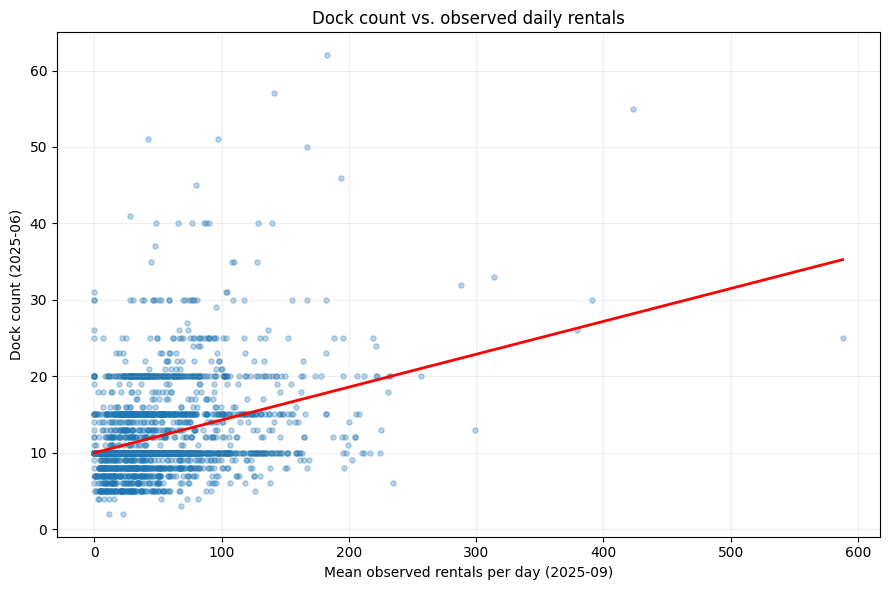


완료: /content/ttareungi_allocation_results
거치대 자료는 2025년 6월, 이용량은 2025년 9월 기준입니다.
아직 보정 수요 및 비례배치 검정은 수행하지 않았습니다.


In [ ]:
# ============================================================
# Group 19 — 거치대 연결 + 관측 수요 기준 배치 회귀
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

ROOT = Path("/content")
OUT = ROOT / "ttareungi_allocation_results"
OUT.mkdir(exist_ok=True)

MASTER = ROOT / "ttareungi_regression_master_202509.csv"
DOCKS = ROOT / "공공자전거 대여소 정보(25.6월 기준).xlsx"

# ------------------------------------------------------------
# 1. 대여소 번호 형식 통일
# ------------------------------------------------------------
def normalize_id(series):
    number = pd.to_numeric(series, errors="coerce")

    valid = (
        number.notna()
        & np.isfinite(number)
        & number.gt(0)
        & number.eq(number.round())
    )

    result = pd.Series(pd.NA, index=series.index, dtype="string")
    result.loc[valid] = (
        number.loc[valid].astype("int64").astype(str)
    )
    return result


# ------------------------------------------------------------
# 2. MASTER 검사
# ------------------------------------------------------------
df = pd.read_csv(
    MASTER, dtype={"station_id": str}, low_memory=False
)

required = [
    "station_id", "date", "daily_observed_rentals",
    "stockout_observations", "hours_observed"
]

missing = set(required) - set(df.columns)
if missing:
    raise ValueError(f"MASTER에 필요한 열이 없습니다: {missing}")

df["station_id"] = normalize_id(df["station_id"])
df["date"] = pd.to_datetime(df["date"], errors="raise").dt.normalize()

numeric_cols = [
    "daily_observed_rentals",
    "stockout_observations",
    "hours_observed"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="raise")

if df[required].isna().any().any():
    raise ValueError("MASTER 필수 변수에 결측 또는 잘못된 ID가 있습니다.")

if not np.isfinite(df[numeric_cols].to_numpy()).all():
    raise ValueError("MASTER에 무한대 값이 있습니다.")

if (df[numeric_cols] < 0).any().any():
    raise ValueError("MASTER에 음수가 있습니다.")

if (df["hours_observed"] <= 0).any():
    raise ValueError("관측 시간이 0 이하인 행이 있습니다.")

if (df["stockout_observations"] > df["hours_observed"]).any():
    raise ValueError("stockout 관측 횟수가 총 관측 시간을 초과합니다.")

if df.duplicated(["station_id", "date"]).any():
    raise ValueError("대여소·날짜 중복이 있습니다.")

if not df["date"].dt.to_period("M").eq(pd.Period("2025-09")).all():
    raise ValueError("MASTER에 2025년 9월 이외의 날짜가 있습니다.")

df["no_stockout"] = df["stockout_observations"].eq(0)
df["stockout_day"] = ~df["no_stockout"]

# ------------------------------------------------------------
# 3. 거치대 자료
# 확인한 엑셀 구조: 실제 데이터 6행부터
# A: ID, B: 이름, C: 자치구, H: LCD, I: QR
# ------------------------------------------------------------
raw = pd.read_excel(
    DOCKS,
    sheet_name="대여소현황",
    header=None,
    skiprows=5,
    usecols="A:C,H:I"
)

raw.columns = [
    "station_id", "station_name", "district",
    "lcd_docks", "qr_docks"
]

raw["station_id"] = normalize_id(raw["station_id"])

# 빈 행이나 ID가 없는 설명 행 제외
docks = raw[raw["station_id"].notna()].copy()

for col in ["lcd_docks", "qr_docks"]:
    docks[col] = pd.to_numeric(docks[col], errors="raise")

values = docks[["lcd_docks", "qr_docks"]]

if np.isinf(values.to_numpy(dtype=float)).any():
    raise ValueError("거치대 수에 무한대 값이 있습니다.")

if ((values < 0) | (values.notna() & values.ne(values.round()))).any().any():
    raise ValueError("거치대 수에 음수 또는 소수가 있습니다.")

# 한쪽만 기입되어 있으면 그 값 사용
# 양쪽 모두 결측이면 총 거치대 수도 결측 유지
docks["dock_count"] = values.sum(axis=1, min_count=1)
docks["dock_source_period"] = "2025-06"

if docks["station_id"].duplicated().any():
    duplicate = docks[
        docks["station_id"].duplicated(keep=False)
    ]
    duplicate.to_csv(
        OUT / "duplicate_dock_ids.csv",
        index=False, encoding="utf-8-sig"
    )
    raise ValueError("거치대 자료에 ID 중복이 있습니다. 중복 파일을 확인하세요.")

print("===== DOCK DATA CHECK =====")
print("대여소 수:", len(docks))
print("LCD·QR 모두 기입된 대여소:", int(values.notna().all(axis=1).sum()))
print("거치대 수 결측:", int(docks["dock_count"].isna().sum()))
print("거치대 수 0:", int(docks["dock_count"].eq(0).sum()))

# ------------------------------------------------------------
# 4. 대여소별 집계
# ------------------------------------------------------------
station = df.groupby("station_id").agg(
    observed_days=("date", "nunique"),
    observed_daily_mean=("daily_observed_rentals", "mean"),
    observed_daily_std=("daily_observed_rentals", "std"),
    no_stockout_days=("no_stockout", "sum"),
    stockout_days=("stockout_day", "sum"),
    stockout_observations=("stockout_observations", "sum"),
    hours_observed=("hours_observed", "sum")
).reset_index()

station["stockout_day_share"] = (
    station["stockout_days"] / station["observed_days"]
)

# 観測時間数の差を考慮した stockout 観測比率
station["stockout_observation_rate"] = (
    station["stockout_observations"] / station["hours_observed"]
)

normal_mean = (
    df[df["no_stockout"]]
    .groupby("station_id")["daily_observed_rentals"].mean()
)

station["station_baseline_demand"] = (
    station["station_id"].map(normal_mean)
)

station = station.merge(
    docks,
    on="station_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\n===== MATCHING CHECK =====")
print("MASTER 대여소:", len(station))
print("거치대 자료 연결 성공:", int(station["_merge"].eq("both").sum()))
print("거치대 자료 연결 실패:", int(station["_merge"].eq("left_only").sum()))

unmatched = station[station["_merge"].eq("left_only")].copy()

# ------------------------------------------------------------
# 5. 기본 배치 회귀
# 양수 거치대 수가 확인된 대여소 사용
# ------------------------------------------------------------
analysis = station[
    station["dock_count"].notna()
    & station["dock_count"].gt(0)
].copy()

if len(analysis) < 30:
    raise ValueError("회귀에 사용할 대여소가 30개 미만입니다.")

if analysis["observed_daily_mean"].nunique() < 2:
    raise ValueError("수요 값에 변동이 없어 회귀할 수 없습니다.")

def fit_allocation(frame):
    X = sm.add_constant(
        frame[["observed_daily_mean"]],
        has_constant="add"
    )
    # 대여소별 한 행. 이분산에 대비한 HC3 표준오차
    model = sm.OLS(frame["dock_count"], X).fit(cov_type="HC3")
    return model, X

model, X = fit_allocation(analysis)

conf = model.conf_int()
coef = pd.DataFrame({
    "Variable": model.params.index,
    "Beta": model.params.values,
    "Std_Error_HC3": model.bse.values,
    "p_value": model.pvalues.values,
    "CI_low": conf[0].values,
    "CI_high": conf[1].values
})

print("\n===== ALLOCATION REGRESSION =====")
print("분석 대여소:", len(analysis))
print("R²:", round(model.rsquared, 4))
print("Adjusted R²:", round(model.rsquared_adj, 4))
print(coef.round(6).to_string(index=False))

# ------------------------------------------------------------
# 6. 관측일 수가 적은 대여소의 영향 확인
# 25일은 민감도 점검 기준이며 검증된 품질 기준은 아님
# ------------------------------------------------------------
sensitivity = analysis[analysis["observed_days"] >= 25]

if (
    len(sensitivity) >= 30
    and sensitivity["observed_daily_mean"].nunique() >= 2
):
    model_25, _ = fit_allocation(sensitivity)

    print("\n===== AT LEAST 25 OBSERVED DAYS =====")
    print("대여소:", len(sensitivity))
    print("R²:", round(model_25.rsquared, 4))
    print(
        "수요 계수:",
        round(model_25.params["observed_daily_mean"], 6)
    )
    print(
        "수요 계수 p-value:",
        model_25.pvalues["observed_daily_mean"]
    )

# ------------------------------------------------------------
# 7. 상대적 배치 차이
# fitted 값은 회귀선상의 값이며 권장 거치대 수가 아님
# ------------------------------------------------------------
analysis["fitted_dock_count"] = model.predict(X)
analysis["allocation_residual"] = (
    analysis["dock_count"] - analysis["fitted_dock_count"]
)

show_cols = [
    "station_id", "station_name",
    "observed_daily_mean", "dock_count",
    "allocation_residual", "stockout_observation_rate",
    "observed_days"
]

print("\n===== MOST NEGATIVE RESIDUALS =====")
print(
    analysis.sort_values("allocation_residual")
    [show_cols].head(10).round(3).to_string(index=False)
)

# ------------------------------------------------------------
# 8. 산점도
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    analysis["observed_daily_mean"],
    analysis["dock_count"],
    alpha=0.3, s=14
)

grid = np.linspace(
    analysis["observed_daily_mean"].min(),
    analysis["observed_daily_mean"].max(),
    200
)

line = (
    model.params["const"]
    + model.params["observed_daily_mean"] * grid
)

ax.plot(grid, line, color="red", linewidth=2)
ax.set_xlabel("Mean observed rentals per day (2025-09)")
ax.set_ylabel("Dock count (2025-06)")
ax.set_title("Dock count vs. observed daily rentals")
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(OUT / "allocation_scatter.png", dpi=180)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. 저장
# ------------------------------------------------------------
outputs = {
    "station_allocation_master.csv": station,
    "unmatched_stations.csv": unmatched,
    "observed_allocation_regression_data.csv": analysis,
    "observed_allocation_coefficients.csv": coef
}

for filename, table in outputs.items():
    table.to_csv(
        OUT / filename,
        index=False, encoding="utf-8-sig"
    )

print("\n완료:", OUT)
print("거치대 자료는 2025년 6월, 이용량은 2025년 9월 기준입니다.")
print("아직 보정 수요 및 비례배치 검정은 수행하지 않았습니다.")

In [ ]:
# ============================================================
# Group 19 — 수요 보정 전후 거치대 회귀 비교
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm

ROOT = Path("/content")
OUT = ROOT / "ttareungi_correction_results"
OUT.mkdir(exist_ok=True)

MASTER = ROOT / "ttareungi_regression_master_202509.csv"

station_paths = [
    ROOT / "ttareungi_allocation_results/station_allocation_master.csv",
    ROOT / "station_allocation_master.csv"
]
STATION = next((p for p in station_paths if p.exists()), None)

if STATION is None:
    raise FileNotFoundError("station_allocation_master.csv를 올려주세요.")

Y = "daily_observed_rentals"

def normalize_id(series):
    n = pd.to_numeric(series, errors="raise")
    if (
        n.isna().any()
        or not np.isfinite(n.to_numpy(dtype=float)).all()
        or (n <= 0).any()
        or n.ne(n.round()).any()
    ):
        raise ValueError("잘못된 대여소 ID가 있습니다.")
    return n.astype("int64").astype(str)

df = pd.read_csv(MASTER, dtype={"station_id": str})
station = pd.read_csv(STATION, dtype={"station_id": str})

for frame in [df, station]:
    frame["station_id"] = normalize_id(frame["station_id"])

df["date"] = pd.to_datetime(df["date"], errors="raise").dt.normalize()

required = ["station_id", "date", Y, "stockout_observations"]
if not set(required).issubset(df.columns):
    raise ValueError("MASTER 필수 열이 없습니다.")

for col in [Y, "stockout_observations"]:
    df[col] = pd.to_numeric(df[col], errors="raise")

if df[required].isna().any().any():
    raise ValueError("MASTER 필수 값에 결측이 있습니다.")

if not np.isfinite(df[[Y, "stockout_observations"]].to_numpy()).all():
    raise ValueError("무한대 값이 있습니다.")

if (df[[Y, "stockout_observations"]] < 0).any().any():
    raise ValueError("음수가 있습니다.")

if df.duplicated(["station_id", "date"]).any():
    raise ValueError("대여소·날짜 중복이 있습니다.")

if not df["date"].dt.to_period("M").eq(pd.Period("2025-09")).all():
    raise ValueError("2025년 9월 이외의 날짜가 있습니다.")

if station["station_id"].duplicated().any():
    raise ValueError("대여소 집계 파일에 ID 중복이 있습니다.")

station["dock_count"] = pd.to_numeric(
    station["dock_count"], errors="raise"
)

# ------------------------------------------------------------
# 1. MASTER에서 평균과 참고일 수를 다시 계산
# 9월 전체를 사용하는 사후 보정 시나리오
# ------------------------------------------------------------
df["stockout_day"] = df["stockout_observations"].gt(0)

reference = (
    df[~df["stockout_day"]]
    .groupby("station_id")[Y]
    .agg(
        station_baseline_demand="mean",
        reference_days="count"
    )
    .reset_index()
)

dock_cols = ["station_id", "dock_count"]
for col in ["station_name", "district", "dock_source_period"]:
    if col in station.columns:
        dock_cols.append(col)

daily = df.merge(
    reference,
    on="station_id",
    how="left",
    validate="many_to_one"
).merge(
    station[dock_cols],
    on="station_id",
    how="left",
    validate="many_to_one"
)

daily["reference_days"] = (
    daily["reference_days"].fillna(0).astype(int)
)

# ------------------------------------------------------------
# 2. 참고일 5일 / 10일 이상 시나리오
# 대상 밖은 NaN. 손실 수요를 0으로 채우지 않음.
# ------------------------------------------------------------
for threshold in [5, 10]:
    eligible = daily["reference_days"].ge(threshold)

    lost_col = f"scenario_lost_demand_min{threshold}"
    demand_col = f"scenario_demand_min{threshold}"

    daily[lost_col] = np.nan

    # 대상 대여소의 stockout 미관측일:
    # 이 시나리오에서는 보정하지 않음
    daily.loc[eligible & ~daily["stockout_day"], lost_col] = 0.0

    # 대상 대여소의 stockout 관측일
    mask = eligible & daily["stockout_day"]
    daily.loc[mask, lost_col] = (
        daily.loc[mask, "station_baseline_demand"]
        - daily.loc[mask, Y]
    ).clip(lower=0)

    daily[demand_col] = daily[Y] + daily[lost_col]
    daily[f"scenario_eligible_min{threshold}"] = eligible

# ------------------------------------------------------------
# 3. 대여소별 일평균 수요 집계
# ------------------------------------------------------------
allocation = daily.groupby("station_id").agg(
    observed_days=("date", "nunique"),
    observed_daily_mean=(Y, "mean"),
    reference_days=("reference_days", "first"),
    station_baseline_demand=("station_baseline_demand", "first"),
    corrected_daily_mean_min5=("scenario_demand_min5", "mean"),
    corrected_daily_mean_min10=("scenario_demand_min10", "mean"),
    avg_scenario_lost_min5=("scenario_lost_demand_min5", "mean"),
    avg_scenario_lost_min10=("scenario_lost_demand_min10", "mean")
).reset_index()

allocation = allocation.merge(
    station[dock_cols],
    on="station_id",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 4. 同一 대여소 집합으로 보정 전후 비교
# HC3는 보정 수요 추정의 불확실성까지 반영하지 않음.
# ------------------------------------------------------------
results = []
coefficient_tables = []

def fit_model(frame, x_col, label, threshold):
    X = sm.add_constant(frame[[x_col]], has_constant="add")
    model = sm.OLS(
        frame["dock_count"], X
    ).fit(cov_type="HC3")

    ci = model.conf_int()

    results.append({
        "Reference_threshold": threshold,
        "Demand": label,
        "Stations": len(frame),
        "R2": model.rsquared,
        "Intercept": model.params["const"],
        "Slope": model.params[x_col],
        "Slope_p": model.pvalues[x_col],
        "Slope_CI_low": ci.loc[x_col, 0],
        "Slope_CI_high": ci.loc[x_col, 1],
        "Mean_daily_demand": frame[x_col].mean()
    })

    coef = pd.DataFrame({
        "Variable": model.params.index,
        "Beta": model.params.values,
        "Std_Error_HC3": model.bse.values,
        "p_value": model.pvalues.values,
        "CI_low": ci[0].values,
        "CI_high": ci[1].values
    })
    coef["Reference_threshold"] = threshold
    coef["Demand"] = label
    coefficient_tables.append(coef)

    return model

for threshold in [5, 10]:
    corrected = f"corrected_daily_mean_min{threshold}"

    sample = allocation[
        allocation["reference_days"].ge(threshold)
        & allocation["dock_count"].notna()
        & np.isfinite(allocation["dock_count"])
        & allocation["dock_count"].gt(0)
    ].copy()

    if len(sample) < 30:
        raise ValueError(f"{threshold}일 시나리오의 대여소가 부족합니다.")

    if sample[["observed_daily_mean", corrected]].isna().any().any():
        raise ValueError("시나리오 수요에 예상하지 못한 결측이 있습니다.")

    if (
        sample["observed_daily_mean"].nunique() < 2
        or sample[corrected].nunique() < 2
    ):
        raise ValueError("수요의 변동이 부족합니다.")

    fit_model(sample, "observed_daily_mean", "Observed", threshold)
    corrected_model = fit_model(
        sample, corrected, "Corrected_scenario", threshold
    )

    sample["fitted_docks_corrected"] = corrected_model.predict(
        sm.add_constant(sample[[corrected]], has_constant="add")
    )
    sample["residual_corrected"] = (
        sample["dock_count"] - sample["fitted_docks_corrected"]
    )

    sample.to_csv(
        OUT / f"allocation_comparison_min{threshold}.csv",
        index=False, encoding="utf-8-sig"
    )

# ------------------------------------------------------------
# 5. 출력 및 저장
# ------------------------------------------------------------
comparison = pd.DataFrame(results)

print("===== SAME-STATION REGRESSION COMPARISON =====")
print(comparison.to_string(index=False, float_format=lambda x: f"{x:.6g}"))

print("\n===== CORRECTION SIZE =====")
for threshold in [5, 10]:
    eligible = daily[f"scenario_eligible_min{threshold}"]
    target = eligible & daily["stockout_day"]
    lost_col = f"scenario_lost_demand_min{threshold}"

    print(f"\n참고일 {threshold}일 이상")
    print("대상 대여소:", daily.loc[eligible, "station_id"].nunique())
    print("대상 stockout 행:", int(target.sum()))
    print("양의 보정이 발생한 행:", int((daily.loc[target, lost_col] > 0).sum()))
    print(
        "대상 stockout 행의 평균 추가량:",
        round(daily.loc[target, lost_col].mean(), 3)
    )
    print(
        "시나리오 추가량 합계:",
        round(daily.loc[target, lost_col].sum(min_count=1), 3)
    )

daily.to_csv(
    OUT / "daily_master_with_docks_and_scenarios.csv",
    index=False, encoding="utf-8-sig"
)

allocation.to_csv(
    OUT / "station_allocation_with_scenarios.csv",
    index=False, encoding="utf-8-sig"
)

comparison.to_csv(
    OUT / "same_station_regression_comparison.csv",
    index=False, encoding="utf-8-sig"
)

pd.concat(coefficient_tables, ignore_index=True).to_csv(
    OUT / "scenario_regression_coefficients.csv",
    index=False, encoding="utf-8-sig"
)

print("\n완료:", OUT)

===== SAME-STATION REGRESSION COMPARISON =====
 Reference_threshold             Demand  Stations       R2  Intercept     Slope     Slope_p  Slope_CI_low  Slope_CI_high  Mean_daily_demand
                   5           Observed      2302 0.119138    9.95463 0.0450409 3.22059e-25     0.0365322      0.0535497            50.8509
                   5 Corrected_scenario      2302 0.118115    9.98823 0.0420365 4.09036e-24     0.0339028      0.0501702            53.6861
                  10           Observed      1889 0.129969    9.84807  0.049783 6.24644e-24     0.0401107      0.0594552            51.3611
                  10 Corrected_scenario      1889 0.133579    9.83804 0.0480263 2.38925e-24     0.0387815      0.0572712            53.4486

===== CORRECTION SIZE =====

참고일 5일 이상
대상 대여소: 2302
대상 stockout 행: 24669
양의 보정이 발생한 행: 12074
대상 stockout 행의 평균 추가량: 7.892
시나리오 추가량 합계: 194694.059

참고일 10일 이상
대상 대여소: 1889
대상 stockout 행: 15183
양의 보정이 발생한 행: 7294
대상 stockout 행의 평균 추가량: 7.75
시나리오 추가량 합계: 

In [ ]:
# ============================================================
# Group 19 — 수요에 따른 비례배치 평가
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm

ROOT = Path("/content")
OUT = ROOT / "ttareungi_proportionality_results"
OUT.mkdir(exist_ok=True)

paths = [
    ROOT / "ttareungi_correction_results/station_allocation_with_scenarios.csv",
    ROOT / "station_allocation_with_scenarios.csv"
]

FILE = next((p for p in paths if p.exists()), None)

if FILE is None:
    raise FileNotFoundError(
        "station_allocation_with_scenarios.csv를 올려주세요."
    )

df = pd.read_csv(FILE, dtype={"station_id": str})

required = [
    "station_id", "dock_count", "reference_days",
    "observed_daily_mean",
    "corrected_daily_mean_min5",
    "corrected_daily_mean_min10"
]

missing = set(required) - set(df.columns)
if missing:
    raise ValueError(f"필요한 열이 없습니다: {missing}")

if df["station_id"].isna().any() or df["station_id"].duplicated().any():
    raise ValueError("대여소 ID에 결측 또는 중복이 있습니다.")

for col in required[1:]:
    df[col] = pd.to_numeric(df[col], errors="raise")

if df["reference_days"].isna().any():
    raise ValueError("참고일 수에 결측이 있습니다.")

# ------------------------------------------------------------
# 동일 표본에서 관측 / 보정 수요 비교
# ------------------------------------------------------------
cases = [
    (5, "Observed", "observed_daily_mean"),
    (5, "Corrected", "corrected_daily_mean_min5"),
    (10, "Observed", "observed_daily_mean"),
    (10, "Corrected", "corrected_daily_mean_min10")
]

results = []
ratio_results = []

for threshold, label, demand_col in cases:
    corrected_col = f"corrected_daily_mean_min{threshold}"

    sample = df[
        df["reference_days"].ge(threshold)
        & df["dock_count"].notna()
        & np.isfinite(df["dock_count"])
        & df["dock_count"].gt(0)
    ].copy()

    # 観測・補正の両方が同じ標本で利用可能か確認
    demand_values = sample[
        ["observed_daily_mean", corrected_col]
    ]

    if (
        demand_values.isna().any().any()
        or not np.isfinite(demand_values.to_numpy()).all()
        or (demand_values < 0).any().any()
    ):
        raise ValueError(f"{threshold}日条件の需要値を確認してください。")

    if len(sample) < 30 or sample[demand_col].nunique() < 2:
        raise ValueError("回帰に必要な標本数または変動が不足しています。")

    q = sample[demand_col]
    d = sample["dock_count"]

    # 一般線形モデル
    X_linear = sm.add_constant(
        sample[[demand_col]], has_constant="add"
    )
    linear = sm.OLS(d, X_linear).fit(cov_type="HC3")

    # 比例モデル: 切片なし
    X_prop = sample[[demand_col]]
    proportional = sm.OLS(d, X_prop).fit(cov_type="HC3")

    pred_linear = linear.predict(X_linear)
    pred_prop = proportional.predict(X_prop)

    rmse_linear = np.sqrt(np.mean((d - pred_linear) ** 2))
    rmse_prop = np.sqrt(np.mean((d - pred_prop) ** 2))

    # 切片なしモデルの既定R²は比較に使わず、
    # 両方とも平均からの変動を分母にしたR²を計算
    tss = np.sum((d - d.mean()) ** 2)

    if tss <= 0:
        raise ValueError("거치대 수에 변동이 없습니다.")

    r2_linear = 1 - np.sum((d - pred_linear) ** 2) / tss
    r2_prop = 1 - np.sum((d - pred_prop) ** 2) / tss

    ci = linear.conf_int()
    k_ci = proportional.conf_int().loc[demand_col]

    results.append({
        "Threshold": threshold,
        "Demand": label,
        "Stations": len(sample),
        "Intercept": linear.params["const"],
        "Intercept_CI_low": ci.loc["const", 0],
        "Intercept_CI_high": ci.loc["const", 1],
        "Intercept_p": linear.pvalues["const"],
        "Slope_linear": linear.params[demand_col],
        "k_proportional": proportional.params[demand_col],
        "k_CI_low": k_ci.iloc[0],
        "k_CI_high": k_ci.iloc[1],
        "Centered_R2_linear": r2_linear,
        "Centered_R2_proportional": r2_prop,
        "RMSE_linear": rmse_linear,
        "RMSE_proportional": rmse_prop
    })

    # 수요가 0인 대여소는 비율 계산에서 제외
    positive = q.gt(0)
    ratios = d.loc[positive] / q.loc[positive]

    ratio_results.append({
        "Threshold": threshold,
        "Demand": label,
        "Positive_demand_stations": int(positive.sum()),
        "Zero_demand_stations": int((~positive).sum()),
        "Ratio_P10": ratios.quantile(0.10),
        "Ratio_P25": ratios.quantile(0.25),
        "Ratio_median": ratios.median(),
        "Ratio_P75": ratios.quantile(0.75),
        "Ratio_P90": ratios.quantile(0.90)
    })

    # 두 모형의 적합값과 잔차 저장
    sample["demand_used"] = q
    sample["fitted_linear"] = pred_linear
    sample["fitted_proportional"] = pred_prop
    sample["residual_linear"] = d - pred_linear
    sample["residual_proportional"] = d - pred_prop
    sample["docks_per_daily_rental"] = (
        d / q.replace(0, np.nan)
    )

    sample.to_csv(
        OUT / f"station_results_min{threshold}_{label.lower()}.csv",
        index=False, encoding="utf-8-sig"
    )

comparison = pd.DataFrame(results)
ratio_summary = pd.DataFrame(ratio_results)

print("===== PROPORTIONALITY COMPARISON =====")
print(
    comparison.to_string(
        index=False, float_format=lambda x: f"{x:.6g}"
    )
)

print("\n===== DOCKS / DAILY DEMAND RATIOS =====")
print(ratio_summary.round(4).to_string(index=False))

comparison.to_csv(
    OUT / "proportionality_comparison.csv",
    index=False, encoding="utf-8-sig"
)

ratio_summary.to_csv(
    OUT / "dock_demand_ratio_summary.csv",
    index=False, encoding="utf-8-sig"
)

print("\n완료:", OUT)
print("RMSE는 표본 내 적합 오차이며 독립 테스트 예측 성능이 아닙니다.")
print("보정 시나리오 수요의 추정 불확실성은 표준오차에 반영되지 않았습니다.")

===== PROPORTIONALITY COMPARISON =====
 Threshold    Demand  Stations  Intercept  Intercept_CI_low  Intercept_CI_high  Intercept_p  Slope_linear  k_proportional  k_CI_low  k_CI_high  Centered_R2_linear  Centered_R2_proportional  RMSE_linear  RMSE_proportional
         5  Observed      2302    9.95463           9.56071            10.3486            0     0.0450409        0.157947  0.147291   0.168603            0.119138                  -1.17888        5.335            8.39068
         5 Corrected      2302    9.98823           9.58938            10.3871            0     0.0420365        0.148389  0.137454   0.159324            0.118115                  -1.20448       5.3381            8.43983
        10  Observed      1889    9.84807           9.39838            10.2978            0      0.049783        0.164756  0.156415   0.173096            0.129969                  -1.02612      5.40577            8.24941
        10 Corrected      1889    9.83804           9.39023            10.285

In [ ]:
# ============================================================
# Group 19 — 시간별 자료 복원 및 예측수요 생성
#
# 1. 일일 실제 대여량 수정
# 2. 대여 0건 시간을 포함한 24시간 자료 구성
# 3. 시간 순서 검증
# 4. 시간별·일별 예상 수요 생성
# 5. 품절 지속시간 가정별 보정 시나리오
# ============================================================

from pathlib import Path
import json
import shutil

import numpy as np
import pandas as pd

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

ROOT = Path("/content")
OUT = ROOT / "ttareungi_demand_rebuilt_202509"
OUT.mkdir(exist_ok=True)

MASTER_FILE = ROOT / "ttareungi_regression_master_202509.csv"
INVENTORY_FILE = ROOT / "data_2509.csv"
RENTAL_FILE = (
    ROOT / "서울특별시 공공자전거 이용정보(시간대별)_202509.csv"
)

for path in [MASTER_FILE, INVENTORY_FILE, RENTAL_FILE]:
    if not path.exists():
        raise FileNotFoundError(f"파일을 올려주세요: {path.name}")


# ------------------------------------------------------------
# 1. 공통 함수
# ------------------------------------------------------------
def read_korean_csv(path, **kwargs):
    for encoding in ["utf-8-sig", "cp949"]:
        try:
            return pd.read_csv(path, encoding=encoding, **kwargs)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"인코딩을 확인하세요: {path.name}")


def clean_keys(frame, hourly=False):
    frame = frame.copy()

    station_number = pd.to_numeric(
        frame["station_id"], errors="raise"
    )

    if (
        station_number.isna().any()
        or not np.isfinite(station_number).all()
        or station_number.le(0).any()
        or station_number.ne(station_number.round()).any()
    ):
        raise ValueError("잘못된 대여소 ID가 있습니다.")

    frame["station_id"] = station_number.astype("int64")

    frame["date"] = pd.to_datetime(
        frame["date"], errors="raise"
    ).dt.normalize()

    if frame["date"].isna().any():
        raise ValueError("날짜 결측이 있습니다.")

    if not frame["date"].dt.to_period("M").eq(
        pd.Period("2025-09")
    ).all():
        raise ValueError("2025년 9월 이외의 날짜가 있습니다.")

    if hourly:
        hour = pd.to_numeric(frame["hour"], errors="raise")
        if (
            hour.isna().any()
            or not hour.between(0, 23).all()
            or hour.ne(hour.round()).any()
        ):
            raise ValueError("시간은 0~23의 정수여야 합니다.")
        frame["hour"] = hour.astype("int8")

    return frame


def check_nonnegative(frame, column):
    frame[column] = pd.to_numeric(frame[column], errors="raise")
    if (
        frame[column].isna().any()
        or not np.isfinite(frame[column]).all()
        or frame[column].lt(0).any()
    ):
        raise ValueError(f"{column}에 잘못된 값이 있습니다.")


DAY_KEYS = ["station_id", "date"]
HOUR_KEYS = ["station_id", "date", "hour"]


# ------------------------------------------------------------
# 2. 원자료 불러오기
# ------------------------------------------------------------
master = clean_keys(read_korean_csv(MASTER_FILE))

if master.duplicated(DAY_KEYS).any():
    raise ValueError("MASTER의 대여소·날짜가 중복됩니다.")

inventory = read_korean_csv(INVENTORY_FILE).rename(
    columns={
        "일시": "date",
        "대여소번호": "station_id",
        "시간대": "hour",
        "거치대수량": "inventory_snapshot"
    }
)

inventory = clean_keys(inventory, hourly=True)
check_nonnegative(inventory, "inventory_snapshot")

if inventory.duplicated(HOUR_KEYS).any():
    raise ValueError("재고 자료의 대여소·날짜·시간이 중복됩니다.")

rentals = read_korean_csv(
    RENTAL_FILE,
    usecols=["대여일자", "대여시간", "대여소번호", "이용건수"]
).rename(
    columns={
        "대여일자": "date",
        "대여시간": "hour",
        "대여소번호": "station_id",
        "이용건수": "observed_rentals"
    }
)

rentals = clean_keys(rentals, hourly=True)
check_nonnegative(rentals, "observed_rentals")

# 성별·연령·이용권 등으로 나뉜 행을 합산
rentals = (
    rentals.groupby(HOUR_KEYS, as_index=False)["observed_rentals"]
    .sum()
)

print("원자료 불러오기 완료")


# ------------------------------------------------------------
# 3. MASTER의 모든 대여소·날짜에 24시간 구성
#
# 대여 원자료가 완전하다는 가정 아래:
# 대여 기록이 없는 시간 = 대여 0건
# 재고 기록이 없는 시간 = 재고 결측
# ------------------------------------------------------------
hourly = master[DAY_KEYS].merge(
    pd.DataFrame({"hour": range(24)}),
    how="cross"
)

hourly = hourly.merge(
    rentals,
    on=HOUR_KEYS,
    how="left",
    validate="one_to_one"
).merge(
    inventory[HOUR_KEYS + ["inventory_snapshot"]],
    on=HOUR_KEYS,
    how="left",
    validate="one_to_one"
)

hourly["observed_rentals"] = (
    hourly["observed_rentals"].fillna(0)
)

hourly["snapshot_missing"] = (
    hourly["inventory_snapshot"].isna()
)
hourly["stockout_snapshot"] = (
    hourly["inventory_snapshot"].eq(0)
)
hourly["weekend"] = (
    hourly["date"].dt.dayofweek >= 5
).astype(int)


# ------------------------------------------------------------
# 4. 일일 대여량 수정 및 기존 stockout 집계 확인
# ------------------------------------------------------------
daily_check = hourly.groupby(DAY_KEYS).agg(
    corrected_rentals=("observed_rentals", "sum"),
    snapshots=("inventory_snapshot", "count"),
    zeros=("stockout_snapshot", "sum")
).reset_index()

master = master.merge(
    daily_check,
    on=DAY_KEYS,
    how="left",
    validate="one_to_one"
)

if not master["snapshots"].eq(master["hours_observed"]).all():
    raise ValueError("기존 MASTER의 재고 관측 횟수와 다릅니다.")

if not master["zeros"].eq(master["stockout_observations"]).all():
    raise ValueError("기존 MASTER의 stockout 횟수와 다릅니다.")

master["old_daily_observed_rentals"] = (
    master["daily_observed_rentals"]
)
master["daily_observed_rentals"] = master["corrected_rentals"]

# MASTER는 기존 품질조건을 통과한 자료
# stockout 미관측일만 수요모델 학습에 사용
master["train_for_demand_model"] = (
    master["stockout_observations"].eq(0)
)

hourly = hourly.merge(
    master[DAY_KEYS + ["train_for_demand_model"]],
    on=DAY_KEYS,
    how="left",
    validate="many_to_one"
)

changed = master["daily_observed_rentals"].ne(
    master["old_daily_observed_rentals"]
)

print("\n===== DATA REPAIR =====")
print("MASTER 행:", len(master))
print("대여소:", master["station_id"].nunique())
print("수정된 일일 대여량 행:", int(changed.sum()))
print(
    "복원된 실제 대여 건수:",
    int(
        (
            master["daily_observed_rentals"]
            - master["old_daily_observed_rentals"]
        ).sum()
    )
)
print("시간별 행:", len(hourly))
print("대여 0건 시간:", int(hourly["observed_rentals"].eq(0).sum()))
print("재고 미관측 시간:", int(hourly["snapshot_missing"].sum()))


# ------------------------------------------------------------
# 5. 시간별 예상 수요 λ
#
# 우선: 대여소 × 평일/주말 × 시간, 참고일 3일 이상
# 대안: 대여소 × 시간, 참고일 5일 이상
# 둘 다 부족: 결측
#
# 3일·5일은 운영 기준이며 최적 기준으로 검증된 값은 아님
# ------------------------------------------------------------
def predict_hourly(train, target):
    fine = (
        train.groupby(["station_id", "weekend", "hour"])
        ["observed_rentals"]
        .agg(["mean", "count"])
        .reset_index()
    )

    broad = (
        train.groupby(["station_id", "hour"])
        ["observed_rentals"]
        .agg(["mean", "count"])
        .reset_index()
    )

    a = target[["station_id", "weekend", "hour"]].merge(
        fine,
        on=["station_id", "weekend", "hour"],
        how="left",
        validate="many_to_one"
    )

    b = target[["station_id", "hour"]].merge(
        broad,
        on=["station_id", "hour"],
        how="left",
        validate="many_to_one"
    )

    use_fine = a["count"].ge(3)
    use_broad = (~use_fine) & b["count"].ge(5)

    predicted = a["mean"].where(
        use_fine,
        b["mean"].where(use_broad)
    )

    reference_days = a["count"].where(
        use_fine,
        b["count"].where(use_broad)
    )

    source = np.where(
        use_fine,
        "station_weekend_hour",
        np.where(use_broad, "station_hour", "unsupported")
    )

    return (
        predicted.to_numpy(),
        reference_days.to_numpy(),
        source
    )


# ------------------------------------------------------------
# 6. 시간 순서 검증
# 검증 날짜의 대여량은 평균 계산에 사용하지 않음
# stockout 미관측일에서만 평가
# ------------------------------------------------------------
windows = [
    ("2025-09-16", "2025-09-21"),
    ("2025-09-21", "2025-09-25"),
    ("2025-09-25", "2025-10-01")
]

validation_rows = []

for start, end in windows:
    start_date = pd.Timestamp(start)
    end_date = pd.Timestamp(end)

    train = hourly[
        (hourly["date"] < start_date)
        & hourly["train_for_demand_model"]
    ]

    test = hourly[
        (hourly["date"] >= start_date)
        & (hourly["date"] < end_date)
        & hourly["train_for_demand_model"]
    ].copy()

    pred, _, _ = predict_hourly(train, test)
    test["prediction"] = pred

    available = np.isfinite(pred)

    if not available.any():
        raise ValueError(f"{start}: 예측 가능한 검증 자료가 없습니다.")

    # 하루 24시간 모두 예측된 날짜만 일일 성능 평가
    daily_test = test.groupby(DAY_KEYS).agg(
        actual=("observed_rentals", "sum"),
        predicted=("prediction", "sum"),
        predicted_hours=("prediction", "count")
    )

    complete = daily_test[
        daily_test["predicted_hours"].eq(24)
    ]

    if len(complete) < 2:
        raise ValueError(f"{start}: 일일 검증 자료가 부족합니다.")

    validation_rows.append({
        "Start": start,
        "End_exclusive": end,
        "Hourly_coverage": available.mean(),
        "Hourly_MAE": mean_absolute_error(
            test.loc[available, "observed_rentals"],
            pred[available]
        ),
        "Hourly_RMSE": np.sqrt(
            mean_squared_error(
                test.loc[available, "observed_rentals"],
                pred[available]
            )
        ),
        "Complete_days": len(complete),
        "Daily_coverage": len(complete) / len(daily_test),
        "Daily_R2": r2_score(
            complete["actual"], complete["predicted"]
        ),
        "Daily_MAE": mean_absolute_error(
            complete["actual"], complete["predicted"]
        ),
        "Daily_RMSE": np.sqrt(
            mean_squared_error(
                complete["actual"], complete["predicted"]
            )
        ),
        "Daily_bias_pred_minus_actual": (
            complete["predicted"] - complete["actual"]
        ).mean()
    })

validation = pd.DataFrame(validation_rows)

print("\n===== TEMPORAL VALIDATION =====")
print(validation.round(4).to_string(index=False))


# ------------------------------------------------------------
# 7. 9월 전체 자료로 사후 예측값 생성
#
# 아래 값은 월 전체 자료를 이용한 사후 추정.
# 이 값 자체를 학습일의 성능 평가에 사용하지 않음.
# ------------------------------------------------------------
train_all = hourly[hourly["train_for_demand_model"]]

pred, reference_days, source = predict_hourly(
    train_all, hourly
)

hourly["predicted_hourly_demand"] = pred
hourly["reference_days"] = reference_days
hourly["prediction_source"] = source

# 24시간 모두 예측 가능한 날만 일일 예측 생성
daily_pred = (
    hourly.groupby(DAY_KEYS)["predicted_hourly_demand"]
    .sum(min_count=24)
    .rename("predicted_daily_demand")
    .reset_index()
)

master = master.merge(
    daily_pred,
    on=DAY_KEYS,
    how="left",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 8. 품절 지속시간 가정별 시나리오
#
# 재고 0 snapshot당 15 / 30 / 60분 품절 가정
# 추가량 = 시간당 예상 대여율 × 가정 품절시간
#
# 실제 지속시간을 추정한 값이 아님.
# λ가 가정 품절구간에도 적용된다는 추가 가정이 필요.
# 재고 미관측 또는 품절구간 λ 부족이면 일일 값은 결측.
# ------------------------------------------------------------
for minutes in [15, 30, 60]:
    fraction = minutes / 60

    loss_col = f"additional_demand_scenario_{minutes}min"
    demand_col = f"effective_demand_scenario_{minutes}min"

    hourly[loss_col] = np.where(
        hourly["stockout_snapshot"],
        hourly["predicted_hourly_demand"] * fraction,
        0.0
    )

    # 재고를 관측하지 못한 시간의 손실을 0으로 간주하지 않음
    hourly.loc[hourly["snapshot_missing"], loss_col] = np.nan

    daily_loss = (
        hourly.groupby(DAY_KEYS)[loss_col]
        .sum(min_count=24)
        .reset_index()
    )

    master = master.merge(
        daily_loss,
        on=DAY_KEYS,
        how="left",
        validate="one_to_one"
    )

    master[demand_col] = (
        master["daily_observed_rentals"] + master[loss_col]
    )

    # 보정값은 유효한 행에서 실제 대여량 이상이어야 함
    valid = master[demand_col].notna()
    assert (
        master.loc[valid, demand_col]
        >= master.loc[valid, "daily_observed_rentals"]
    ).all()


# ------------------------------------------------------------
# 9. 결과 요약
# ------------------------------------------------------------
summary = {
    "master_rows": len(master),
    "stations": int(master["station_id"].nunique()),
    "corrected_daily_rows": int(changed.sum()),
    "rentals_restored": float(
        (
            master["daily_observed_rentals"]
            - master["old_daily_observed_rentals"]
        ).sum()
    ),
    "hourly_rows": len(hourly),
    "zero_rental_hours": int(
        hourly["observed_rentals"].eq(0).sum()
    ),
    "missing_inventory_hours": int(
        hourly["snapshot_missing"].sum()
    ),
    "daily_prediction_coverage": float(
        master["predicted_daily_demand"].notna().mean()
    ),
    "scenario_coverage": float(
        master["effective_demand_scenario_30min"].notna().mean()
    )
}

print("\n===== FINAL SUMMARY =====")
for key, value in summary.items():
    print(f"{key}: {value}")

print("\n===== PREDICTION EXAMPLES =====")
print(
    master[
        [
            "station_id",
            "date",
            "daily_observed_rentals",
            "predicted_daily_demand",
            "effective_demand_scenario_15min",
            "effective_demand_scenario_30min",
            "effective_demand_scenario_60min"
        ]
    ].head(10).round(3).to_string(index=False)
)


# ------------------------------------------------------------
# 10. 저장
# ------------------------------------------------------------
master.to_csv(
    OUT / "ttareungi_master_corrected_with_predictions_202509.csv",
    index=False,
    encoding="utf-8-sig"
)

# 큰 시간별 파일은 압축 CSV로 저장
# pandas.read_csv로 압축 해제 없이 읽을 수 있음
hourly.to_csv(
    OUT / "ttareungi_hourly_rebuilt_202509.csv.gz",
    index=False,
    compression="gzip"
)

validation.to_csv(
    OUT / "temporal_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

(OUT / "audit_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

(OUT / "README.txt").write_text(
    "일일 대여량은 재고 관측 여부와 무관한 원자료 전체 합계입니다.\n"
    "대여 원자료가 완전하다는 가정 아래 기록 없는 시간은 대여 0건입니다.\n"
    "재고 미관측은 결측으로 유지했습니다.\n"
    "예측은 stockout 미관측일의 시간별 평균에 기반합니다.\n"
    "검증은 시간 순서로 분리한 stockout 미관측일에서 수행했습니다.\n"
    "실제 품절일의 숨은 수요 정확도는 검증되지 않았습니다.\n"
    "15/30/60분 보정은 snapshot당 품절시간 가정에 따른 시나리오입니다.\n"
    "지속시간을 자료에서 추정한 값이나 확정 손실수요가 아닙니다.\n"
    "재고 원본의 거치대수량 항목 정의와 관측시각 확인이 필요합니다.\n",
    encoding="utf-8"
)

zip_path = shutil.make_archive(
    str(ROOT / "ttareungi_demand_rebuilt_202509"),
    "zip",
    root_dir=OUT
)

print("\n완료. 결과 폴더:", OUT)
print("압축파일:", zip_path)

# 결과를 컴퓨터에 다운로드
from google.colab import files
files.download(zip_path)

원자료 불러오기 완료

===== DATA REPAIR =====
MASTER 행: 80601
대여소: 2695
수정된 일일 대여량 행: 1987
복원된 실제 대여 건수: 6491
시간별 행: 1934424
대여 0건 시간: 841101
재고 미관측 시간: 2696

===== TEMPORAL VALIDATION =====
     Start End_exclusive  Hourly_coverage  Hourly_MAE  Hourly_RMSE  Complete_days  Daily_coverage  Daily_R2  Daily_MAE  Daily_RMSE  Daily_bias_pred_minus_actual
2025-09-16    2025-09-21           0.8919      1.4208       2.4084           7059          0.8919    0.5130    17.5772     25.9852                       11.5268
2025-09-21    2025-09-25           0.9495      1.4213       2.4729           5698          0.9495    0.7173    18.2007     26.5476                       -5.8639
2025-09-25    2025-10-01           0.9702      1.3584       2.3396           8238          0.9702    0.7985    16.3127     24.1569                      -10.3688

===== FINAL SUMMARY =====
master_rows: 80601
stations: 2695
corrected_daily_rows: 1987
rentals_restored: 6491.0
hourly_rows: 1934424
zero_rental_hours: 841101
missing_invent

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Training rows: 45049
Stations: 2617

FINAL OLS
                            OLS Regression Results                            
Dep. Variable:      corrected_rentals   R-squared:                       0.065
Model:                            OLS   Adj. R-squared:                  0.065
Method:                 Least Squares   F-statistic:                     112.4
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           1.45e-88
Time:                        07:14:42   Log-Likelihood:            -2.3579e+05
No. Observations:               45049   AIC:                         4.716e+05
Df Residuals:                   45044   BIC:                         4.716e+05
Df Model:                           4                                         
Covariance Type:              cluster                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------

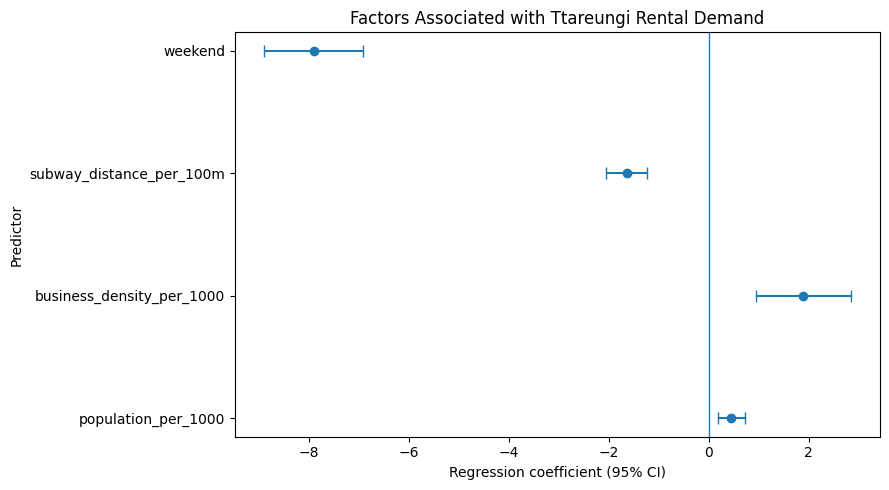


✅ FORMAL REGRESSION COMPLETE


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)


# ============================================================
# 1. LOAD MASTER
# ============================================================

FILE = (
    "/content/"
    "ttareungi_master_corrected_with_predictions_202509.csv"
)

df = pd.read_csv(
    FILE,
    dtype={"station_id": str},
    low_memory=False
)

df["date"] = pd.to_datetime(df["date"])


# ============================================================
# 2. TRAINING DATA
#
# 정상 공급일만 사용
# ============================================================

train = df[
    df["stockout_observations"] == 0
].copy()


print("Training rows:", len(train))
print(
    "Stations:",
    train["station_id"].nunique()
)


# ============================================================
# 3. RESCALE X FOR INTERPRETATION
# ============================================================

train["population_per_1000"] = (
    train["daily_avg_population_07_23"]
    / 1000
)

train["business_density_per_1000"] = (
    train["business_density_per_km2"]
    / 1000
)

train["subway_distance_per_100m"] = (
    train["subway_distance_m"]
    / 100
)


X_COLS = [
    "population_per_1000",
    "business_density_per_1000",
    "subway_distance_per_100m",
    "weekend"
]

Y_COL = "corrected_rentals"


# ============================================================
# 4. OLS + CLUSTER ROBUST SE
# ============================================================

X = sm.add_constant(
    train[X_COLS]
)

y = train[Y_COL]


model = sm.OLS(
    y,
    X
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups":
            train["station_id"]
    }
)


print("\n================================")
print("FINAL OLS")
print("================================")

print(model.summary())


# ============================================================
# 5. COEFFICIENT TABLE
# ============================================================

ci = model.conf_int()

coef = pd.DataFrame({
    "variable":
        model.params.index,

    "beta":
        model.params.values,

    "std_error":
        model.bse.values,

    "p_value":
        model.pvalues.values,

    "CI_95_low":
        ci[0].values,

    "CI_95_high":
        ci[1].values
})


print("\n================================")
print("COEFFICIENTS")
print("================================")

print(
    coef.to_string(
        index=False
    )
)


# ============================================================
# 6. VIF
# ============================================================

X_vif = train[X_COLS].copy()

X_vif = sm.add_constant(
    X_vif
)


vif = pd.DataFrame({
    "variable":
        X_vif.columns,

    "VIF": [
        variance_inflation_factor(
            X_vif.values,
            i
        )
        for i
        in range(
            X_vif.shape[1]
        )
    ]
})


print("\n================================")
print("VIF")
print("================================")

print(vif)


# ============================================================
# 7. HOLD-OUT PREDICTION
# ============================================================

X_ml = train[X_COLS]
y_ml = train[Y_COL]


X_train, X_test, y_train, y_test = (
    train_test_split(
        X_ml,
        y_ml,
        test_size=0.20,
        random_state=42
    )
)


prediction_model = LinearRegression()

prediction_model.fit(
    X_train,
    y_train
)


pred = prediction_model.predict(
    X_test
)

pred = np.clip(
    pred,
    0,
    None
)


R2 = r2_score(
    y_test,
    pred
)

MAE = mean_absolute_error(
    y_test,
    pred
)

RMSE = np.sqrt(
    mean_squared_error(
        y_test,
        pred
    )
)


print("\n================================")
print("PREDICTION PERFORMANCE")
print("================================")

print("R² =", round(R2, 4))
print("MAE =", round(MAE, 3))
print("RMSE =", round(RMSE, 3))


# ============================================================
# 8. SAVE METRICS
# ============================================================

metrics = pd.DataFrame({
    "metric": [
        "N",
        "R_squared",
        "Adjusted_R_squared",
        "Test_R_squared",
        "MAE",
        "RMSE"
    ],

    "value": [
        len(train),
        model.rsquared,
        model.rsquared_adj,
        R2,
        MAE,
        RMSE
    ]
})


coef.to_csv(
    "/content/"
    "FINAL_regression_coefficients.csv",
    index=False,
    encoding="utf-8-sig"
)


vif.to_csv(
    "/content/"
    "FINAL_regression_VIF.csv",
    index=False,
    encoding="utf-8-sig"
)


metrics.to_csv(
    "/content/"
    "FINAL_regression_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 9. COEFFICIENT PLOT
# ============================================================

plot_df = coef[
    coef["variable"] != "const"
].copy()


xerr = np.vstack([
    plot_df["beta"]
    -
    plot_df["CI_95_low"],

    plot_df["CI_95_high"]
    -
    plot_df["beta"]
])


plt.figure(
    figsize=(9, 5)
)

plt.errorbar(
    plot_df["beta"],
    plot_df["variable"],
    xerr=xerr,
    fmt="o",
    capsize=4
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel(
    "Regression coefficient (95% CI)"
)

plt.ylabel(
    "Predictor"
)

plt.title(
    "Factors Associated with Ttareungi Rental Demand"
)

plt.tight_layout()

plt.savefig(
    "/content/"
    "FINAL_regression_coefficient_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\n✅ FORMAL REGRESSION COMPLETE")

In [ ]:
# ============================================================
# TTAREUNGI FINAL SUPPLY & REDISTRIBUTION ANALYSIS
# 2025-09
#
# INPUT
# 1) ttareungi_FINAL_master_202509(1).csv
# 2) 공공자전거 대여소 정보(25.6월 기준)(2).xlsx
# 3) data_2509.csv
#
# OUTPUT
# 1) ttareungi_FINAL_master_with_supply_202509.csv
# 2) ttareungi_redistribution_daily_202509.csv
# 3) ttareungi_redistribution_summary_202509.csv
# 4) ttareungi_system_supply_check_202509.csv
# ============================================================

import pandas as pd
import numpy as np
import re
import os
import warnings

warnings.filterwarnings("ignore")


# ============================================================
# 0. SETTINGS
# ============================================================

MASTER_FILE = "/content/ttareungi_FINAL_master_202509.csv"

STATION_FILE = (
    "/content/공공자전거 대여소 정보(25.6월 기준).xlsx"
)

INVENTORY_FILE = "/content/data_2509.csv"


# ------------------------------------------------------------
# Demand mode
#
# hybrid:
# station-specific historical baseline 우선
# → 없으면 regression prediction 사용
#
# regression:
# regression prediction만 사용
# ------------------------------------------------------------

DEMAND_MODE = "hybrid"


# 예측수요 대비 안전재고
SAFETY_FACTOR = 1.20


# 거치대의 최대 80%까지만 자전거 배치
# 나머지 20%는 반납 공간
MAX_FILL_RATIO = 0.80


# utilization 계산 최소 정상공급일
MIN_WEEKPART_NORMAL_DAYS = 3
MIN_STATION_NORMAL_DAYS = 5



# ============================================================
# 1. HELPER FUNCTIONS
# ============================================================

def normalize_colname(x):

    return re.sub(
        r"[\s_\-\(\)\[\]/\\.]+",
        "",
        str(x)
    ).lower()



def find_column(columns, candidates):

    norm_map = {
        normalize_colname(c): c
        for c in columns
    }

    # exact
    for candidate in candidates:

        c = normalize_colname(candidate)

        if c in norm_map:
            return norm_map[c]


    # partial
    for candidate in candidates:

        c = normalize_colname(candidate)

        for norm_col, original in norm_map.items():

            if c in norm_col:
                return original

    return None



def normalize_station_id(series):

    s = (
        series.astype(str)
        .str.strip()
    )

    # 1001 / 1001.0 / ST-1001 대응
    extracted = s.str.extract(
        r"(\d+)",
        expand=False
    )

    return pd.to_numeric(
        extracted,
        errors="coerce"
    ).astype("Int64")



def numeric_clean(series):

    return pd.to_numeric(

        series.astype(str)
        .str.replace(",", "", regex=False)
        .str.strip(),

        errors="coerce"
    )



def parse_date(series):

    s = (
        series.astype(str)
        .str.strip()
        .str.replace(
            r"\.0$",
            "",
            regex=True
        )
    )


    # YYYYMMDD
    dt = pd.to_datetime(
        s,
        format="%Y%m%d",
        errors="coerce"
    )


    missing = dt.isna()


    if missing.any():

        dt.loc[missing] = pd.to_datetime(
            s.loc[missing],
            errors="coerce"
        )


    return dt.dt.normalize()



def parse_hour(series):

    s = (
        series.astype(str)
        .str.strip()
    )


    num = pd.to_numeric(
        s,
        errors="coerce"
    )


    hour = pd.Series(
        np.nan,
        index=series.index,
        dtype=float
    )


    # 0 ~ 23
    mask = (
        num.notna()
        & (num >= 0)
        & (num <= 23)
    )

    hour.loc[mask] = num.loc[mask]


    # 0000 / 0100 / 2300
    mask_hhmm = (
        num.notna()
        & (num >= 100)
        & (num <= 2359)
    )

    hour.loc[mask_hhmm] = (
        num.loc[mask_hhmm] // 100
    )


    # 00:00 / 13:00
    colon = s.str.extract(
        r"^(\d{1,2}):",
        expand=False
    )

    hour = hour.fillna(
        pd.to_numeric(
            colon,
            errors="coerce"
        )
    )


    # 0시 / 13시
    kor = s.str.extract(
        r"(\d{1,2})\s*시",
        expand=False
    )

    hour = hour.fillna(
        pd.to_numeric(
            kor,
            errors="coerce"
        )
    )


    return hour



def detect_encoding(path):

    for enc in [
        "utf-8-sig",
        "utf-8",
        "cp949",
        "euc-kr"
    ]:

        try:

            pd.read_csv(
                path,
                encoding=enc,
                nrows=5
            )

            return enc

        except:
            pass


    raise ValueError(
        "CSV encoding을 찾지 못했습니다."
    )



def action_label(x):

    if pd.isna(x):
        return "MISSING_DATA"

    if x >= 1:
        return "ADD"

    if x <= -1:
        return "REMOVE"

    return "KEEP"



# ============================================================
# 2. LOAD MASTER
# ============================================================

print("\n===================================")
print("1. MASTER")
print("===================================")


master = pd.read_csv(
    MASTER_FILE,
    low_memory=False
)


master["station_id"] = normalize_station_id(
    master["station_id"]
)


master["date"] = parse_date(
    master["date"]
)


master["weekend"] = pd.to_numeric(
    master["weekend"],
    errors="coerce"
).fillna(0).astype(int)


for col in [

    "observed_rentals_final",

    "stockout_observations",

    "historical_baseline_daily_demand",

    "regression_predicted_demand"

]:

    master[col] = pd.to_numeric(
        master[col],
        errors="coerce"
    )


print(
    "Rows:",
    len(master)
)

print(
    "Stations:",
    master["station_id"].nunique()
)



# ============================================================
# 3. LOAD CAPACITY
#    공공자전거 대여소 정보(25.6월 기준)
#
# 실제 구조:
#
# col 0 = 대여소번호
# col 1 = 대여소명
# col 2 = 자치구
# col 3 = 주소
# col 4 = 위도
# col 5 = 경도
# col 6 = 설치시기
# col 7 = LCD 거치대수
# col 8 = QR 거치대수
# col 9 = 운영방식
#
# 실제 데이터 시작 = pandas index 5
# ============================================================

print("\n===================================")
print("2. STATION CAPACITY - 2025.6")
print("===================================")


raw_station = pd.read_excel(

    STATION_FILE,

    sheet_name="대여소현황",

    header=None,

    dtype=object
)


station_info = raw_station.iloc[
    5:,
    :10
].copy()


station_info.columns = [

    "station_id",

    "station_name",

    "district",

    "address",

    "station_lat",

    "station_lon",

    "install_date",

    "lcd_capacity",

    "qr_capacity",

    "operation_type"
]


station_info["station_id"] = (
    normalize_station_id(
        station_info["station_id"]
    )
)


station_info["lcd_capacity"] = pd.to_numeric(
    station_info["lcd_capacity"],
    errors="coerce"
)


station_info["qr_capacity"] = pd.to_numeric(
    station_info["qr_capacity"],
    errors="coerce"
)


# ------------------------------------------------------------
# 총 거치대수
# ------------------------------------------------------------

station_info["capacity"] = (

    station_info[
        "lcd_capacity"
    ].fillna(0)

    +

    station_info[
        "qr_capacity"
    ].fillna(0)
)


station_info["station_lat"] = pd.to_numeric(
    station_info["station_lat"],
    errors="coerce"
)


station_info["station_lon"] = pd.to_numeric(
    station_info["station_lon"],
    errors="coerce"
)


station_info = station_info.dropna(
    subset=["station_id"]
)


station_info = station_info[
    station_info["capacity"] > 0
].copy()



# ------------------------------------------------------------
# duplicate 검사
# ------------------------------------------------------------

capacity_check = (

    station_info

    .groupby(
        "station_id"
    )["capacity"]

    .agg([
        "count",
        "nunique",
        "min",
        "max"
    ])
)


conflict = capacity_check[
    capacity_check["nunique"] > 1
]


print(
    "Extracted rows:",
    len(station_info)
)

print(
    "Unique capacity stations:",
    station_info[
        "station_id"
    ].nunique()
)

print(
    "Capacity conflicts:",
    len(conflict)
)


if len(conflict) > 0:

    print(
        "\n⚠️ Capacity conflicts"
    )

    display(
        conflict.head(20)
    )


# station 1개 = 1행
station_info = (

    station_info

    .groupby(
        "station_id",
        as_index=False
    )

    .agg(

        station_name=(
            "station_name",
            "first"
        ),

        district=(
            "district",
            "first"
        ),

        address=(
            "address",
            "first"
        ),

        station_lat=(
            "station_lat",
            "first"
        ),

        station_lon=(
            "station_lon",
            "first"
        ),

        lcd_capacity=(
            "lcd_capacity",
            "max"
        ),

        qr_capacity=(
            "qr_capacity",
            "max"
        ),

        capacity=(
            "capacity",
            "max"
        ),

        operation_type=(
            "operation_type",
            "first"
        )
    )
)


print("\nCapacity statistics:")

display(
    station_info[
        "capacity"
    ].describe()
)


print("\nCapacity sample:")

display(
    station_info.head(10)
)



# ============================================================
# 4. LOAD HOURLY AVAILABLE BIKES
#    data_2509.csv
#    → 00:00 available bikes 추출
# ============================================================

print("\n===================================")
print("3. MIDNIGHT AVAILABLE BIKES")
print("===================================")


encoding = detect_encoding(
    INVENTORY_FILE
)

print("Inventory encoding:", encoding)


sample = pd.read_csv(
    INVENTORY_FILE,
    encoding=encoding,
    nrows=500,
    low_memory=False
)


print("\nInventory columns:")

for i, col in enumerate(sample.columns):
    print(i, ":", repr(col))


# ============================================================
# A. STATION COLUMN
# ============================================================

inv_station_col = find_column(
    sample.columns,
    [
        "대여소번호",
        "대여소 번호",
        "대여소ID",
        "대여소 ID",
        "station_id",
        "RENT_NO",
        "rent_no"
    ]
)


if inv_station_col is None:
    raise ValueError(
        "inventory에서 대여소번호 컬럼을 찾지 못했습니다."
    )


print(
    "\nStation column:",
    inv_station_col
)


# ============================================================
# B. DATE / HOUR COLUMNS
# ============================================================

# 이 데이터에서는
# '일시' = 날짜
# '시간대' = 시간
# 형태일 가능성이 높으므로 둘을 따로 사용

inv_date_col = find_column(
    sample.columns,
    [
        "일시",
        "기준일자",
        "기준날짜",
        "일자",
        "날짜",
        "date"
    ]
)


inv_hour_col = find_column(
    sample.columns,
    [
        "시간대",
        "기준시간대",
        "기준시간",
        "시간",
        "hour"
    ]
)


print(
    "Date column:",
    inv_date_col
)

print(
    "Hour column:",
    inv_hour_col
)


if inv_date_col is None:
    raise ValueError(
        "inventory에서 날짜(일시) 컬럼을 찾지 못했습니다."
    )


if inv_hour_col is None:
    raise ValueError(
        "inventory에서 시간대 컬럼을 찾지 못했습니다."
    )


# ============================================================
# C. AVAILABLE BIKES COLUMN
# ============================================================

# 먼저 이름으로 최대한 넓게 탐색
inv_bike_col = find_column(
    sample.columns,
    [
        "대여가능자전거수",
        "대여가능 자전거 수",
        "대여가능자전거대수",
        "대여가능 자전거 대수",

        "대여가능대수",
        "대여가능 대수",

        "대여가능수량",
        "대여가능 수량",

        "대여가능수",
        "대여 가능 수",

        "자전거수",
        "자전거 수",

        "자전거대수",
        "자전거 대수",

        "available_bikes",
        "availablebike",
        "availablebikecount",
        "bike_count"
    ]
)


# ============================================================
# D. 이름으로 못 찾으면 자동 분석
# ============================================================

if inv_bike_col is None:

    print(
        "\n⚠️ 컬럼명으로 대여가능 자전거 수를 "
        "찾지 못해서 숫자 컬럼을 분석합니다."
    )


    exclude_cols = {
        inv_station_col,
        inv_date_col,
        inv_hour_col
    }


    candidates = []


    for col in sample.columns:

        if col in exclude_cols:
            continue


        numeric = numeric_clean(
            sample[col]
        )


        valid_ratio = (
            numeric.notna().mean()
        )


        if valid_ratio < 0.50:
            continue


        vals = numeric.dropna()


        if len(vals) == 0:
            continue


        nonnegative_ratio = (
            (vals >= 0).mean()
        )


        q99 = vals.quantile(
            0.99
        )


        median = vals.median()


        norm = normalize_colname(
            col
        )


        score = 0


        # 컬럼명 힌트
        for keyword in [
            "대여가능",
            "가능수",
            "자전거",
            "수량",
            "대수",
            "bike",
            "available",
            "count",
            "cnt"
        ]:

            if normalize_colname(
                keyword
            ) in norm:

                score += 10


        # 거의 전부 숫자면 가점
        score += (
            valid_ratio * 5
        )


        # 음수가 거의 없으면 가점
        score += (
            nonnegative_ratio * 3
        )


        # 자전거 수로 현실적인 범위
        if (
            q99 >= 0
            and q99 <= 500
        ):

            score += 5


        candidates.append(
            {
                "column": col,
                "score": score,
                "numeric_ratio": valid_ratio,
                "median": median,
                "q99": q99
            }
        )


    candidates_df = pd.DataFrame(
        candidates
    ).sort_values(
        "score",
        ascending=False
    )


    print(
        "\nAvailable-bike candidate columns:"
    )

    display(
        candidates_df.head(20)
    )


    if len(candidates_df) == 0:

        raise ValueError(
            "대여가능 자전거 수 후보 컬럼을 "
            "찾지 못했습니다."
        )


    inv_bike_col = candidates_df.iloc[
        0
    ]["column"]


print(
    "\n✅ Available-bike column:",
    inv_bike_col
)


print(
    "\nSample values:"
)

display(
    sample[
        [
            inv_date_col,
            inv_hour_col,
            inv_station_col,
            inv_bike_col
        ]
    ].head(20)
)


# ============================================================
# E. EXTRACT 00:00
# ============================================================

midnight_parts = []


for chunk in pd.read_csv(

    INVENTORY_FILE,

    encoding=encoding,

    chunksize=400_000,

    low_memory=False
):


    # ------------------------
    # station id
    # ------------------------

    sid = normalize_station_id(
        chunk[
            inv_station_col
        ]
    )


    # ------------------------
    # available bikes
    # ------------------------

    bikes = numeric_clean(
        chunk[
            inv_bike_col
        ]
    )


    # ------------------------
    # 날짜
    # ------------------------

    date_raw = (
        chunk[
            inv_date_col
        ]
        .astype(str)
        .str.strip()
    )


    # 일반 날짜 형식
    date = pd.to_datetime(
        date_raw,
        errors="coerce"
    )


    # YYYYMMDD 형식 fallback
    missing_date = date.isna()


    if missing_date.any():

        date.loc[
            missing_date
        ] = pd.to_datetime(

            date_raw.loc[
                missing_date
            ],

            format="%Y%m%d",

            errors="coerce"
        )


    date = date.dt.normalize()


    # ------------------------
    # 시간대
    # ------------------------

    hour = parse_hour(
        chunk[
            inv_hour_col
        ]
    )


    # ------------------------
    # 00시만 선택
    # ------------------------

    mask = (

        hour.eq(0)

        & sid.notna()

        & bikes.notna()

        & date.notna()
    )


    if mask.any():

        temp = pd.DataFrame(
            {
                "station_id":
                    sid.loc[
                        mask
                    ].values,

                "date":
                    date.loc[
                        mask
                    ].values,

                "bikes_at_00":
                    bikes.loc[
                        mask
                    ].values
            }
        )


        midnight_parts.append(
            temp
        )


# ============================================================
# F. CHECK
# ============================================================

if len(midnight_parts) == 0:

    raise ValueError(
        "00:00 관측값을 찾지 못했습니다. "
        "시간대 값 형식을 확인해야 합니다."
    )


midnight = pd.concat(
    midnight_parts,
    ignore_index=True
)


print(
    "\nRaw midnight rows:",
    len(midnight)
)


# ============================================================
# G. DUPLICATE CHECK
# ============================================================

duplicate_midnight = (
    midnight
    .groupby(
        [
            "station_id",
            "date"
        ]
    )
    .size()
)


print(
    "Duplicate station-date midnight observations:",
    (
        duplicate_midnight > 1
    ).sum()
)


# 같은 station/date에 여러 값이 있으면 평균
midnight = (

    midnight

    .groupby(
        [
            "station_id",
            "date"
        ],
        as_index=False
    )

    .agg(
        bikes_at_00=(
            "bikes_at_00",
            "mean"
        )
    )
)


# ============================================================
# H. FINAL CHECK
# ============================================================

print("\n===================================")
print("MIDNIGHT INVENTORY CHECK")
print("===================================")


print(
    "00:00 observations:",
    len(midnight)
)


print(
    "00:00 stations:",
    midnight[
        "station_id"
    ].nunique()
)


print(
    "00:00 dates:",
    midnight[
        "date"
    ].nunique()
)


print(
    "Date range:",
    midnight[
        "date"
    ].min(),
    "~",
    midnight[
        "date"
    ].max()
)


print(
    "\nBikes at 00 distribution:"
)


display(
    midnight[
        "bikes_at_00"
    ].describe()
)


print(
    "\nSample midnight data:"
)


display(
    midnight.head(20)
)

# ============================================================
# 5. MERGE CAPACITY INTO MASTER
# ============================================================

print("\n===================================")
print("4. MERGE")
print("===================================")


master = master.merge(

    station_info[

        [
            "station_id",
            "station_name",
            "district",
            "address",
            "lcd_capacity",
            "qr_capacity",
            "capacity",
            "operation_type"
        ]

    ],

    on="station_id",

    how="left",

    validate="m:1"
)



master = master.merge(

    midnight,

    on=[
        "station_id",
        "date"
    ],

    how="left",

    validate="m:1"
)



print(
    "Capacity match rate:",
    f"{master['capacity'].notna().mean()*100:.2f}%"
)


print(
    "00:00 inventory match rate:",
    f"{master['bikes_at_00'].notna().mean()*100:.2f}%"
)


print(
    "Missing capacity rows:",
    master[
        "capacity"
    ].isna().sum()
)


print(
    "Missing 00:00 rows:",
    master[
        "bikes_at_00"
    ].isna().sum()
)


print(
    "Matched capacity stations:",
    master.loc[
        master[
            "capacity"
        ].notna(),
        "station_id"
    ].nunique()
)



# ============================================================
# 6. FINAL PREDICTED DAILY DEMAND
# ============================================================

print("\n===================================")
print("5. FINAL PREDICTED DEMAND")
print("===================================")


historical = master[
    "historical_baseline_daily_demand"
]


regression = master[
    "regression_predicted_demand"
]



if DEMAND_MODE == "hybrid":

    master[
        "predicted_daily_demand_final"
    ] = historical.fillna(
        regression
    )


    master[
        "predicted_demand_source"
    ] = np.where(

        historical.notna(),

        "historical_baseline",

        "regression_fallback"
    )


elif DEMAND_MODE == "regression":

    master[
        "predicted_daily_demand_final"
    ] = regression


    master[
        "predicted_demand_source"
    ] = "regression"


else:

    raise ValueError(
        "DEMAND_MODE는 hybrid 또는 regression만 가능합니다."
    )



master[
    "predicted_daily_demand_final"
] = master[
    "predicted_daily_demand_final"
].clip(
    lower=0
)


print(
    master[
        "predicted_demand_source"
    ].value_counts()
)



# ============================================================
# 7. NORMAL-SUPPLY DAYS
#
# stockout == 0인 날만 사용하여
# starting-stock utilization 계산
# ============================================================

print("\n===================================")
print("6. STARTING-STOCK UTILIZATION")
print("===================================")


normal = master[

    (
        master[
            "stockout_observations"
        ] == 0
    )

    & master[
        "bikes_at_00"
    ].notna()

    & (
        master[
            "bikes_at_00"
        ] > 0
    )

    & master[
        "observed_rentals_final"
    ].notna()

].copy()



# ============================================================
# 8. STATION + WEEKDAY/WEEKEND UTILIZATION
# ============================================================

util_weekpart = (

    normal

    .groupby(
        [
            "station_id",
            "weekend"
        ],
        as_index=False
    )

    .agg(

        normal_days_weekpart=(
            "date",
            "nunique"
        ),

        rentals_sum_weekpart=(
            "observed_rentals_final",
            "sum"
        ),

        starting_bikes_sum_weekpart=(
            "bikes_at_00",
            "sum"
        )
    )
)


util_weekpart[
    "utilization_weekpart"
] = (

    util_weekpart[
        "rentals_sum_weekpart"
    ]

    /

    util_weekpart[
        "starting_bikes_sum_weekpart"
    ]
)



# ============================================================
# 9. STATION-WIDE UTILIZATION FALLBACK
# ============================================================

util_station = (

    normal

    .groupby(
        "station_id",
        as_index=False
    )

    .agg(

        normal_days_station=(
            "date",
            "nunique"
        ),

        rentals_sum_station=(
            "observed_rentals_final",
            "sum"
        ),

        starting_bikes_sum_station=(
            "bikes_at_00",
            "sum"
        )
    )
)


util_station[
    "utilization_station"
] = (

    util_station[
        "rentals_sum_station"
    ]

    /

    util_station[
        "starting_bikes_sum_station"
    ]
)



valid_util = util_station[

    (
        util_station[
            "normal_days_station"
        ]
        >= MIN_STATION_NORMAL_DAYS
    )

    & (
        util_station[
            "utilization_station"
        ]
        > 0
    )

][
    "utilization_station"
]



SYSTEM_UTILIZATION = (
    valid_util.median()
)


print(
    "System median utilization:",
    round(
        SYSTEM_UTILIZATION,
        3
    )
)


display(
    valid_util.describe(
        percentiles=[
            .05,
            .25,
            .50,
            .75,
            .95
        ]
    )
)



# ============================================================
# 10. MERGE UTILIZATION
# ============================================================

master = master.merge(

    util_weekpart[

        [
            "station_id",
            "weekend",
            "normal_days_weekpart",
            "utilization_weekpart"
        ]

    ],

    on=[
        "station_id",
        "weekend"
    ],

    how="left"
)



master = master.merge(

    util_station[

        [
            "station_id",
            "normal_days_station",
            "utilization_station"
        ]

    ],

    on="station_id",

    how="left"
)



# ============================================================
# 11. SELECT UTILIZATION
#
# 1순위 station+weekday/weekend
# 2순위 station 전체
# 3순위 서울 전체 median
# ============================================================

weekpart_good = (

    master[
        "normal_days_weekpart"
    ].fillna(0)

    >= MIN_WEEKPART_NORMAL_DAYS
)


station_good = (

    master[
        "normal_days_station"
    ].fillna(0)

    >= MIN_STATION_NORMAL_DAYS
)



master[
    "starting_stock_utilization"
] = np.where(

    weekpart_good,

    master[
        "utilization_weekpart"
    ],

    np.where(

        station_good,

        master[
            "utilization_station"
        ],

        SYSTEM_UTILIZATION
    )
)



master[
    "utilization_source"
] = np.where(

    weekpart_good,

    "station_weekpart",

    np.where(

        station_good,

        "station_all_days",

        "system_median"
    )
)



# ============================================================
# 12. CURRENT SUPPLY CAPABILITY
#
# 0시 현재 자전거 수 × utilization
#
# ≈ 현재 초기배치로 감당 가능한 하루 대여량
# ============================================================

master[
    "current_supported_daily_demand"
] = (

    master[
        "bikes_at_00"
    ]

    *

    master[
        "starting_stock_utilization"
    ]
)


master[
    "predicted_demand_gap"
] = (

    master[
        "predicted_daily_demand_final"
    ]

    -

    master[
        "current_supported_daily_demand"
    ]
)



# ============================================================
# 13. REQUIRED BIKES
#
# predicted demand
# ---------------- × safety factor
# utilization
# ============================================================

# sensitivity
for safety in [
    1.10,
    1.20,
    1.30
]:

    label = int(
        round(
            (
                safety - 1
            )
            * 100
        )
    )


    master[
        f"required_bikes_safety_{label}"
    ] = np.ceil(

        master[
            "predicted_daily_demand_final"
        ]

        /

        master[
            "starting_stock_utilization"
        ]

        *

        safety
    )



# primary = 20% safety
master[
    "raw_required_bikes"
] = master[
    "required_bikes_safety_20"
]



# ============================================================
# 14. CAPACITY LIMIT
#
# 거치대 80%까지만 초기 자전거 배치
# ============================================================

master[
    "capacity_limit_bikes"
] = np.floor(

    master[
        "capacity"
    ]

    *

    MAX_FILL_RATIO
)



master[
    "target_bikes"
] = np.minimum(

    master[
        "raw_required_bikes"
    ],

    master[
        "capacity_limit_bikes"
    ]
)



master[
    "capacity_limited"
] = (

    master[
        "raw_required_bikes"
    ]

    >

    master[
        "capacity_limit_bikes"
    ]
)



# ============================================================
# 15. REDISTRIBUTION
#
# target - actual midnight supply
# ============================================================

master[
    "redistribution_bikes"
] = (

    master[
        "target_bikes"
    ]

    -

    master[
        "bikes_at_00"
    ]
)



master[
    "action"
] = master[
    "redistribution_bikes"
].apply(
    action_label
)



master[
    "bikes_over_capacity"
] = (

    master[
        "bikes_at_00"
    ]

    >

    master[
        "capacity"
    ]
)



master[
    "capacity_expansion_candidate"
] = (

    master[
        "capacity_limited"
    ]
)



# ============================================================
# 16. ANALYSIS READY
# ============================================================

master[
    "supply_analysis_ready"
] = (

    master[
        "capacity"
    ].notna()

    & master[
        "bikes_at_00"
    ].notna()

    & master[
        "predicted_daily_demand_final"
    ].notna()

    & master[
        "starting_stock_utilization"
    ].notna()
)



ready = master[
    master[
        "supply_analysis_ready"
    ]
].copy()



print("\n===================================")
print("7. ANALYSIS READY")
print("===================================")


print(
    "Ready station-days:",
    len(ready)
)


print(
    "Ready stations:",
    ready[
        "station_id"
    ].nunique()
)


print(
    "\nDaily action count:"
)


print(
    ready[
        "action"
    ].value_counts()
)


print(
    "\nCapacity-limited station-days:",
    ready[
        "capacity_limited"
    ].sum()
)


print(
    "\nBikes > physical capacity:",
    ready[
        "bikes_over_capacity"
    ].sum()
)



# ============================================================
# 17. SYSTEM-WIDE DAILY CHECK
# ============================================================

daily_system = (

    ready

    .groupby(
        "date",
        as_index=False
    )

    .agg(

        stations=(
            "station_id",
            "nunique"
        ),

        current_bikes_at_00=(
            "bikes_at_00",
            "sum"
        ),

        required_target_bikes=(
            "target_bikes",
            "sum"
        ),

        predicted_daily_demand=(
            "predicted_daily_demand_final",
            "sum"
        ),

        capacity_limited_stations=(
            "capacity_limited",
            "sum"
        )
    )
)



daily_system[
    "system_bike_gap"
] = (

    daily_system[
        "required_target_bikes"
    ]

    -

    daily_system[
        "current_bikes_at_00"
    ]
)



daily_system[
    "redistribution_only_feasible"
] = (

    daily_system[
        "system_bike_gap"
    ]

    <= 0
)



print("\n===================================")
print("8. DAILY SYSTEM CHECK")
print("===================================")


display(
    daily_system
)



# ============================================================
# 18. STATION × WEEKDAY/WEEKEND SUMMARY
# ============================================================

summary = (

    ready

    .groupby(
        [
            "station_id",
            "weekend"
        ],
        as_index=False
    )

    .agg(

        avg_predicted_daily_demand=(
            "predicted_daily_demand_final",
            "mean"
        ),

        avg_bikes_at_00=(
            "bikes_at_00",
            "mean"
        ),

        avg_target_bikes=(
            "target_bikes",
            "mean"
        ),

        capacity=(
            "capacity",
            "first"
        ),

        utilization=(
            "starting_stock_utilization",
            "first"
        ),

        days_observed=(
            "date",
            "nunique"
        ),

        capacity_limited_days=(
            "capacity_limited",
            "sum"
        )
    )
)



summary[
    "weekpart"
] = np.where(

    summary[
        "weekend"
    ] == 1,

    "Weekend",

    "Weekday"
)



# 실제 배치량 평균을 정수로 표현
summary[
    "current_reference_bikes"
] = np.rint(

    summary[
        "avg_bikes_at_00"
    ]

).astype(int)



summary[
    "recommended_target_bikes"
] = np.rint(

    summary[
        "avg_target_bikes"
    ]

).astype(int)



summary[
    "recommended_redistribution_bikes"
] = (

    summary[
        "recommended_target_bikes"
    ]

    -

    summary[
        "current_reference_bikes"
    ]
)



summary[
    "action"
] = summary[
    "recommended_redistribution_bikes"
].apply(
    action_label
)



# ============================================================
# 19. ADD STATION NAME / DISTRICT
# ============================================================

summary = summary.merge(

    station_info[

        [
            "station_id",
            "station_name",
            "district",
            "address"
        ]

    ],

    on="station_id",

    how="left"
)



summary[
    "abs_redistribution"
] = summary[
    "recommended_redistribution_bikes"
].abs()



# ============================================================
# 20. FINAL BALANCE
# ============================================================

total_add = (

    summary.loc[

        summary[
            "recommended_redistribution_bikes"
        ] > 0,

        "recommended_redistribution_bikes"

    ].sum()
)



total_remove = (

    -summary.loc[

        summary[
            "recommended_redistribution_bikes"
        ] < 0,

        "recommended_redistribution_bikes"

    ].sum()
)



print("\n===================================")
print("9. REDISTRIBUTION BALANCE")
print("===================================")


print(
    "ADD needed:",
    int(total_add)
)


print(
    "REMOVE available:",
    int(total_remove)
)


print(
    "ADD - REMOVE:",
    int(
        total_add
        -
        total_remove
    )
)



if total_remove >= total_add:

    print(
        "\n✅ 기존 자전거 재분배만으로 "
        "목표량을 충족할 수 있음."
    )

else:

    print(
        "\n⚠️ 재분배만으로 부족."
    )

    print(
        "추가 자전거 필요량:",
        int(
            total_add
            -
            total_remove
        )
    )



# ============================================================
# 21. TOP ADD
# ============================================================

print("\n===================================")
print("10. TOP ADD STATIONS")
print("===================================")


display(

    summary[

        summary[
            "recommended_redistribution_bikes"
        ] > 0

    ][

        [
            "station_id",
            "station_name",
            "district",
            "weekpart",

            "avg_predicted_daily_demand",

            "avg_bikes_at_00",

            "capacity",

            "utilization",

            "recommended_target_bikes",

            "recommended_redistribution_bikes",

            "capacity_limited_days"
        ]

    ]

    .sort_values(

        "recommended_redistribution_bikes",

        ascending=False
    )

    .head(30)
)



# ============================================================
# 22. TOP REMOVE
# ============================================================

print("\n===================================")
print("11. TOP REMOVE STATIONS")
print("===================================")


display(

    summary[

        summary[
            "recommended_redistribution_bikes"
        ] < 0

    ][

        [
            "station_id",
            "station_name",
            "district",
            "weekpart",

            "avg_predicted_daily_demand",

            "avg_bikes_at_00",

            "capacity",

            "utilization",

            "recommended_target_bikes",

            "recommended_redistribution_bikes",

            "capacity_limited_days"
        ]

    ]

    .sort_values(
        "recommended_redistribution_bikes"
    )

    .head(30)
)



# ============================================================
# 23. CAPACITY EXPANSION CANDIDATES
# ============================================================

capacity_candidates = (

    summary[
        summary[
            "capacity_limited_days"
        ] > 0
    ]

    .copy()
)



print("\n===================================")
print("12. CAPACITY EXPANSION CANDIDATES")
print("===================================")


print(
    "Stations/weekparts:",
    len(capacity_candidates)
)


display(

    capacity_candidates[

        [
            "station_id",
            "station_name",
            "district",
            "weekpart",

            "avg_predicted_daily_demand",

            "avg_bikes_at_00",

            "capacity",

            "recommended_target_bikes",

            "capacity_limited_days"
        ]

    ]

    .sort_values(
        "capacity_limited_days",
        ascending=False
    )

    .head(30)
)



# ============================================================
# 24. SAVE OUTPUTS
# ============================================================

MASTER_OUT = (
    "/content/"
    "ttareungi_FINAL_master_with_supply_202509.csv"
)


DAILY_OUT = (
    "/content/"
    "ttareungi_redistribution_daily_202509.csv"
)


SUMMARY_OUT = (
    "/content/"
    "ttareungi_redistribution_summary_202509.csv"
)


SYSTEM_OUT = (
    "/content/"
    "ttareungi_system_supply_check_202509.csv"
)



master.to_csv(

    MASTER_OUT,

    index=False,

    encoding="utf-8-sig"
)



ready.to_csv(

    DAILY_OUT,

    index=False,

    encoding="utf-8-sig"
)



summary.to_csv(

    SUMMARY_OUT,

    index=False,

    encoding="utf-8-sig"
)



daily_system.to_csv(

    SYSTEM_OUT,

    index=False,

    encoding="utf-8-sig"
)



print("\n===================================")
print("13. COMPLETE")
print("===================================")


print(
    "MASTER:",
    MASTER_OUT
)

print(
    "DAILY:",
    DAILY_OUT
)

print(
    "SUMMARY:",
    SUMMARY_OUT
)

print(
    "SYSTEM:",
    SYSTEM_OUT
)


1. MASTER
Rows: 80601
Stations: 2695

2. STATION CAPACITY - 2025.6
Extracted rows: 2780
Unique capacity stations: 2780
Capacity conflicts: 0

Capacity statistics:


,capacity
count,2780.000000
mean,12.054676
std,5.513883
min,2.000000
25%,10.000000
50%,10.000000
75%,15.000000
max,62.000000



Capacity sample:


,station_id,station_name,district,address,station_lat,station_lon,lcd_capacity,qr_capacity,capacity,operation_type
0,102,망원역 1번출구 앞,마포구,서울특별시 마포구 월드컵로 72,37.555649,126.910629,NaN,15.0,15.0,QR
1,103,망원역 2번출구 앞,마포구,서울특별시 마포구 월드컵로 79,37.554951,126.910835,NaN,14.0,14.0,QR
2,104,합정역 1번출구 앞,마포구,서울특별시 마포구 양화로 59,37.550629,126.914986,NaN,13.0,13.0,QR
3,105,합정역 5번출구 앞,마포구,서울특별시 마포구 양화로 48,37.550007,126.914825,NaN,5.0,5.0,QR
4,106,합정역 7번출구 앞,마포구,서울특별시 마포구 독막로 4,37.548645,126.912827,NaN,12.0,12.0,QR
5,107,신한은행 서교동지점,마포구,서울특별시 마포구 월드컵북로 35,37.557510,126.918503,NaN,5.0,5.0,QR
6,108,서교동 사거리,마포구,서울특별시 마포구 양화로 93,37.552746,126.918617,NaN,10.0,10.0,QR
7,111,상수역 2번출구 앞,마포구,서울특별시 마포구 와우산로 40,37.547871,126.923531,NaN,10.0,10.0,QR
8,113,홍대입구역 2번출구 앞,마포구,서울특별시 마포구 양화로 165,37.557438,126.923821,NaN,25.0,25.0,QR
9,114,홍대입구역 8번출구 앞,마포구,서울특별시 마포구 양화로18길 3,37.557060,126.924423,NaN,15.0,15.0,QR



3. MIDNIGHT AVAILABLE BIKES
Inventory encoding: cp949

Inventory columns:
0 : '일시'
1 : '대여소번호'
2 : '대여소명'
3 : '시간대'
4 : '거치대수량'

Station column: 대여소번호
Date column: 일시
Hour column: 시간대

⚠️ 컬럼명으로 대여가능 자전거 수를 찾지 못해서 숫자 컬럼을 분석합니다.

Available-bike candidate columns:


...


11. TOP REMOVE STATIONS


,station_id,station_name,district,weekpart,avg_predicted_daily_demand,avg_bikes_at_00,capacity,utilization,recommended_target_bikes,recommended_redistribution_bikes,capacity_limited_days
3336,2733,마곡13단지 정문 앞,강서구,Weekday,213.000000,112.454545,15.0,1.683794,12,-100,22
1562,1184,마곡13단지,강서구,Weekday,147.941176,108.272727,26.0,1.254990,20,-88,22
1030,781,신정보도육교 아래,양천구,Weekday,190.750000,84.318182,15.0,1.971576,12,-72,22
3337,2733,마곡13단지 정문 앞,강서구,Weekend,143.000000,80.500000,15.0,1.557169,12,-68,8
5121,5070,마곡13단지힐스테이트마스터 후문(1320동 앞),강서구,Weekday,146.461538,77.045455,15.0,1.655652,12,-65,22
3340,2739,수명산파크1단지교차로,강서구,Weekday,196.357143,80.090909,20.0,2.169692,16,-64,22
1038,787,양천아파트 입구,양천구,Weekday,159.052632,69.727273,14.0,2.177233,11,-59,22
3923,3798,그랜드아이파크아파트 앞,강서구,Weekday,213.400000,64.727273,11.0,2.728900,8,-57,22
260,259,대방역6번출구,영등포구,Weekday,128.000000,68.090909,17.0,1.595726,13,-55,22
783,594,중랑물재생센터(서울새활용플라자),성동구,Weekend,15.875000,66.625000,15.0,0.238274,12,-55,8



12. CAPACITY EXPANSION CANDIDATES
Stations/weekparts: 4475


,station_id,station_name,district,weekpart,avg_predicted_daily_demand,avg_bikes_at_00,capacity,recommended_target_bikes,capacity_limited_days
5387,6183,K스퀘어 마곡,강서구,Weekday,101.600000,2.954545,10.0,8,22
0,102,망원역 1번출구 앞,마포구,Weekday,123.904762,21.454545,15.0,12,22
5385,6182,오스템임플란트 비전타워,강서구,Weekday,31.777778,13.227273,10.0,8,22
2,103,망원역 2번출구 앞,마포구,Weekday,87.761905,15.636364,14.0,11,22
5361,6055,한국경제,중구,Weekday,24.904762,7.727273,8.0,6,22
5359,6054,청구e편한세상아파트 113동 앞,중구,Weekday,50.222222,12.772727,5.0,4,22
5357,6053,중부세무서 앞,중구,Weekday,70.974549,0.500000,5.0,4,22
5355,5889,의원회관 출입구 앞,영등포구,Weekday,47.380489,0.772727,10.0,8,22
5353,5888,여의도성당,영등포구,Weekday,38.918822,0.545455,7.0,5,22
5351,5887,나루마을 마당공원,영등포구,Weekday,101.857143,38.136364,12.0,9,22



13. COMPLETE
MASTER: /content/ttareungi_FINAL_master_with_supply_202509.csv
DAILY: /content/ttareungi_redistribution_daily_202509.csv
SUMMARY: /content/ttareungi_redistribution_summary_202509.csv
SYSTEM: /content/ttareungi_system_supply_check_202509.csv
